# **Data Keseluruhan (3 Tahun)**



## *Load Data*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from google.colab import drive
drive.mount('/content/drive')

# ==============================================================================
# 1. PEMUATAN & PENGGABUNGAN DATA (DATA LOADING)
# ==============================================================================
path_s1  = '/content/drive/MyDrive/Skripsi/03. Data Ekstraksi Citra Satelit/S1_Data Karawang_2022-2024_Download_Mei.csv'
path_s2  = '/content/drive/MyDrive/Skripsi/03. Data Ekstraksi Citra Satelit/S2_Data Karawang_2022-2024.csv'
path_ksa = "/content/drive/MyDrive/Skripsi/02. Data KSA/Data_KSA_Padi_BPS_Ori.xlsx"

df_s1        = pd.read_csv(path_s1, parse_dates=['Tanggal'])
df_s2        = pd.read_csv(path_s2, parse_dates=['Tanggal'])
df_label_ori = pd.read_excel(path_ksa)

df_citra = pd.merge(df_s1, df_s2, on=['TitikAmatX', 'TitikAmatY', 'Tanggal', 'Periode'], how='outer')
df_citra['Tahun'] = df_citra['Tanggal'].dt.year
df_citra['Bulan'] = df_citra['Tanggal'].dt.month

# ==============================================================================
# 2. TRANSFORMASI & KOREKSI LABEL (LABEL PREPROCESSING)
# ==============================================================================
df_label = df_label_ori.melt(
    id_vars=['TitikAmatX', 'TitikAmatY'],
    value_vars=df_label_ori.columns[8:],
    var_name='Bulan_Tahun', value_name='Label')
bulan_map = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'Mei': 5, 'Jun': 6,
             'Juni': 6, 'Juli': 7, 'Jul': 7, 'Ags': 8, 'Agu': 8,
             'Sep': 9, 'Okt': 10, 'Nov': 11, 'Des': 12}
df_label['Tahun'] = df_label['Bulan_Tahun'].str.split(' ').str[1].astype(int)
df_label['Bulan'] = df_label['Bulan_Tahun'].str.split(' ').str[0].map(bulan_map)
df_label = df_label.sort_values(by=['TitikAmatX', 'TitikAmatY', 'Tahun', 'Bulan']).reset_index(drop=True)
df_label['Label_BPS'] = df_label['Label'].copy()
replace_dict = {3.1: 3, '3.1': 3, 3.2: 3, '3.2': 3, 3.3: 3, '3.3': 3}
df_label['Label_Generatif'] = df_label['Label_BPS'].replace(replace_dict)

def koreksi_panen(s):
    arr = s.copy().values
    for i in range(1, len(arr)):
        if arr[i] == 4 and arr[i-1] in [4, 9]:
            arr[i] = 9
    return pd.Series(arr, index=s.index)

df_label['Label_Panen'] = df_label.groupby(
    ['TitikAmatX', 'TitikAmatY'], group_keys=False
)['Label_Generatif'].apply(koreksi_panen)
df_label['Label_Final'] = df_label['Label_Panen'].copy()

# ==============================================================================
# 3. PENGGABUNGAN SPASIAL & IMPUTASI
# ==============================================================================
df_citra[['X_key', 'Y_key']] = df_citra[['TitikAmatX', 'TitikAmatY']].astype(float).round(4)
df_label[['X_key', 'Y_key']] = df_label[['TitikAmatX', 'TitikAmatY']].astype(float).round(4)

cols_merge = ['X_key', 'Y_key', 'Tahun', 'Bulan', 'Label_BPS', 'Label_Generatif', 'Label_Panen', 'Label_Final']
df_final = pd.merge(df_citra, df_label[cols_merge], on=['X_key', 'Y_key', 'Tahun', 'Bulan'], how='left')

kolom_target = ['Label_BPS', 'Label_Generatif', 'Label_Panen', 'Label_Final']
df_final.loc[df_final['Periode'] == 'P1', kolom_target] = np.nan
df_final.drop(columns=['X_key', 'Y_key', 'Tahun', 'Bulan'], inplace=True)

label_manual = {
    '2022-01-16': 2, '2022-02-16': 3, '2022-03-16': 4, '2022-04-16': 4,
    '2022-05-16': 1, '2022-06-16': 2, '2022-07-16': 3, '2022-08-16': 3,
    '2022-09-16': 4, '2022-10-16': 5, '2022-11-16': 1, '2022-12-16': 1,
    '2023-01-16': 2, '2023-02-16': 3, '2023-03-16': 3, '2023-04-16': 5,
    '2023-05-16': 1, '2023-06-16': 2, '2023-07-16': 3, '2023-08-16': 4,
    '2023-09-16': 4, '2023-10-16': 4, '2023-11-16': 5, '2023-12-16': 5,
    '2024-01-16': 1, '2024-02-16': 2, '2024-03-16': 3, '2024-04-16': 4,
    '2024-05-16': 4, '2024-06-16': 1, '2024-07-16': 2, '2024-08-16': 3,
    '2024-09-16': 4, '2024-10-16': 4, '2024-11-16': 5, '2024-12-16': 5
}
mask_titik = (
    ((df_final['TitikAmatX'] - 107.341255).abs() < 1e-4) &
    ((df_final['TitikAmatY'] - (-6.251250)).abs() < 1e-4)
)
tgl_string = df_final['Tanggal'].dt.strftime('%Y-%m-%d')
for tgl, lbl in label_manual.items():
    df_final.loc[mask_titik & (tgl_string == tgl), kolom_target] = lbl

df_final = df_final.sort_values(by=['TitikAmatX', 'TitikAmatY', 'Tanggal']).reset_index(drop=True)
display(df_final)


Mounted at /content/drive


,TitikAmatX,TitikAmatY,Tanggal,Periode,VV_db,VH_db,RPI,NDPI,API,B2,...,B4,B8,B11,NDVI,EVI,LSWI,Label_BPS,Label_Generatif,Label_Panen,Label_Final
0,107.089107,-6.001937,2022-01-01,P1,-12.754337,-17.683644,0.321465,0.513498,0.036368,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,107.089107,-6.001937,2022-01-16,P2,-13.565881,-15.816554,0.595570,0.253471,0.035099,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,5.0,5.0,5.0,5.0
2,107.089107,-6.001937,2022-02-01,P1,-9.421147,-17.088207,0.171117,0.707771,0.066905,0.0764,...,0.1090,0.1428,0.0882,0.134234,0.083597,0.236364,NaN,NaN,NaN,NaN
3,107.089107,-6.001937,2022-02-16,P2,-9.770377,-19.033257,0.118498,0.788112,0.058961,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0
4,107.089107,-6.001937,2022-03-01,P1,-9.904496,-17.804696,0.162174,0.720913,0.059401,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84235,107.584998,-6.236517,2024-10-16,P2,-11.502341,-16.523880,0.314915,0.521150,0.046588,0.0000,...,0.0035,0.2488,0.1431,0.972255,0.527164,0.269712,3.1,3.0,3.0,3.0
84236,107.584998,-6.236517,2024-11-01,P1,-11.649423,-15.050873,0.456936,0.372744,0.049827,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
84237,107.584998,-6.236517,2024-11-16,P2,-9.564295,-14.145655,0.348228,0.483428,0.074525,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,4.0,4.0,4.0,4.0
84238,107.584998,-6.236517,2024-12-01,P1,-7.289627,-16.325887,0.124846,0.778021,0.104978,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# ==============================================================================
# 🔍 DETEKTIF KEBOCORAN TITIK (PASCA MERGE)
# ==============================================================================
print("\n" + "="*60)
print("Pengecekan Kelengkapan Data BPS (Khusus Periode 2)")
print("="*60)

# Kita hanya mengecek P2 karena P1 memang tidak ada data BPS-nya
df_p2 = df_final[df_final['Periode'] == 'P2'].copy()

# Menghitung berapa banyak Label_BPS yang valid (tidak NaN) di setiap titik koordinat
cek_kelengkapan = df_p2.groupby(['TitikAmatX', 'TitikAmatY'], as_index=False)['Label_BPS'].count()

# Titik yang sehat harus memiliki 36 label (12 bulan x 3 tahun)
# Kita cari titik yang jumlah labelnya kurang dari 36
titik_bocor = cek_kelengkapan[cek_kelengkapan['Label_BPS'] < 36]

if len(titik_bocor) == 0:
    print("✅ LUAR BIASA! Seluruh 1.170 titik memiliki data BPS yang lengkap (36 bulan).")
else:
    print(f"⚠️ Ditemukan {len(titik_bocor)} titik yang data BPS-nya bolong/tidak match:")
    display(titik_bocor)


Pengecekan Kelengkapan Data BPS (Khusus Periode 2)
✅ LUAR BIASA! Seluruh 1.170 titik memiliki data BPS yang lengkap (36 bulan).


In [3]:
# Menampilkan nama kolom dalam format Index bawaan Pandas
print(df_label_ori.columns)

# Menampilkan nama kolom dalam format list yang lebih rapi
print(df_label_ori.columns.tolist())

Index(['idsegmen', 'subsegmen', 'strata', 'TitikAmatX', 'TitikAmatY', 'IdKec',
       'Kabupaten', 'Kecamatan', 'Jan 2022', 'Feb 2022', 'Mar 2022',
       'Apr 2022', 'Mei 2022', 'Jun 2022', 'Juli 2022', 'Ags 2022', 'Sep 2022',
       'Okt 2022', 'Nov 2022', 'Des 2022', 'Jan 2023', 'Feb 2023', 'Mar 2023',
       'Apr 2023', 'Mei 2023', 'Jun 2023', 'Juli 2023', 'Ags 2023', 'Sep 2023',
       'Okt 2023', 'Nov 2023', 'Des 2023', 'Jan 2024', 'Feb 2024', 'Mar 2024',
       'Apr 2024', 'Mei 2024', 'Jun 2024', 'Juli 2024', 'Ags 2024', 'Sep 2024',
       'Okt 2024', 'Nov 2024', 'Des 2024'],
      dtype='object')
['idsegmen', 'subsegmen', 'strata', 'TitikAmatX', 'TitikAmatY', 'IdKec', 'Kabupaten', 'Kecamatan', 'Jan 2022', 'Feb 2022', 'Mar 2022', 'Apr 2022', 'Mei 2022', 'Jun 2022', 'Juli 2022', 'Ags 2022', 'Sep 2022', 'Okt 2022', 'Nov 2022', 'Des 2022', 'Jan 2023', 'Feb 2023', 'Mar 2023', 'Apr 2023', 'Mei 2023', 'Jun 2023', 'Juli 2023', 'Ags 2023', 'Sep 2023', 'Okt 2023', 'Nov 2023', 'Des 2023',

In [4]:
print("Jumlah titik amatan aktual BPS:", len(df_label_ori))

Jumlah titik amatan aktual BPS: 1170


## *Analisis Data*


--- A. STATISTIK DESKRIPTIF CITRA ---


,count,mean,std,min,max
VV_db,83412.0,-10.734,2.834,-24.366,-0.866
VH_db,83412.0,-18.168,3.482,-35.256,-0.249
RPI,83412.0,0.218,0.167,0.005,11.565
API,83412.0,0.062,0.038,0.002,0.530
NDPI,83412.0,0.662,0.157,-0.841,0.991
B2,54109.0,0.059,0.030,0.000,0.452
B3,54109.0,0.084,0.030,0.000,0.443
B4,54109.0,0.079,0.038,0.000,0.423
B8,54109.0,0.217,0.076,0.024,0.608
B11,54109.0,0.132,0.075,0.005,0.490



--- B. KEKOSONGAN DATA (MISSING VALUES) ---


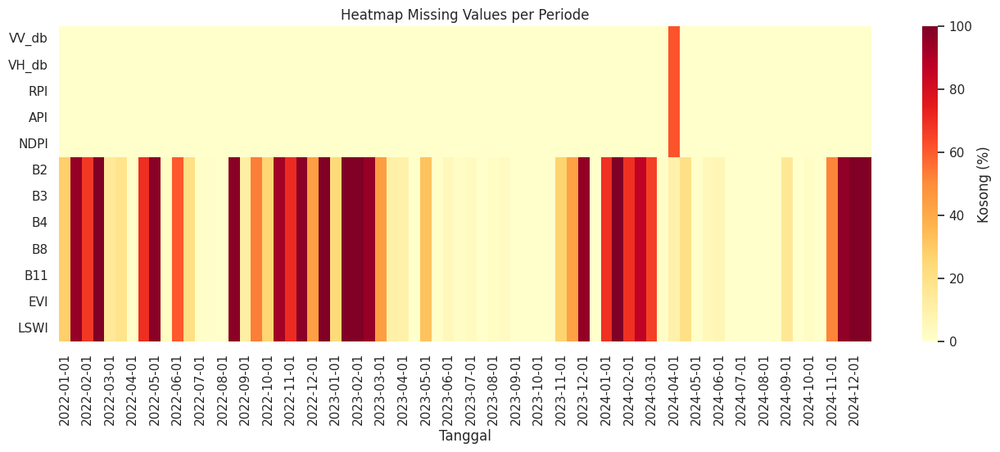


--- C. KORELASI ANTAR FITUR ---


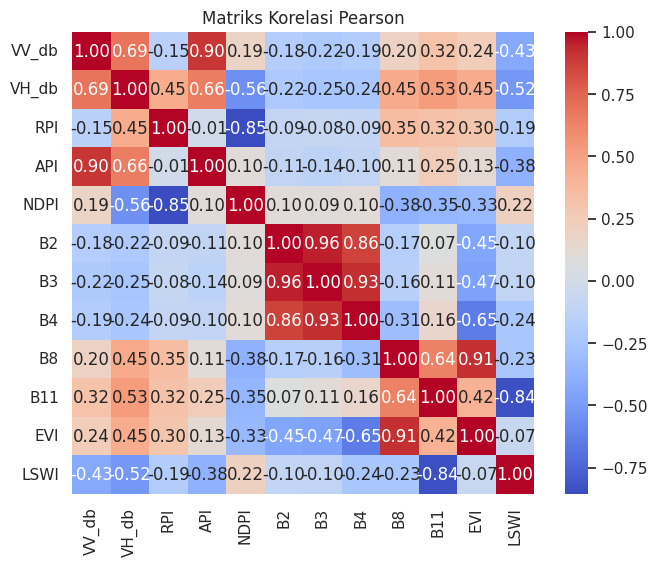


--- D. DISTRIBUSI KELAS LABEL ---


,Jumlah,Persentase (%)
Label_BPS,,
1. Vegetatif Awal,8077,19.18
2. Vegetatif Akhir,5584,13.26
3. Generatif,5293,12.57
3.1 Generatif,1055,2.50
3.2 Generatif,863,2.05
3.3 Generatif,1065,2.53
4. Panen,11261,26.74
5. Persiapan Lahan,8665,20.57
6. Puso,33,0.08


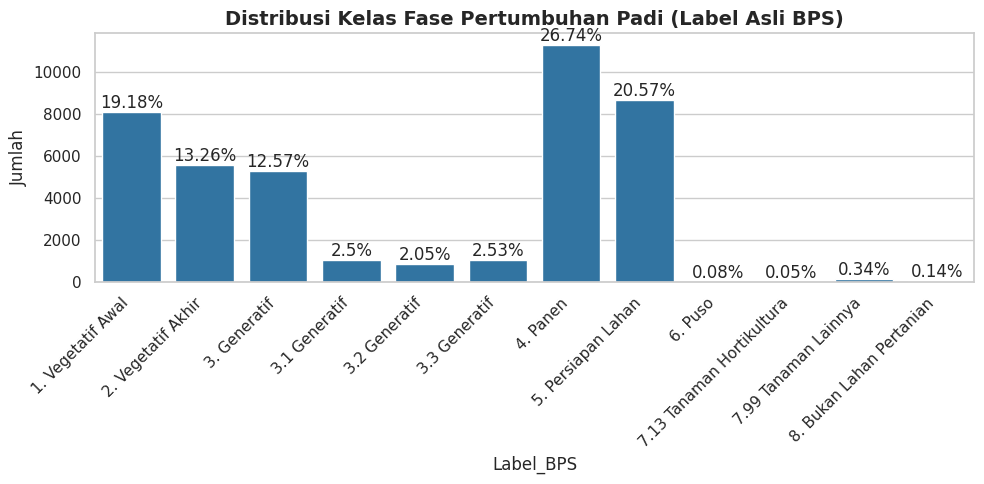


--- E. TREN FASE TANAM PER BULAN ---


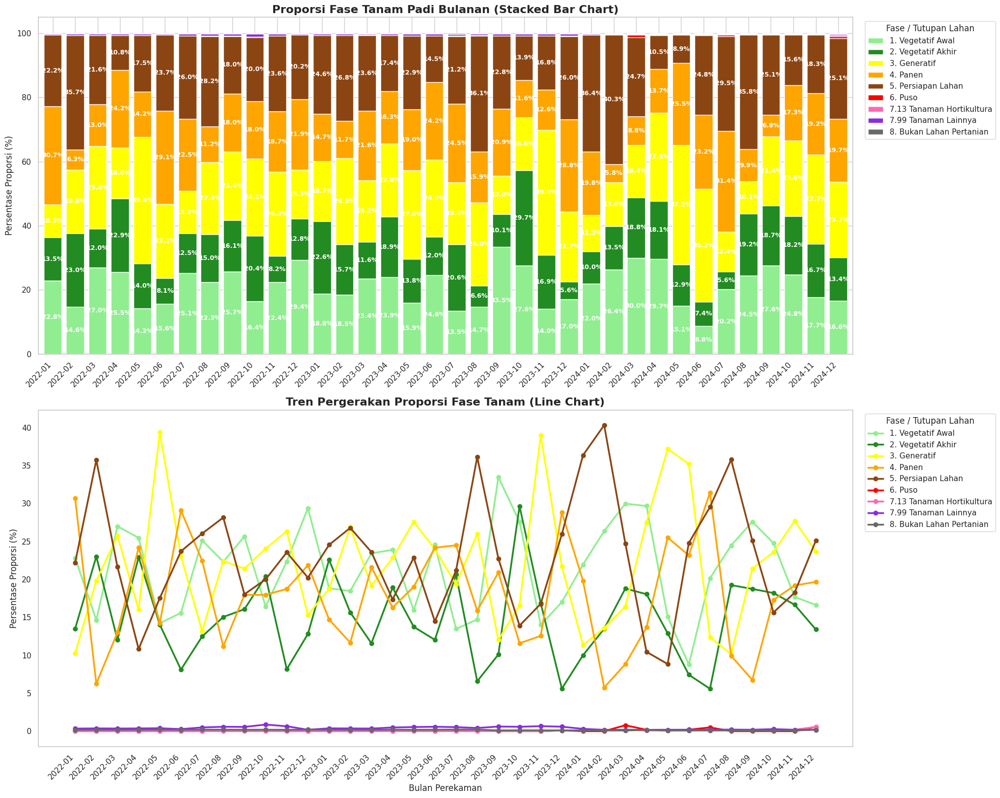


--- F. VISUALISASI BOXPLOT DISTRIBUSI VARIABEL PREDIKTOR ---


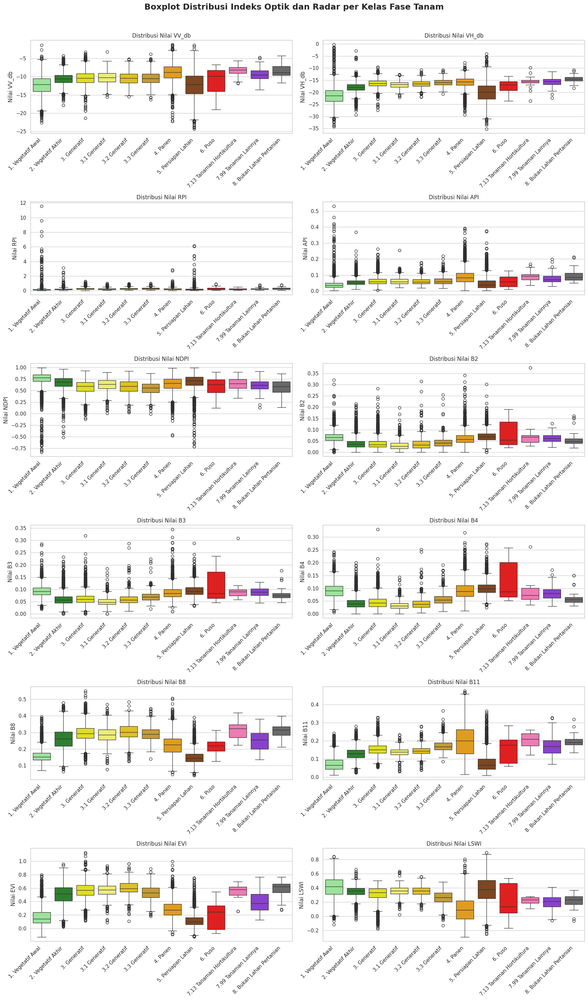


[TABEL] Ringkasan Nilai Median Variabel Prediktor:


,VV_db,VH_db,RPI,API,NDPI,B2,B3,B4,B8,B11,EVI,LSWI
Nama_Fase,,,,,,,,,,,,
1. Vegetatif Awal,-12.144,-21.446,0.126,0.035,0.777,0.066,0.092,0.090,0.152,0.065,0.140,0.418
2. Vegetatif Akhir,-10.604,-17.955,0.188,0.052,0.685,0.036,0.057,0.038,0.260,0.128,0.514,0.356
3. Generatif,-10.423,-16.308,0.261,0.058,0.588,0.034,0.060,0.042,0.292,0.150,0.570,0.337
3.1 Generatif,-10.227,-16.829,0.223,0.059,0.637,0.027,0.048,0.031,0.285,0.138,0.572,0.358
3.2 Generatif,-10.404,-16.467,0.258,0.057,0.591,0.033,0.056,0.037,0.302,0.144,0.594,0.360
3.3 Generatif,-10.506,-15.913,0.287,0.059,0.555,0.041,0.069,0.055,0.288,0.168,0.528,0.267
4. Panen,-8.817,-15.671,0.212,0.082,0.652,0.057,0.084,0.088,0.226,0.199,0.273,0.087
5. Persiapan Lahan,-12.148,-19.927,0.169,0.037,0.712,0.068,0.092,0.098,0.144,0.065,0.097,0.379
6. Puso,-9.892,-16.892,0.228,0.060,0.628,0.055,0.083,0.086,0.219,0.175,0.247,0.133



✅ File dataset bersih berhasil disimpan di: /content/drive/MyDrive/Skripsi/02. Data KSA/Data_KSA_Padi_BPS_Label_Mei_DataBaru.csv


In [5]:
# ==============================================================================
# 4. ANALISIS DESKRIPTIF (EXPLORATORY DATA ANALYSIS)
# ==============================================================================
label_map_bps = {
    1   :'1. Vegetatif Awal',
    2   :'2. Vegetatif Akhir',
    3   :'3. Generatif',
    3.1 :'3.1 Generatif',
    3.2 :'3.2 Generatif',
    3.3 :'3.3 Generatif',
    4   :'4. Panen',
    5   :'5. Persiapan Lahan',
    6   :'6. Puso',
    7.13:'7.13 Tanaman Hortikultura',
    7.99:'7.99 Tanaman Lainnya',
    8   :'8. Bukan Lahan Pertanian',
}

custom_palette_lama = {
    '1. Vegetatif Awal'        : '#90EE90', # Hijau Muda
    '2. Vegetatif Akhir'       : '#228B22', # Hijau Tua
    '3. Generatif'             : '#FFFF00', # Kuning Terang
    '3.1 Generatif'            : '#FFFF66', # Kuning Pucat/Muda
    '3.2 Generatif'            : '#FFD700', # Emas (Gold)
    '3.3 Generatif'            : '#DAA520', # Kuning Tua Keemasan
    '4. Panen'                 : '#FFA500', # Oranye
    '5. Persiapan Lahan'       : '#8B4513', # Coklat
    '6. Puso'                  : '#FF0000', # Merah
    '7.13 Tanaman Hortikultura': '#FF69B4', # Pink
    '7.99 Tanaman Lainnya'     : '#8A2BE2', # Ungu
    '8. Bukan Lahan Pertanian' : '#696969', # Abu-abu
}

fitur_citra = ['VV_db', 'VH_db', 'RPI', 'API', 'NDPI', 'B2', 'B3', 'B4', 'B8', 'B11', 'EVI', 'LSWI']
sns.set_theme(style="whitegrid")


# A. Statistik Deskriptif
# ==============================================================================
print("\n--- A. STATISTIK DESKRIPTIF CITRA ---")
display(df_final[fitur_citra].describe().T[['count', 'mean', 'std', 'min', 'max']].round(3))

# ==============================================================================
# B. Heatmap Missing Values
# ==============================================================================
print("\n--- B. KEKOSONGAN DATA (MISSING VALUES) ---")
missing_pct = df_final.groupby(df_final['Tanggal'].dt.strftime('%Y-%m-%d'), sort=False)[fitur_citra].apply(lambda x: x.isnull().mean() * 100)
plt.figure(figsize=(16, 5))
sns.heatmap(missing_pct.T, cmap="YlOrRd", cbar_kws={'label': 'Kosong (%)'})
plt.title('Heatmap Missing Values per Periode')
plt.show()

# ==============================================================================
# C. Matriks Korelasi
# ==============================================================================
print("\n--- C. KORELASI ANTAR FITUR ---")
plt.figure(figsize=(8, 6))
sns.heatmap(df_final[fitur_citra].corr(), annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Matriks Korelasi Pearson')
plt.show()

# ==============================================================================
# D. Distribusi Kelas (Class Imbalance)
# ==============================================================================
print("\n--- D. DISTRIBUSI KELAS LABEL ---")
label_counts = df_final['Label_BPS'].value_counts(dropna=True).sort_index()
label_counts.index = label_counts.index.map(label_map_bps)
df_dist = pd.DataFrame({'Jumlah': label_counts, 'Persentase (%)': (label_counts / label_counts.sum() * 100).round(2)})
display(df_dist)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=df_dist.index, y=df_dist['Jumlah'], color='#1f77b4')
plt.title('Distribusi Kelas Fase Pertumbuhan Padi (Label Asli BPS)', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
for i, p in enumerate(ax.patches):
    ax.annotate(f"{df_dist['Persentase (%)'].iloc[i]}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom')

plt.tight_layout() # Mencegah teks di bagian bawah terpotong
plt.show()

# ==============================================================================
# E. TREN FASE TANAM PER BULAN
# ==============================================================================
print("\n--- E. TREN FASE TANAM PER BULAN ---")
# 1. Siapkan Data & Hitung Persentase
df_tren = df_final.dropna(subset=['Label_Final']).copy()
df_tren['Nama_Fase'] = df_tren['Label_Final'].map(label_map_bps)
# Crosstab langsung menggunakan dt.strftime di dalam fungsinya
tren_pct = pd.crosstab(df_tren['Tanggal'].dt.strftime('%Y-%m'), df_tren['Nama_Fase'], normalize='index') * 100
# Filter fase (sesuaikan dengan palet & hapus 'Bukan Label Amatan')
fase_tersedia = [f for f in custom_palette_lama.keys() if f in tren_pct.columns and 'Bukan Label' not in f]
tren_pct = tren_pct[fase_tersedia]
warna_list = [custom_palette_lama[f] for f in fase_tersedia]
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(20, 16))

# --- STACKED BAR CHART ---
tren_pct.plot(kind='bar', stacked=True, color=warna_list, width=0.8, ax=axes[0])
axes[0].set_title('Proporsi Fase Tanam Padi Bulanan (Stacked Bar Chart)', fontsize=16, fontweight='bold')
for c in axes[0].containers:
    axes[0].bar_label(c, labels=[f'{v.get_height():.1f}%' if v.get_height() > 3 else '' for v in c], label_type='center', fontsize=9, color='white', fontweight='bold')

# --- LINE CHART ---
tren_pct.plot(kind='line', color=warna_list, marker='o', markersize=6, linewidth=2.5, ax=axes[1])
axes[1].set_title('Tren Pergerakan Proporsi Fase Tanam (Line Chart)', fontsize=16, fontweight='bold')
axes[1].grid(False)
for ax in axes:
    ax.set_ylabel('Persentase Proporsi (%)', fontsize=12)
    ax.set_xlabel('Bulan Perekaman' if ax == axes[1] else '') # Label X hanya untuk grafik bawah
    ax.set_xticks(range(len(tren_pct.index)))
    ax.set_xticklabels(tren_pct.index)
    ax.tick_params(axis='x', rotation=45)
    for tick in ax.get_xticklabels():
        tick.set_ha('right')
    ax.legend(title='Fase / Tutupan Lahan', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ==============================================================================
# F. BOXPLOT DISTRIBUSI VARIABEL PREDIKTOR PER FASE TANAM
# ==============================================================================
print("\n--- F. VISUALISASI BOXPLOT DISTRIBUSI VARIABEL PREDIKTOR ---")
# 1. Siapkan Data (Menggunakan Label Mentah / Label_BPS)
df_box = df_final.dropna(subset=['Label_BPS']).copy()
df_box['Nama_Fase'] = pd.Categorical(df_box['Label_BPS'].map(label_map_bps), categories=list(custom_palette_lama.keys()), ordered=True)
# 2. Setup Kanvas (Grid 6 Baris x 2 Kolom)
fig, axes = plt.subplots(nrows=6, ncols=2, figsize=(18, 30))
axes = axes.flatten()
# 3. Looping Plot Secara Otomatis
for ax, fitur in zip(axes.flatten(), fitur_citra):
    sns.boxplot(data=df_box,
                x='Nama_Fase',
                y=fitur, palette=custom_palette_lama,
                ax=ax,
                showfliers=True,
                hue='Nama_Fase',
                legend=False)
    ax.set(title=f'Distribusi Nilai {fitur}', xlabel='', ylabel=f'Nilai {fitur}')
    ax.tick_params(axis='x', rotation=45)
    for tick in ax.get_xticklabels():
        tick.set_ha('right')
plt.suptitle('Boxplot Distribusi Indeks Optik dan Radar per Kelas Fase Tanam', fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
# 4. Tampilkan Tabel Median
print("\n[TABEL] Ringkasan Nilai Median Variabel Prediktor:")
display(df_box.groupby('Nama_Fase', observed=False)[fitur_citra].median().round(3))

# ==============================================================================
# 5. PENYIMPANAN DATA (DATA EXPORT)
# ==============================================================================
output_path = "/content/drive/MyDrive/Skripsi/02. Data KSA/Data_KSA_Padi_BPS_Label_Mei_DataBaru.csv"
df_final.to_csv(output_path, index=False)
print(f"\n✅ File dataset bersih berhasil disimpan di: {output_path}")

In [6]:
# Melihat daftar nilai yang ada di masing-masing kolom
print("Nilai unik Label BPS:", df_final['Label_BPS'].unique())
print("Nilai unik Label Generatif:", df_final['Label_Generatif'].unique())
print("Nilai unik Label Panen:", df_final['Label_Panen'].unique())

Nilai unik Label BPS: [ nan 5.   1.   3.   2.   4.   3.3  7.99 3.1  3.2  6.   8.   7.13]
Nilai unik Label Generatif: [ nan 5.   1.   3.   2.   4.   7.99 6.   8.   7.13]
Nilai unik Label Panen: [ nan 5.   1.   3.   2.   4.   9.   7.99 6.   8.   7.13]


# **Data Periode yang Diteliti (Mei–Oktober 2023 & 2024)**

## *Load & Filter Data*

In [7]:
# ==============================================================================
# 1. IMPORT LIBRARY & KONFIGURASI UMUM
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import savgol_filter
from IPython.display import display

# Konfigurasi Visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# # Konfigurasi Path Data & Variabel
path_data = '/content/drive/MyDrive/Skripsi/02. Data KSA/Data_KSA_Padi_BPS_Label_Mei_DataBaru.csv'
fitur_citra = ['VV_db', 'VH_db', 'RPI', 'NDPI', 'API', 'B2', 'B3', 'B4', 'B8', 'B11', 'EVI', 'LSWI']

label_map_bps = {
    1   :'1. Vegetatif Awal',
    2   :'2. Vegetatif Akhir',
    3   :'3. Generatif',
    3.1 :'3.1 Generatif',
    3.2 :'3.2 Generatif',
    3.3 :'3.3 Generatif',
    4   :'4. Panen',
    5   :'5. Persiapan Lahan',
    6   :'6. Puso',
    7.13:'7.13 Tanaman Hortikultura',
    7.99:'7.99 Tanaman Lainnya',
    8   :'8. Bukan Lahan Pertanian',
    # 9   :'9. Bera'
}

custom_palette_lama = {
    '1. Vegetatif Awal'        : '#90EE90', # Hijau Muda
    '2. Vegetatif Akhir'       : '#228B22', # Hijau Tua
    '3. Generatif'             : '#FFFF00', # Kuning
    '3.1 Generatif'            : '#FFFF66', # Kuning Pucat/Muda
    '3.2 Generatif'            : '#FFD700', # Emas (Gold)
    '3.3 Generatif'            : '#DAA520', # Kuning Tua Keemasan
    '4. Panen'                 : '#FFA500', # Oranye
    '5. Persiapan Lahan'       : '#8B4513', # Coklat
    '6. Puso'                  : '#FF0000', # Merah
    '7.13 Tanaman Hortikultura': '#FF69B4', # Pink
    '7.99 Tanaman Lainnya'     : '#8A2BE2', # Ungu
    '8. Bukan Lahan Pertanian' : '#696969', # Abu-abu
    # '9. Bera'                  : '#D2B48C'  # Khaki
}

# Konfigurasi Filter Waktu
tahun_fokus = [2023, 2024]              # Bisa diubah, misal: [2023] atau [2024]
bulan_fokus = [5, 6, 7, 8, 9, 10]       # Fix: Hanya Mei s/d Oktober

# ==============================================================================
# 2. PERSIAPAN DATA (LOAD & FILTERING)
# ==============================================================================
print("⏳ Sedang memuat data...")
df_final = pd.read_csv(path_data)
df_final['Tanggal'] = pd.to_datetime(df_final['Tanggal'])
df_final['Tahun'] = df_final['Tanggal'].dt.year
df_final['Bulan'] = df_final['Tanggal'].dt.month

# Eksekusi filter waktu & pembuatan ID unik
kondisi_tahun = df_final['Tahun'].isin(tahun_fokus)
kondisi_bulan = df_final['Bulan'].isin(bulan_fokus)
df_final = df_final[kondisi_tahun & kondisi_bulan].copy()

# Pembuatan ID_Titik dan pengurutan kronologis
df_final['ID_Titik'] = df_final['TitikAmatX'].astype(str) + "_" + df_final['TitikAmatY'].astype(str)
df_final = df_final.sort_values(by=['TitikAmatX', 'TitikAmatY', 'Tahun', 'Tanggal']).reset_index(drop=True)

print(f"=== DATA BERHASIL DIMUAT DAN DIFILTER (TAHUN {tahun_fokus}, BULAN {bulan_fokus[0]}-{bulan_fokus[-1]}) ===")
display(df_final.head(3))

⏳ Sedang memuat data...
=== DATA BERHASIL DIMUAT DAN DIFILTER (TAHUN [2023, 2024], BULAN 5-10) ===


,TitikAmatX,TitikAmatY,Tanggal,Periode,VV_db,VH_db,RPI,NDPI,API,B2,...,NDVI,EVI,LSWI,Label_BPS,Label_Generatif,Label_Panen,Label_Final,Tahun,Bulan,ID_Titik
0,107.089107,-6.001937,2023-05-01,P1,-8.096517,-14.746345,0.216280,0.644358,0.094265,0.0599,...,0.344666,0.237633,-0.044565,NaN,NaN,NaN,NaN,2023,5,107.0891067_-6.001936667
1,107.089107,-6.001937,2023-05-16,P2,-7.756814,-11.945774,0.381157,0.448061,0.115753,0.0720,...,0.330006,0.251458,-0.050861,4.0,4.0,4.0,4.0,2023,5,107.0891067_-6.001936667
2,107.089107,-6.001937,2023-06-01,P1,-9.174275,-15.915172,0.269178,0.603295,0.077923,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2023,6,107.0891067_-6.001936667


In [8]:
# ==============================================================================
# RAPOR DATA AWAL (SEBELUM PREPROCESSING LABEL & IMPUTASI CITRA)
# ==============================================================================
print("\n" + "="*60)
print("RAPOR DATA MENTAH (SEBELUM PREPROCESSING)")
print("="*60 + "\n")

# 1. Statistik Dasar Observasi
total_baris = len(df_final)
total_titik = df_final['ID_Titik'].nunique()
print(f"1. Total Observasi       : {total_baris} baris")
print(f"2. Total Titik Unik      : {total_titik} titik")

# 2. Distribusi per Tahun
print("\n3. Rincian Titik per Tahun:")
for tahun, jumlah in df_final.groupby('Tahun')['ID_Titik'].nunique().items():
    print(f"   - Tahun {tahun} : {jumlah} titik")

# 3. Ketersediaan Kelas Target
print("\n4. Distribusi Label KSA Asli (Termasuk Anomali):")
total_label_terisi = df_final['Label_BPS'].notna().sum()
label_counts = df_final['Label_BPS'].value_counts(dropna=False).sort_index()

for label, count in label_counts.items():
    if pd.isna(label):
        print(f"   - {'Data Label Kosong (P1)':<26}: {count} observasi (Sengaja Dikosongkan)")
    else:
        pct = round((count / total_label_terisi) * 100, 2)
        nama = label_map_bps.get(label, str(label))
        print(f"   - {nama:<26}: {count} observasi ({pct}%)")

# 4. Status Missing Value pada Fitur Citra
print("\n5. Status Kekosongan Data Citra (Missing Values):")
fitur_valid = [col for col in fitur_citra if col in df_final.columns]

if fitur_valid:
    missing_citra = df_final[fitur_valid].isnull().sum()
    if missing_citra.sum() == 0:
        print("Tidak ada data citra yang bolong.")
    else:
        print("Terdapat nilai kosong (NaN) pada data citra:")
        # Hanya print fitur yang benar-benar ada missing valuenya
        for fitur, missing in missing_citra[missing_citra > 0].items():
            pct_missing = round((missing / total_baris) * 100, 2)
            print(f"      - Band/Indeks {fitur:<4} : {missing} baris kosong ({pct_missing}%)")
else:
    print("Kolom fitur citra tidak ditemukan di data ini.")
print("\n" + "="*60)


RAPOR DATA MENTAH (SEBELUM PREPROCESSING)

1. Total Observasi       : 28080 baris
2. Total Titik Unik      : 1170 titik

3. Rincian Titik per Tahun:
   - Tahun 2023 : 1170 titik
   - Tahun 2024 : 1170 titik

4. Distribusi Label KSA Asli (Termasuk Anomali):
   - 1. Vegetatif Awal         : 2509 observasi (17.87%)
   - 2. Vegetatif Akhir        : 1736 observasi (12.36%)
   - 3. Generatif              : 1242 observasi (8.85%)
   - 3.1 Generatif             : 544 observasi (3.87%)
   - 3.2 Generatif             : 361 observasi (2.57%)
   - 3.3 Generatif             : 558 observasi (3.97%)
   - 4. Panen                  : 4301 observasi (30.63%)
   - 5. Persiapan Lahan        : 2711 observasi (19.31%)
   - 6. Puso                   : 11 observasi (0.08%)
   - 7.13 Tanaman Hortikultura : 6 observasi (0.04%)
   - 7.99 Tanaman Lainnya      : 45 observasi (0.32%)
   - 8. Bukan Lahan Pertanian  : 16 observasi (0.11%)
   - Data Label Kosong (P1)    : 14040 observasi (Sengaja Dikosongkan)

5. Sta

## *Analisis Data*


1. ANALISIS DESKRIPTIF STATISTIK


,count,mean,std,min,25%,50%,75%,max
VV_db,28046.0,-10.856652,2.591414,-21.791306,-12.283708,-10.668260,-9.158117,-1.117027
VH_db,28046.0,-18.209288,3.357864,-35.256296,-19.966514,-17.477393,-15.823254,-9.239222
RPI,28046.0,0.218376,0.123861,0.004538,0.129228,0.193913,0.280617,1.386119
NDPI,28046.0,0.658337,0.151804,-0.161819,0.564383,0.676832,0.771673,0.990966
API,28046.0,0.058654,0.032162,0.004327,0.037098,0.053396,0.074372,0.409123
B2,27123.0,0.057779,0.025640,0.000000,0.039700,0.056500,0.073800,0.374000
B3,27123.0,0.082003,0.025883,0.000000,0.063800,0.081100,0.098300,0.307800
B4,27123.0,0.078876,0.035979,0.000000,0.050475,0.078950,0.102600,0.280350
B8,27123.0,0.218220,0.073810,0.039900,0.153400,0.215000,0.275300,0.523400
B11,27123.0,0.137835,0.081297,0.007800,0.074150,0.127850,0.175375,0.476450



2. HEATMAP PERSENTASE DATA KOSONG PER PERIODE


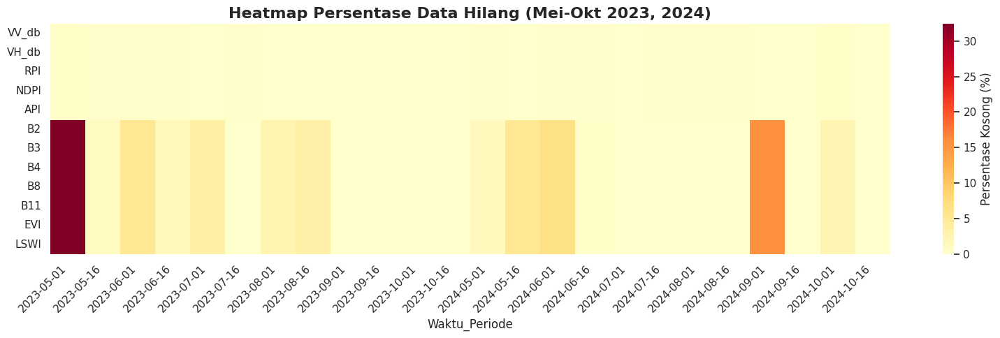


3. MATRIKS KORELASI ANTAR FITUR


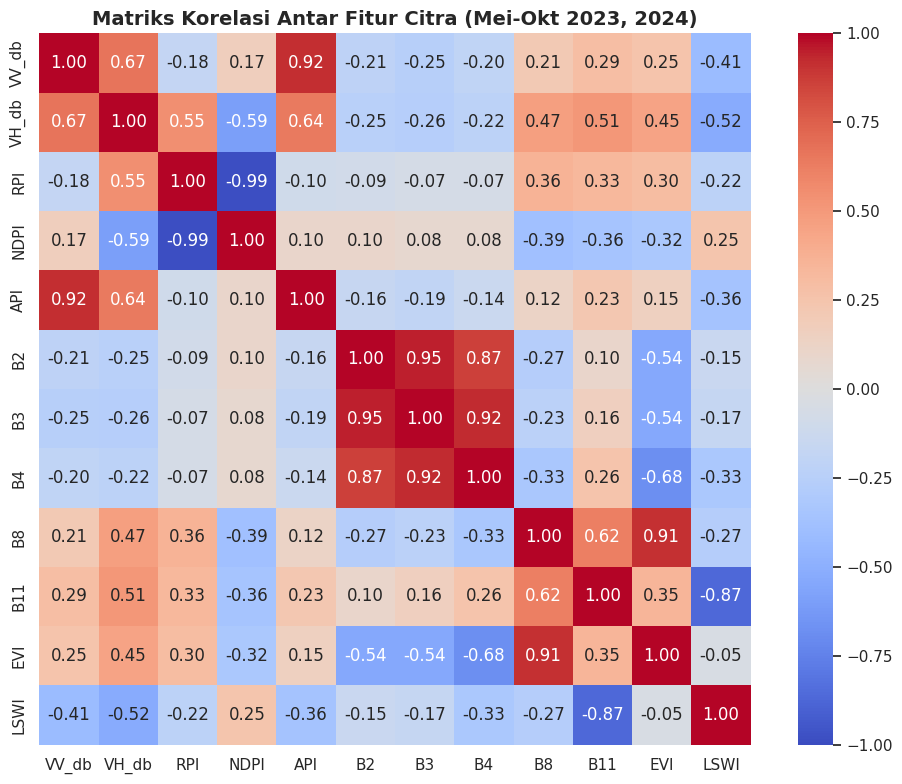


⚖️ 4. PERBANDINGAN DISTRIBUSI KELAS (SEBELUM & SESUDAH)

[TABEL] SEBELUM PENGGABUNGAN:


,Jumlah,Persentase (%)
Nama_Fase,,
1. Vegetatif Awal,2509,17.87
2. Vegetatif Akhir,1736,12.36
3. Generatif,1242,8.85
3.1 Generatif,544,3.87
3.2 Generatif,361,2.57
3.3 Generatif,558,3.97
4. Panen,4301,30.63
5. Persiapan Lahan,2711,19.31
6. Puso,11,0.08



[TABEL] SESUDAH PENGGABUNGAN:


,Jumlah,Persentase (%)
Nama_Fase,,
1. Vegetatif Awal,2509,17.87
2. Vegetatif Akhir,1736,12.36
3. Generatif,2705,19.27
4. Panen,2325,16.56
5. Persiapan Lahan,2711,19.31
8. Bukan Lahan Pertanian,16,0.11
9. Bera,1976,14.07
99. Bukan Label Amatan,62,0.44


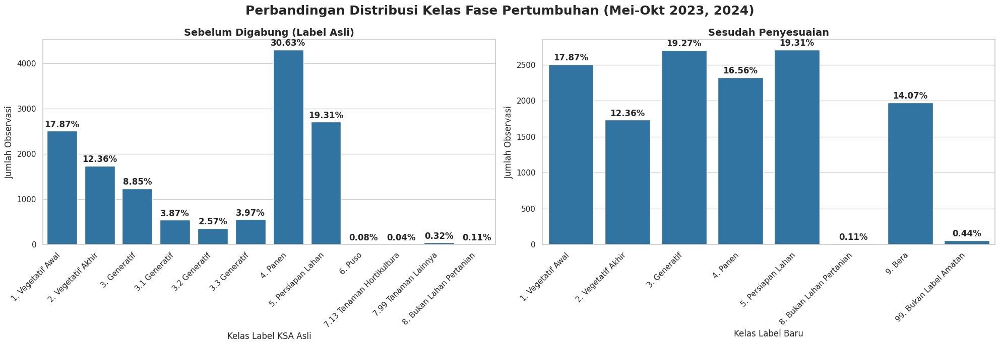


5. TREN FASE TANAM PER BULAN TIME-SERIES


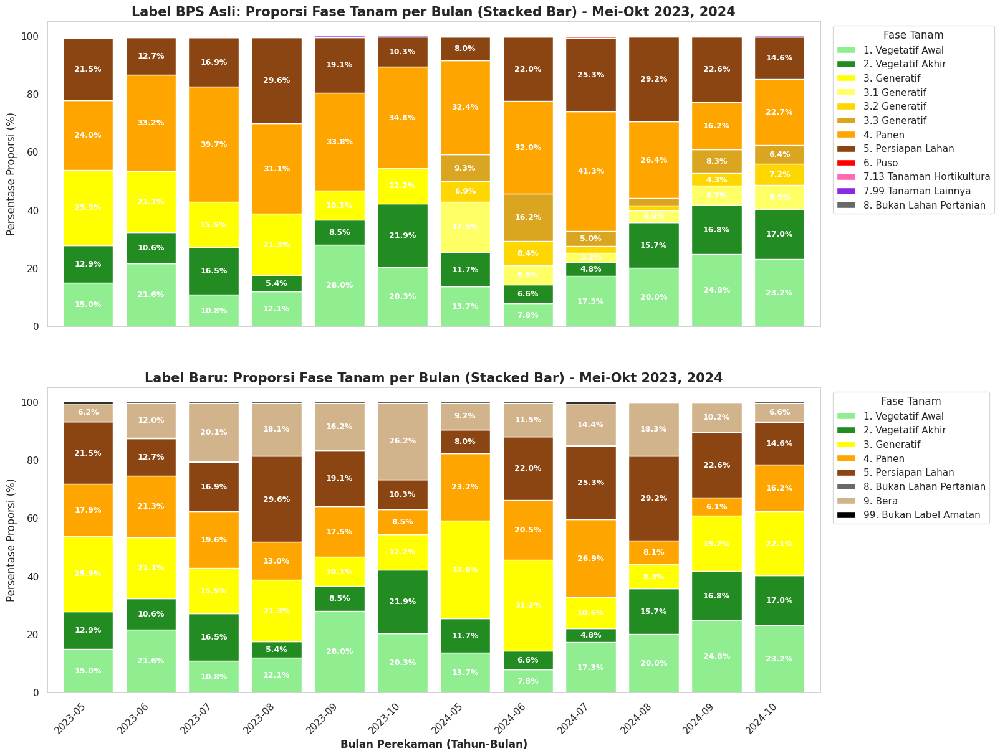

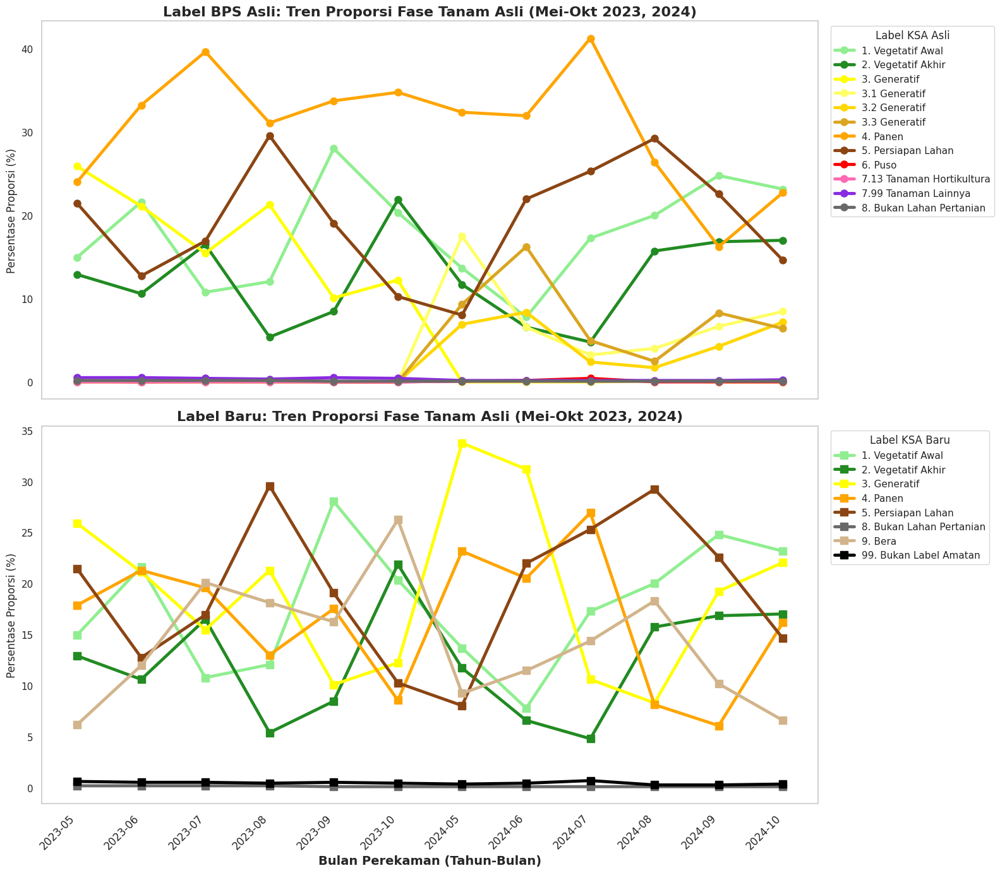


6. VISUALISASI BOXPLOT OVERALL PER VARIABEL (GLOBAL)



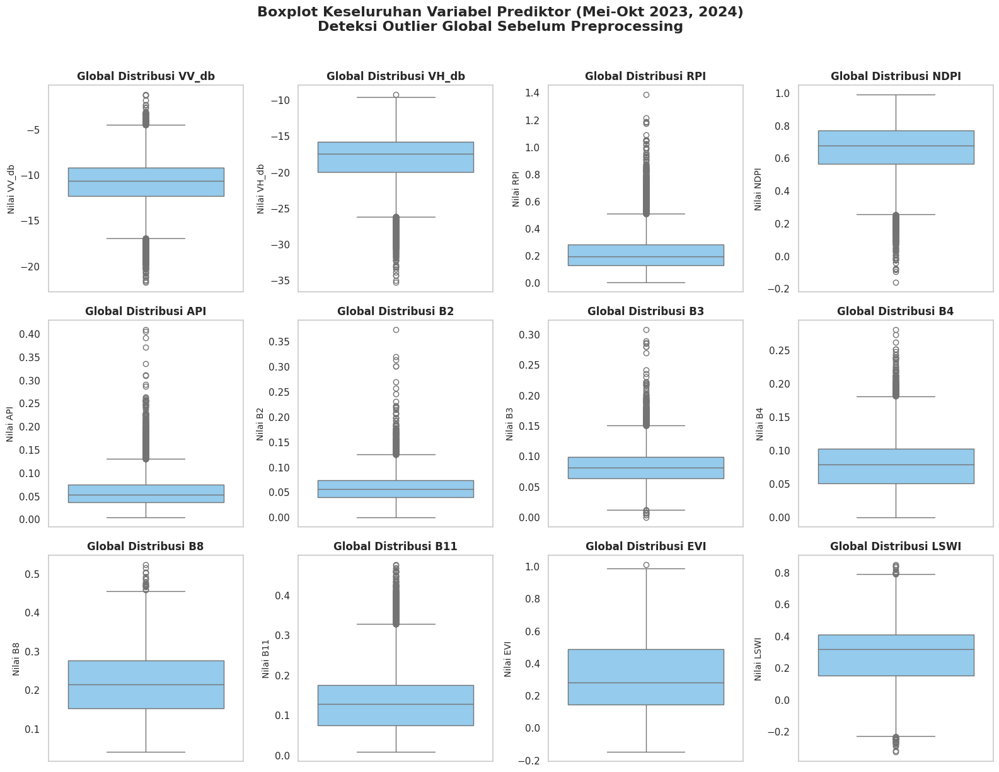


7. VISUALISASI BOXPLOT DISTRIBUSI FITUR PER FASE TANAM



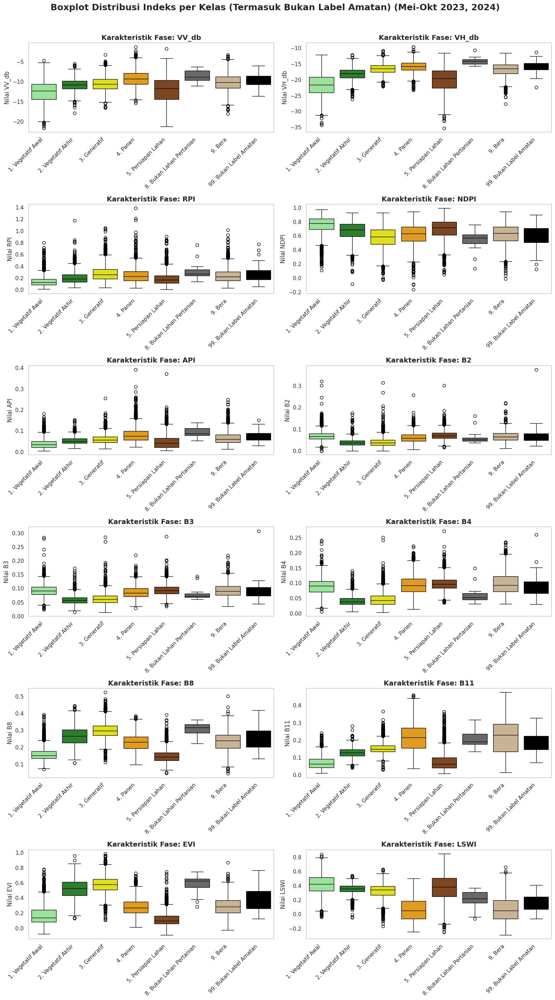


8. VISUALISASI HISTOGRAM OVERALL PER VARIABEL (GLOBAL)



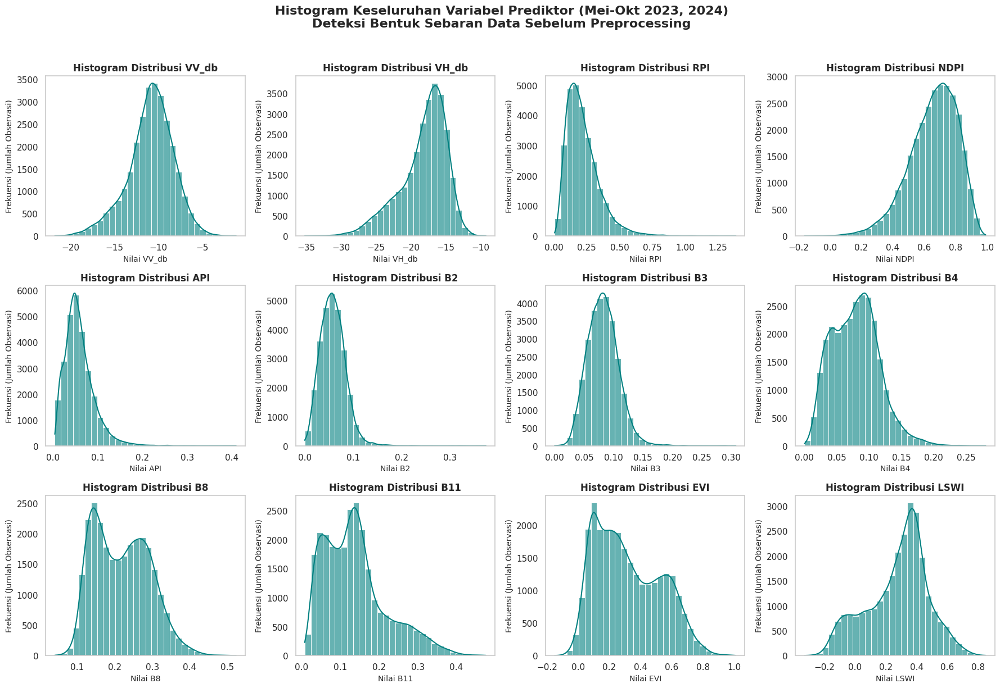

In [9]:
# ==============================================================================
# DEFINISI MAPPING & PALET WARNA BARU
# ==============================================================================
teks_tahun = ", ".join(map(str, tahun_fokus)) if isinstance(tahun_fokus, list) else tahun_fokus

label_map_baru = {
    1   :'1. Vegetatif Awal',
    2   :'2. Vegetatif Akhir',
    3   :'3. Generatif',
    4   :'4. Panen',
    5   :'5. Persiapan Lahan',
    6   :'6. Puso',
    8   :'8. Bukan Lahan Pertanian',
    9   :'9. Bera',
    99  :'99. Bukan Label Amatan'
}

custom_palette_baru = {
    '1. Vegetatif Awal'        : '#90EE90',
    '2. Vegetatif Akhir'       : '#228B22',
    '3. Generatif'             : '#FFFF00',
    '4. Panen'                 : '#FFA500',
    '5. Persiapan Lahan'       : '#8B4513',
    '8. Bukan Lahan Pertanian' : '#696969',
    '9. Bera'                  : '#D2B48C',
    '99. Bukan Label Amatan'   : '#000000'
}

# ==============================================================================
# 1. ANALISIS DESKRIPTIF STATISTIK
# ==============================================================================
print("\n" + "="*60)
print("1. ANALISIS DESKRIPTIF STATISTIK")
print("="*60)
desc_stats = df_final[fitur_citra].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
display(desc_stats)

# ==============================================================================
# 2. HEATMAP MISSING VALUE PER PERIODE
# ==============================================================================
print("\n" + "="*60)
print("2. HEATMAP PERSENTASE DATA KOSONG PER PERIODE")
print("="*60)
df_final['Waktu_Periode'] = df_final['Tanggal'].dt.strftime('%Y-%m-%d')

missing_per_periode = df_final.groupby('Waktu_Periode', sort=False)[fitur_citra].apply(lambda x: (x.isnull().mean() * 100)).round(2)

plt.figure(figsize=(16, 5))
sns.heatmap(missing_per_periode.T, cmap="YlOrRd", cbar_kws={'label': 'Persentase Kosong (%)'})
plt.title(f'Heatmap Persentase Data Hilang (Mei-Okt {teks_tahun})', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. MATRIKS KORELASI ANTAR FITUR
# ==============================================================================
print("\n" + "="*60)
print("3. MATRIKS KORELASI ANTAR FITUR")
print("="*60)
plt.figure(figsize=(10, 8))
sns.heatmap(df_final[fitur_citra].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, square=True)
plt.title(f'Matriks Korelasi Antar Fitur Citra (Mei-Okt {teks_tahun})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. ANALISIS KETIDAKSEIMBANGAN KELAS (CLASS IMBALANCE)
# ==============================================================================
print("\n" + "="*60)
print("⚖️ 4. PERBANDINGAN DISTRIBUSI KELAS (SEBELUM & SESUDAH)")
print("="*60)

# 1. Ekstraksi Data SEBELUM Digabung
df_sebelum = df_final.copy()
df_sebelum['Nama_Fase'] = df_sebelum['Label_BPS'].map(label_map_bps)
dist_sebelum = df_sebelum['Nama_Fase'].value_counts(dropna=True).sort_index()
df_dist_sebelum = pd.DataFrame({'Jumlah': dist_sebelum, 'Persentase (%)': (dist_sebelum / dist_sebelum.sum() * 100).round(2)})

# PROSES PENGGABUNGAN & PENYESUAIAN LABEL
# Langkah 1: Anomali diubah menjadi 99 terlebih dahulu
df_final['Label_Final'] = df_final['Label_Final'].replace({6: 99, 7.13: 99, 7.99: 99})

# 2. Ekstraksi Data SESUDAH Digabung
df_sesudah = df_final.copy()
df_sesudah['Nama_Fase'] = df_sesudah['Label_Final'].map(label_map_baru)
dist_sesudah = df_sesudah['Nama_Fase'].value_counts(dropna=True).sort_index()
df_dist_sesudah = pd.DataFrame({'Jumlah': dist_sesudah, 'Persentase (%)': (dist_sesudah / dist_sesudah.sum() * 100).round(2)})

# Menampilkan Tabel
print("\n[TABEL] SEBELUM PENGGABUNGAN:")
display(df_dist_sebelum)
print("\n[TABEL] SESUDAH PENGGABUNGAN:")
display(df_dist_sesudah)

# 3. Visualisasi Grafik Berdampingan
fig, axes = plt.subplots(1, 2, figsize=(20, 7))

def plot_distribusi(df_dist, ax, judul, xlabel):
    sns.barplot(x=df_dist.index, y=df_dist['Jumlah'], color='#1f77b4', ax=ax)
    ax.set_title(judul, fontsize=14, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel('Jumlah Observasi', fontsize=12)
    ax.tick_params(axis='x', rotation=45)

    for tick in ax.get_xticklabels():
        tick.set_ha('right')
    for i, p in enumerate(ax.patches):
        ax.annotate(f"{df_dist['Persentase (%)'].iloc[i]}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 9),
                    textcoords='offset points', fontweight='bold')

plot_distribusi(df_dist_sebelum, axes[0], 'Sebelum Digabung (Label Asli)', 'Kelas Label KSA Asli')
plot_distribusi(df_dist_sesudah, axes[1], 'Sesudah Penyesuaian', 'Kelas Label Baru')

plt.suptitle(f'Perbandingan Distribusi Kelas Fase Pertumbuhan (Mei-Okt {teks_tahun})', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. TREN FASE TANAM PER BULAN (BAR & LINE CHART)
# ==============================================================================
print("\n" + "="*60)
print("5. TREN FASE TANAM PER BULAN TIME-SERIES")
print("="*60)

# A. PERSIAPAN DATA: SEBELUM DIGABUNG
df_tren_seb = df_sebelum.dropna(subset=['Label_BPS']).copy()
df_tren_seb['Bulan_Tahun'] = df_tren_seb['Tanggal'].dt.strftime('%Y-%m')

urutan_seb = list(custom_palette_lama.keys())
df_tren_seb['Nama_Fase'] = pd.Categorical(df_tren_seb['Nama_Fase'], categories=urutan_seb, ordered=True)

tren_seb = df_tren_seb.groupby(['Bulan_Tahun', 'Nama_Fase'], observed=False).size().unstack(fill_value=0)
tren_seb_pct = tren_seb.div(tren_seb.sum(axis=1), axis=0) * 100
warna_seb = [custom_palette_lama[col] for col in tren_seb_pct.columns]

# B. PERSIAPAN DATA: SESUDAH DIGABUNG
df_tren_ses = df_sesudah.dropna(subset=['Label_Final']).copy()
df_tren_ses['Bulan_Tahun'] = df_tren_ses['Tanggal'].dt.strftime('%Y-%m')

urutan_ses = list(custom_palette_baru.keys())
df_tren_ses['Nama_Fase'] = pd.Categorical(df_tren_ses['Nama_Fase'], categories=urutan_ses, ordered=True)

tren_ses = df_tren_ses.groupby(['Bulan_Tahun', 'Nama_Fase'], observed=False).size().unstack(fill_value=0)
tren_ses_pct = tren_ses.div(tren_ses.sum(axis=1), axis=0) * 100
warna_ses = [custom_palette_baru[col] for col in tren_ses_pct.columns]

# --- 1. BAR CHART ---
fig, axes = plt.subplots(2, 1, figsize=(16, 14), sharex=True)

tren_seb_pct.plot(kind='bar', stacked=True, color=warna_seb, width=0.8, ax=axes[0])
axes[0].set_title(f'Label BPS Asli: Proporsi Fase Tanam per Bulan (Stacked Bar) - Mei-Okt {teks_tahun}', fontsize=15, fontweight='bold')
axes[0].set_ylabel('Persentase Proporsi (%)', fontsize=12)
axes[0].legend(title='Fase Tanam', bbox_to_anchor=(1.01, 1), loc='upper left')

for c in axes[0].containers:
    labels = [f'{v.get_height():.1f}%' if v.get_height() > 3 else '' for v in c]
    axes[0].bar_label(c, labels=labels, label_type='center', fontsize=9, color='white', fontweight='bold')
    axes[0].grid(False)

tren_ses_pct.plot(kind='bar', stacked=True, color=warna_ses, width=0.8, ax=axes[1])
axes[1].set_title(f'Label Baru: Proporsi Fase Tanam per Bulan (Stacked Bar) - Mei-Okt {teks_tahun}', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Bulan Perekaman (Tahun-Bulan)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Persentase Proporsi (%)', fontsize=12)
axes[1].legend(title='Fase Tanam', bbox_to_anchor=(1.01, 1), loc='upper left')

for c in axes[1].containers:
    labels = [f'{v.get_height():.1f}%' if v.get_height() > 3 else '' for v in c]
    axes[1].bar_label(c, labels=labels, label_type='center', fontsize=9, color='white', fontweight='bold')
    axes[1].grid(False)

# Pastikan rotasi label sumbu X rapi untuk grafik bawah
axes[1].tick_params(axis='x', rotation=45)
for tick in axes[1].get_xticklabels():
    tick.set_ha('right')

# --- 2. LINE CHART ---
fig, axes = plt.subplots(2, 1, figsize=(16, 14), sharex=True)

tren_seb_pct.plot(kind='line', ax=axes[0], color=warna_seb, linewidth=3.5, marker='o', markersize=8)
axes[0].set_title(f'Label BPS Asli: Tren Proporsi Fase Tanam Asli (Mei-Okt {teks_tahun})', fontsize=16, fontweight='bold')
axes[0].set_ylabel('Persentase Proporsi (%)', fontsize=12)
axes[0].legend(title='Label KSA Asli', bbox_to_anchor=(1.01, 1), loc='upper left')
axes[0].grid(False)

tren_ses_pct.plot(kind='line', ax=axes[1], color=warna_ses, linewidth=3.5, marker='s', markersize=8)
axes[1].set_title(f'Label Baru: Tren Proporsi Fase Tanam Asli (Mei-Okt {teks_tahun})', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Bulan Perekaman (Tahun-Bulan)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Persentase Proporsi (%)', fontsize=12)
axes[1].legend(title='Label KSA Baru', bbox_to_anchor=(1.01, 1), loc='upper left')
axes[1].grid(False)

plt.xticks(range(len(tren_ses_pct.index)), tren_ses_pct.index, rotation=45, ha='right', fontsize=12)
plt.tight_layout()
plt.show()

# ==============================================================================
# 6. BOXPLOT DISTRIBUSI FITUR OVERALL (MENDETEKSI GLOBAL OUTLIER)
# ==============================================================================
print("\n" + "="*60)
print("6. VISUALISASI BOXPLOT OVERALL PER VARIABEL (GLOBAL)")
print("="*60 + "\n")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

# Looping untuk membuat boxplot global tiap fitur citra
for i, fitur in enumerate(fitur_citra):
    if fitur in df_final.columns:
        sns.boxplot(
            y=df_final[fitur],
            ax=axes[i],
            color='#87CEFA',
            showfliers=True
        )
        axes[i].set_title(f'Global Distribusi {fitur}', fontsize=12, fontweight='bold')
        axes[i].set_ylabel(f'Nilai {fitur}', fontsize=10)
        axes[i].grid(False)

plt.suptitle(f'Boxplot Keseluruhan Variabel Prediktor (Mei-Okt {teks_tahun})\nDeteksi Outlier Global Sebelum Preprocessing',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 7. BOXPLOT DISTRIBUSI FITUR PER FASE TANAM (KARAKTERISTIK KELAS LENGKAP)
# ==============================================================================
print("\n" + "="*60)
print("7. VISUALISASI BOXPLOT DISTRIBUSI FITUR PER FASE TANAM")
print("="*60 + "\n")

# 1. Siapkan data
df_box = df_final.dropna(subset=['Label_Final']).copy()
df_box['Nama_Fase'] = df_box['Label_Final'].map(label_map_baru)
urutan_fase = list(custom_palette_baru.keys())
df_box['Nama_Fase'] = pd.Categorical(df_box['Nama_Fase'], categories=urutan_fase, ordered=True)

fig, axes = plt.subplots(6, 2, figsize=(16, 28))
axes = axes.flatten()
for i, fitur in enumerate(fitur_citra):
    if fitur in df_box.columns:
        sns.boxplot(
            data=df_box,
            x='Nama_Fase',
            y=fitur,
            hue='Nama_Fase',
            palette=custom_palette_baru,
            ax=axes[i],
            showfliers=True,
            legend=False
        )

        # Pengaturan label dan judul tiap subplot
        axes[i].set_title(f'Karakteristik Fase: {fitur}', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('')
        axes[i].set_ylabel(f'Nilai {fitur}', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].grid(False)

        # Rata kanan untuk teks sumbu X agar rapi terbaca
        for tick in axes[i].get_xticklabels():
            tick.set_ha('right')

plt.suptitle(f'Boxplot Distribusi Indeks per Kelas (Termasuk Bukan Label Amatan) (Mei-Okt {teks_tahun})',
             fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# # ==============================================================================
# # RINGKASAN MEDIAN UNTUK LAMPIRAN/TABEL SKRIPSI
# # ==============================================================================
# print("\n📋 Ringkasan Nilai Median per Fase (Format siap salin ke naskah skripsi):")
# ringkasan_median = df_box.groupby('Nama_Fase', observed=False)[fitur_citra].median().round(3)
# display(ringkasan_median)

# ==============================================================================
# 8. HISTOGRAM DISTRIBUSI FITUR OVERALL (MENDETEKSI BENTUK SEBARAN GLOBAL)
# ==============================================================================
print("\n" + "="*60)
print("8. VISUALISASI HISTOGRAM OVERALL PER VARIABEL (GLOBAL)")
print("="*60 + "\n")

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

# Looping untuk membuat histogram global tiap fitur citra
for i, fitur in enumerate(fitur_citra):
    if fitur in df_final.columns:
        # Gunakan sns.histplot dengan kde=True untuk melihat kurva kepadatannya
        sns.histplot(
            data=df_final,
            x=fitur,
            ax=axes[i],
            color='teal',
            bins=30,          # Mengatur jumlah batang histogram
            kde=True,         # Menampilkan garis kurva lonceng
            alpha=0.6         # Tingkat transparansi batang
        )
        axes[i].set_title(f'Histogram Distribusi {fitur}', fontsize=12, fontweight='bold')
        axes[i].set_xlabel(f'Nilai {fitur}', fontsize=10)
        axes[i].set_ylabel('Frekuensi (Jumlah Observasi)', fontsize=10)
        axes[i].grid(False)

plt.suptitle(f'Histogram Keseluruhan Variabel Prediktor (Mei-Okt {teks_tahun})\nDeteksi Bentuk Sebaran Data Sebelum Preprocessing',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

*Kruskall Wallis*

In [10]:
!pip install scikit_posthocs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.9 MB/s eta 0:00:00



🔬 9. UJI STATISTIK BEDA NYATA ANTAR KELAS ASLI (Kruskal-Wallis & Nemenyi)
Total data dievaluasi: 14040 baris
Tingkat Signifikansi (Alpha) = 0.05


------------------------------------------------------------
▶ FITUR: VV_db
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2329.72, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


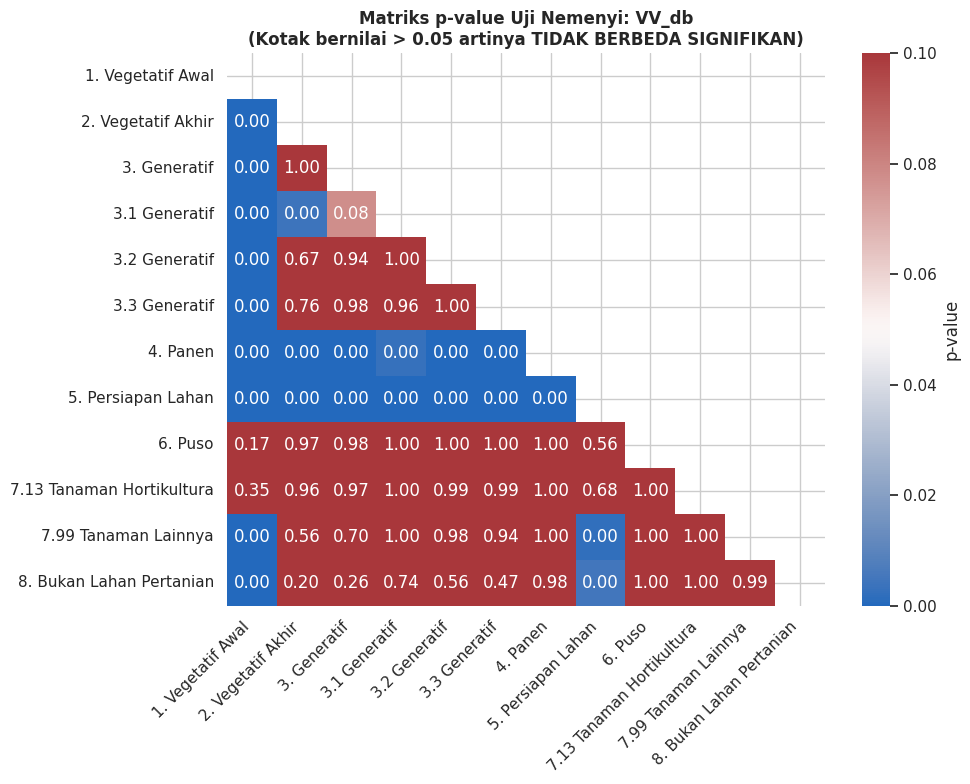


------------------------------------------------------------
▶ FITUR: VH_db
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 5314.31, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


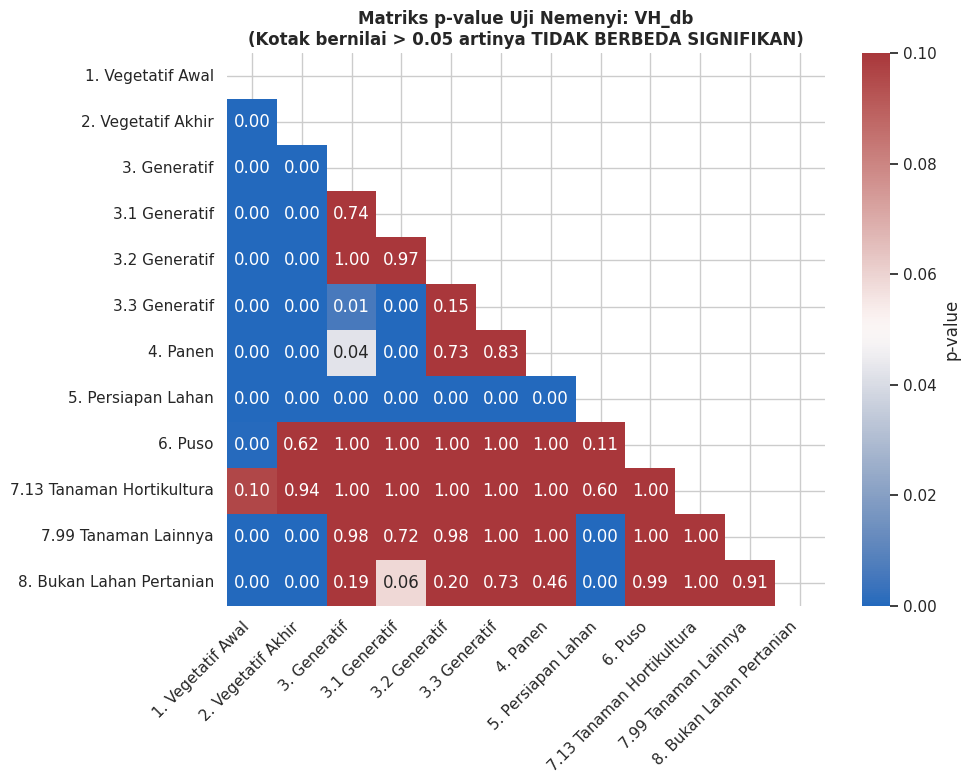


------------------------------------------------------------
▶ FITUR: RPI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2388.24, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


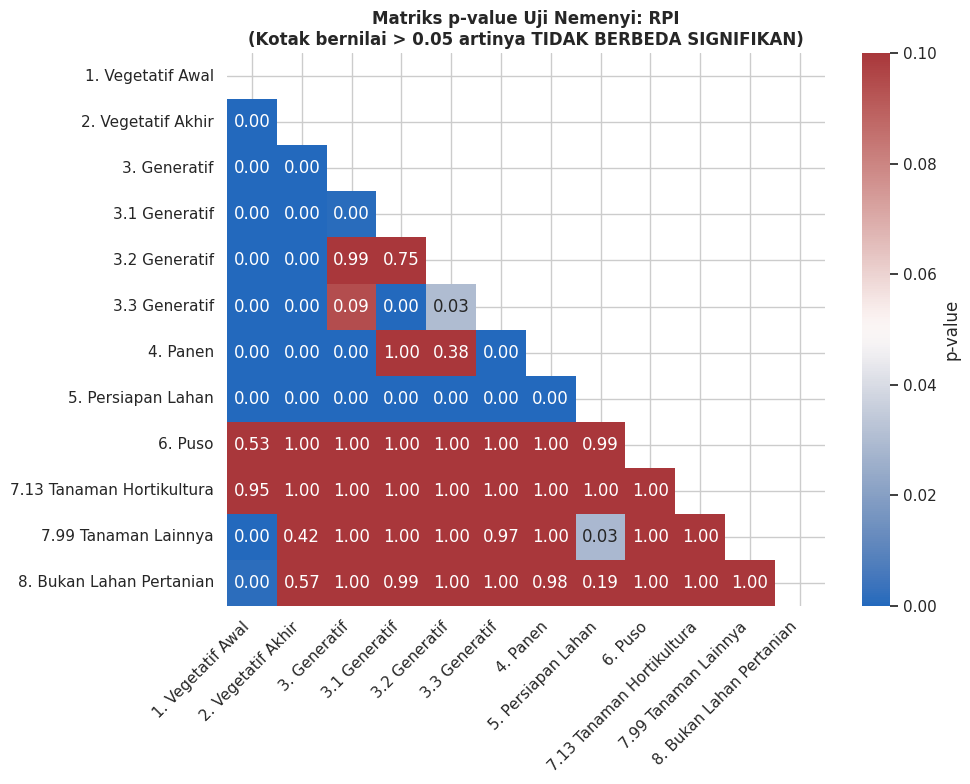


------------------------------------------------------------
▶ FITUR: NDPI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2389.26, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


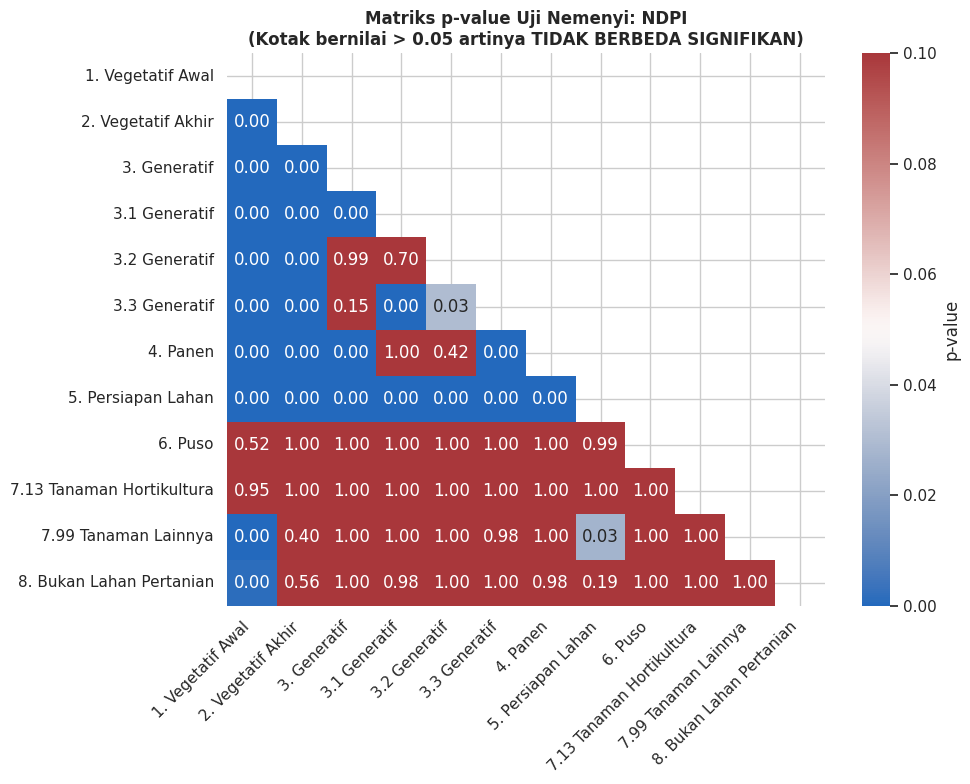


------------------------------------------------------------
▶ FITUR: API
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 3089.54, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


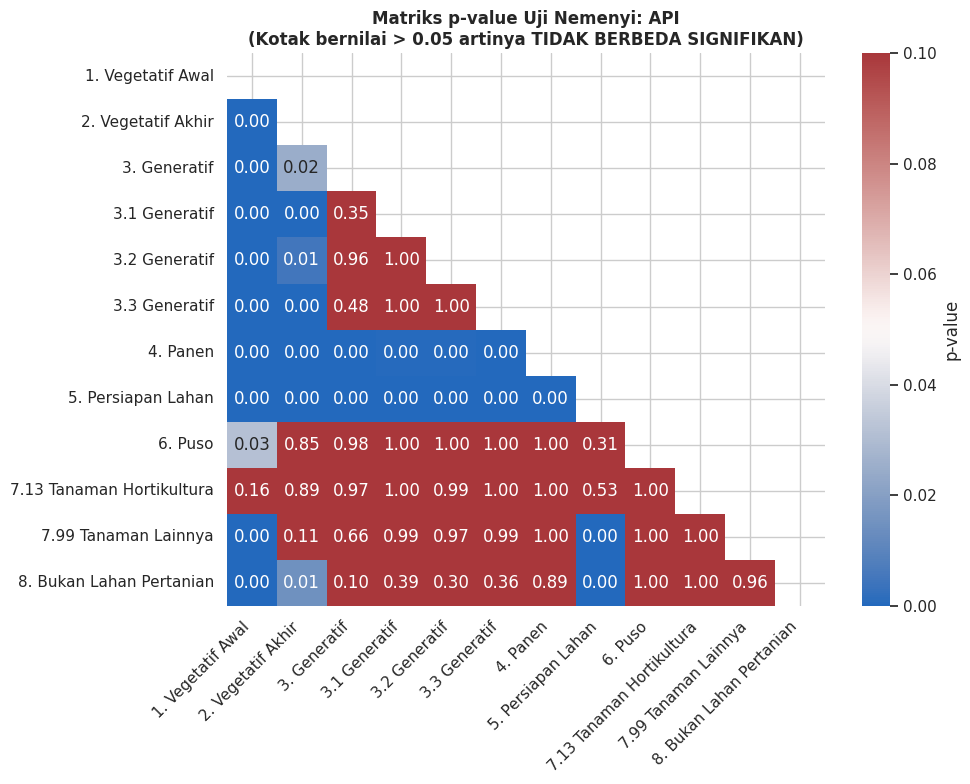


------------------------------------------------------------
▶ FITUR: B2
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 4731.57, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


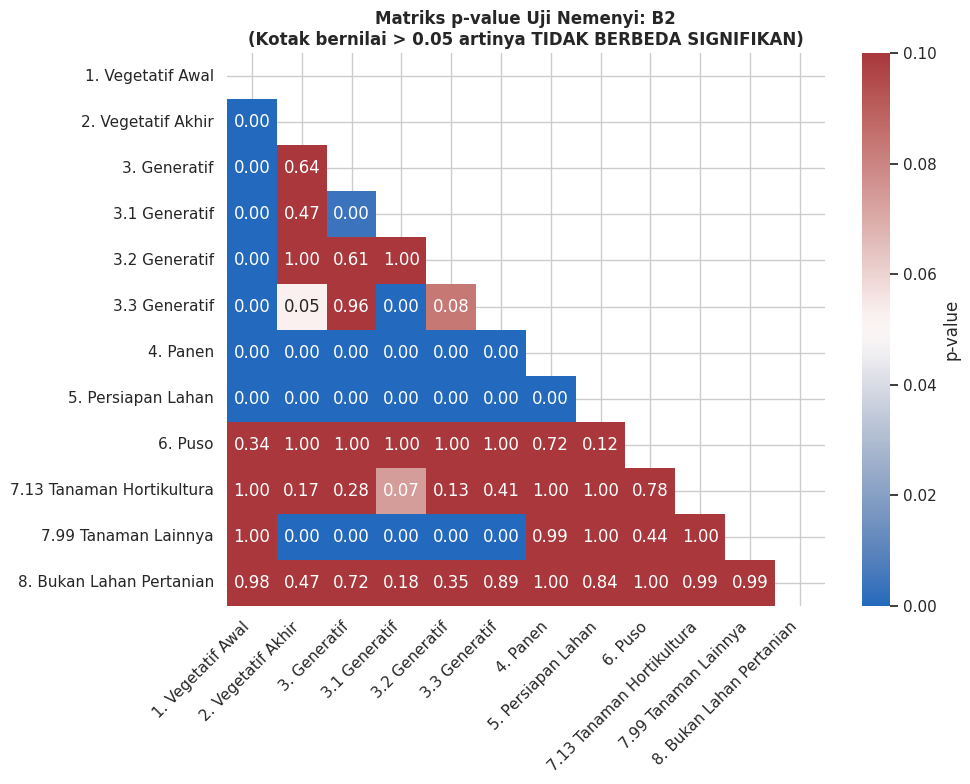


------------------------------------------------------------
▶ FITUR: B3
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 5142.66, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


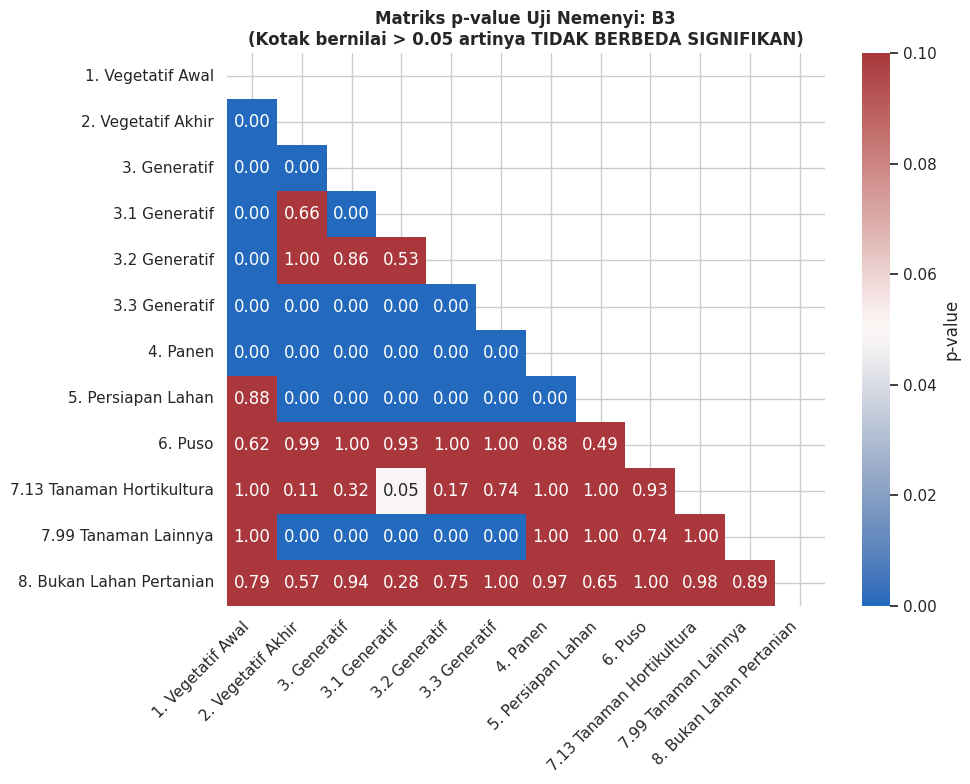


------------------------------------------------------------
▶ FITUR: B4
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 6986.57, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


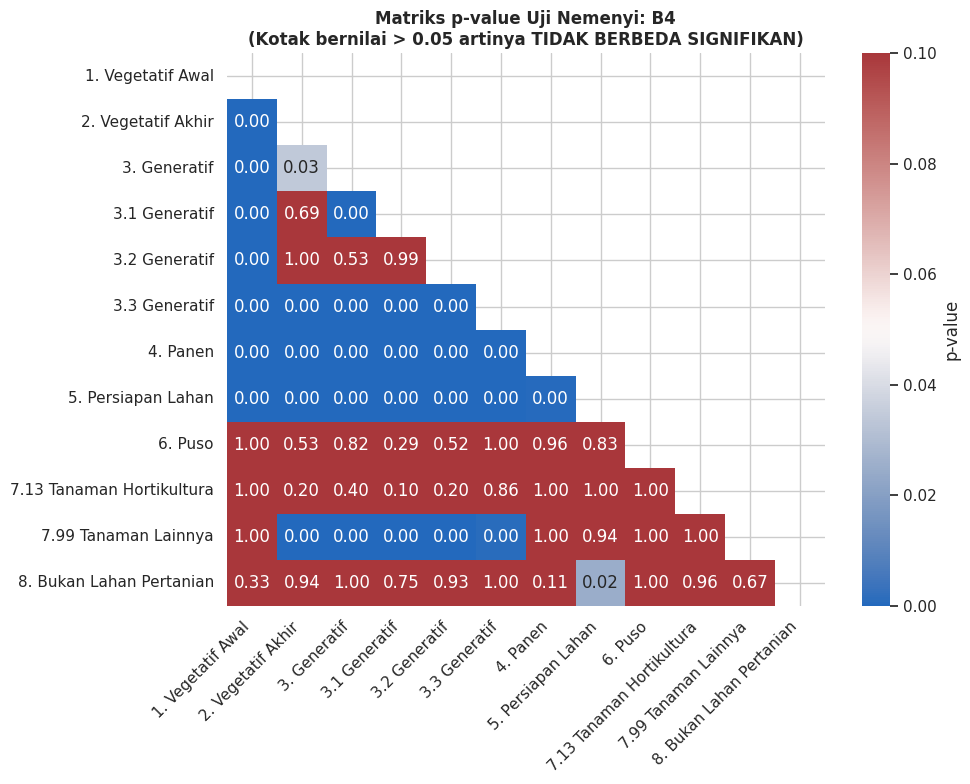


------------------------------------------------------------
▶ FITUR: B8
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 8237.33, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


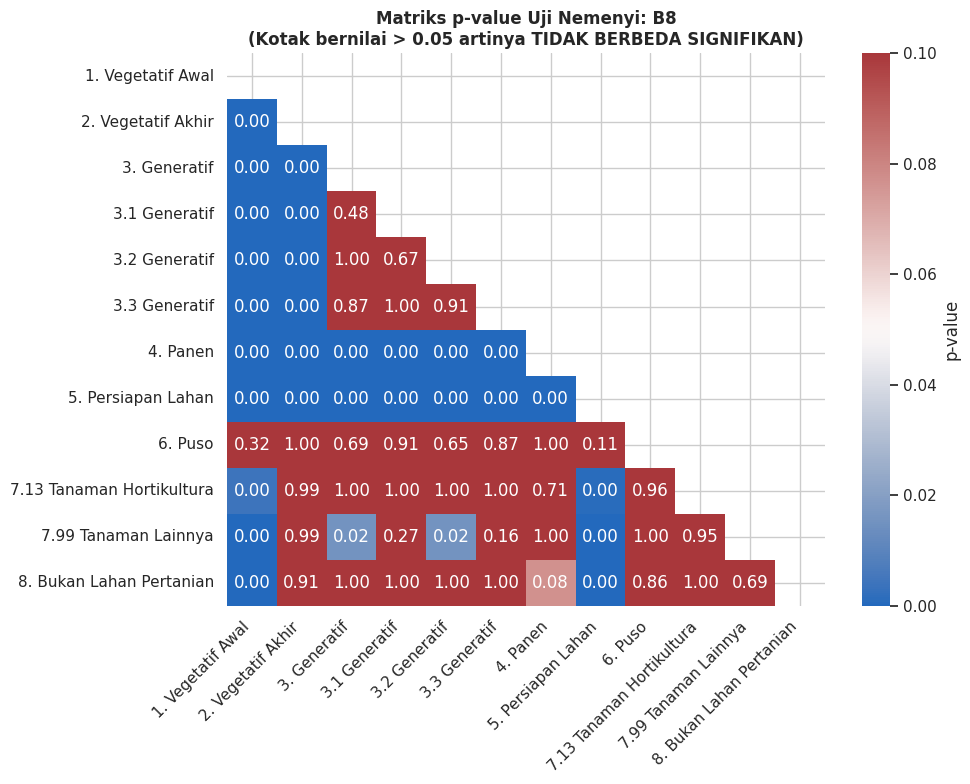


------------------------------------------------------------
▶ FITUR: B11
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 7534.00, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


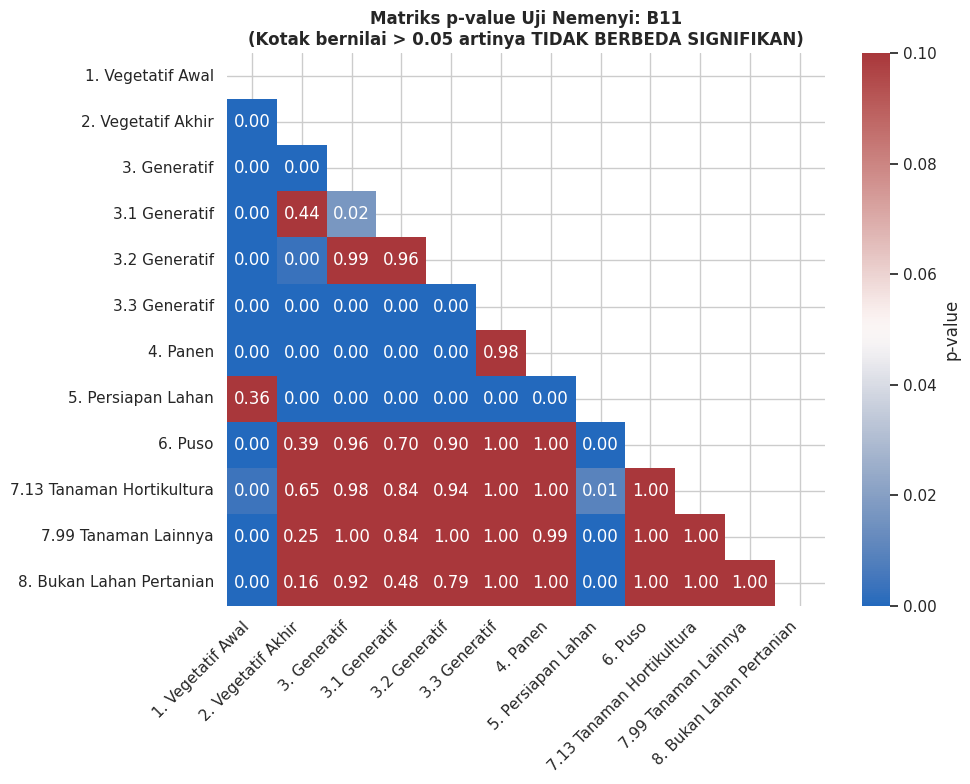


------------------------------------------------------------
▶ FITUR: EVI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 9461.65, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


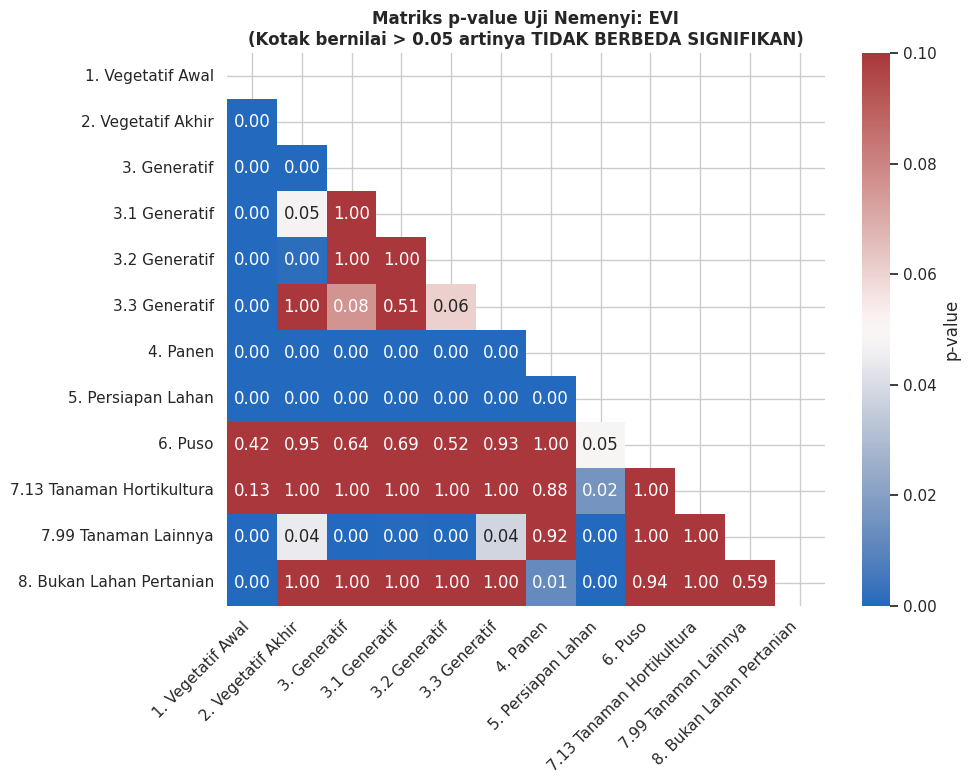


------------------------------------------------------------
▶ FITUR: LSWI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 6660.08, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...


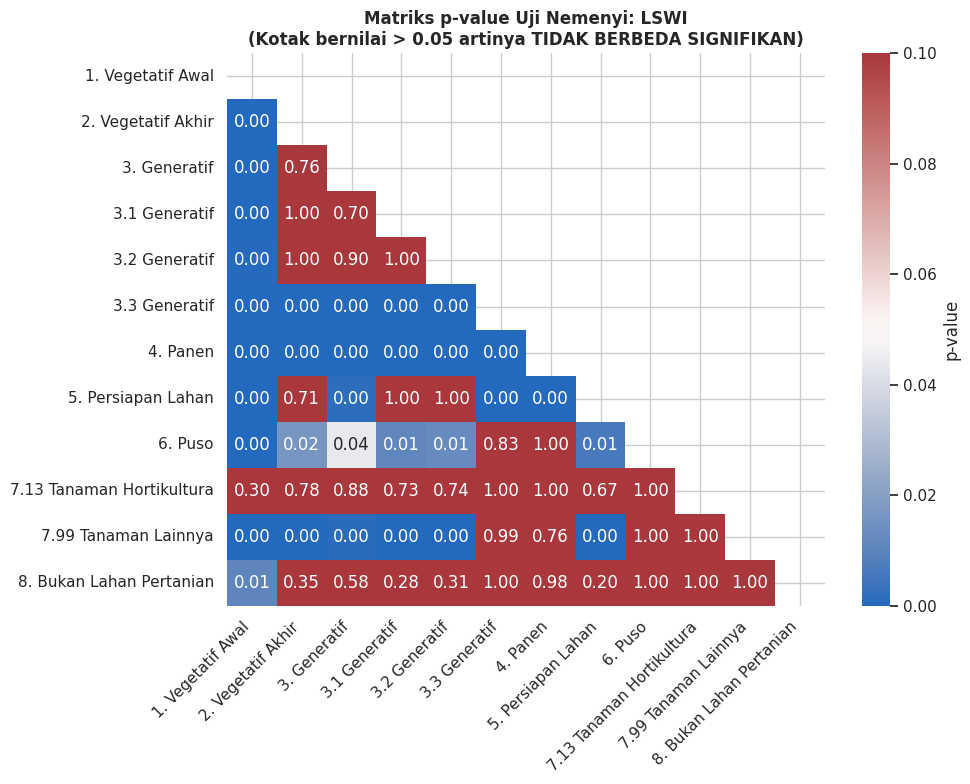

In [11]:
# ==============================================================================
# 9. EKSPERIMEN STATISTIK: UJI KRUSKAL-WALLIS & UJI NEMENYI (DATA ASLI BPS)
# ==============================================================================
import scipy.stats as stats
import scikit_posthocs as sp
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*80)
print("🔬 9. UJI STATISTIK BEDA NYATA ANTAR KELAS ASLI (Kruskal-Wallis & Nemenyi)")
print("="*80)

# 1. PERSIAPAN DATA (Menggunakan Label Asli yang belum digabung/dibersihkan)
df_stat = df_final.dropna(subset=['Label_BPS']).copy()
df_stat['Nama_Fase_Asli'] = df_stat['Label_BPS'].map(label_map_bps)
df_stat = df_stat.dropna(subset=['Nama_Fase_Asli'])

# Pastikan urutan kategorinya mengikuti kamus lama agar rapi
urutan_lama = list(custom_palette_lama.keys())
df_stat['Nama_Fase_Asli'] = pd.Categorical(df_stat['Nama_Fase_Asli'], categories=urutan_lama, ordered=True)

print(f"Total data dievaluasi: {len(df_stat)} baris")
print("Tingkat Signifikansi (Alpha) = 0.05\n")

# 2. LOOPING UJI STATISTIK UNTUK SETIAP FITUR
for fitur in fitur_citra:
    if fitur not in df_stat.columns:
        continue

    print(f"\n" + "-"*60)
    print(f"▶ FITUR: {fitur}")
    print("-"*60)

    # Kumpulkan array data untuk masing-masing kelas yang tidak kosong
    grup_data = []
    nama_grup_valid = []
    for nama_fase, grup in df_stat.groupby('Nama_Fase_Asli', observed=True):
        data_fitur = grup[fitur].dropna().values
        if len(data_fitur) > 0:
            grup_data.append(data_fitur)
            nama_grup_valid.append(nama_fase)

    # UJI 1: KRUSKAL-WALLIS
    # H0: Semua kelompok memiliki distribusi median yang sama
    # H1: Setidaknya ada satu kelompok yang berbeda
    stat_kw, pval_kw = stats.kruskal(*grup_data)

    print(f"Hasil Kruskal-Wallis -> Statistik H: {stat_kw:.2f}, p-value: {pval_kw:.4e}")

    if pval_kw < 0.05:
        print("Kesimpulan: Terdapat perbedaan signifikan antar kelas (p < 0.05). Melanjutkan ke Uji Nemenyi...")

        # UJI 2: NEMENYI POST-HOC TEST
        # Melakukan perbandingan pasangan (pairwise) antar semua kelas
        hasil_nemenyi = sp.posthoc_nemenyi(df_stat, val_col=fitur, group_col='Nama_Fase_Asli')

        # Agar mudah dibaca, kita visualisasikan nilai p-value Nemenyi menggunakan Heatmap
        # Kita tandai warna merah jika p-value > 0.05 (TIDAK BERBEDA NYATA / BISA DIGABUNG)
        plt.figure(figsize=(10, 8))

        # Masking untuk menyembunyikan segitiga atas (karena matriksnya simetris)
        mask = np.triu(np.ones_like(hasil_nemenyi, dtype=bool))

        sns.heatmap(
            hasil_nemenyi,
            mask=mask,
            annot=True,
            fmt=".2f",
            cmap="vlag",    # Biru untuk signifikan, Merah untuk tidak signifikan
            vmin=0,
            vmax=0.1,       # Memusatkan rentang warna di sekitar 0.05
            cbar_kws={'label': 'p-value'}
        )

        plt.title(f'Matriks p-value Uji Nemenyi: {fitur}\n(Kotak bernilai > 0.05 artinya TIDAK BERBEDA SIGNIFIKAN)',
                  fontsize=12, fontweight='bold')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    else:
        print("Kesimpulan: TIDAK ada perbedaan signifikan antar kelas (p >= 0.05). Nemenyi tidak diperlukan.")


🔬 UJI STATISTIK BEDA NYATA: LABEL BARU (MEI-OKT 2023 & 2024, PRE-PROCESSING)
Total data dievaluasi: 14040 baris
Tingkat Signifikansi (Alpha) = 0.05


------------------------------------------------------------
▶ FITUR: VV_db
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2464.85, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


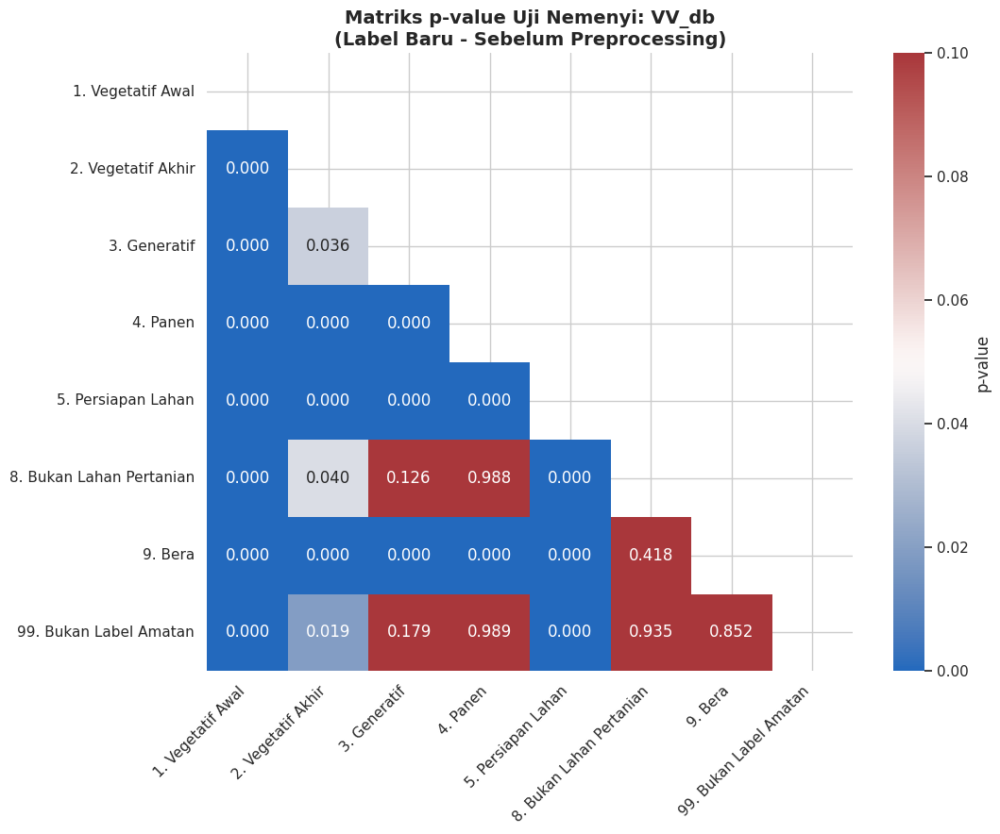


------------------------------------------------------------
▶ FITUR: VH_db
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 5391.71, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


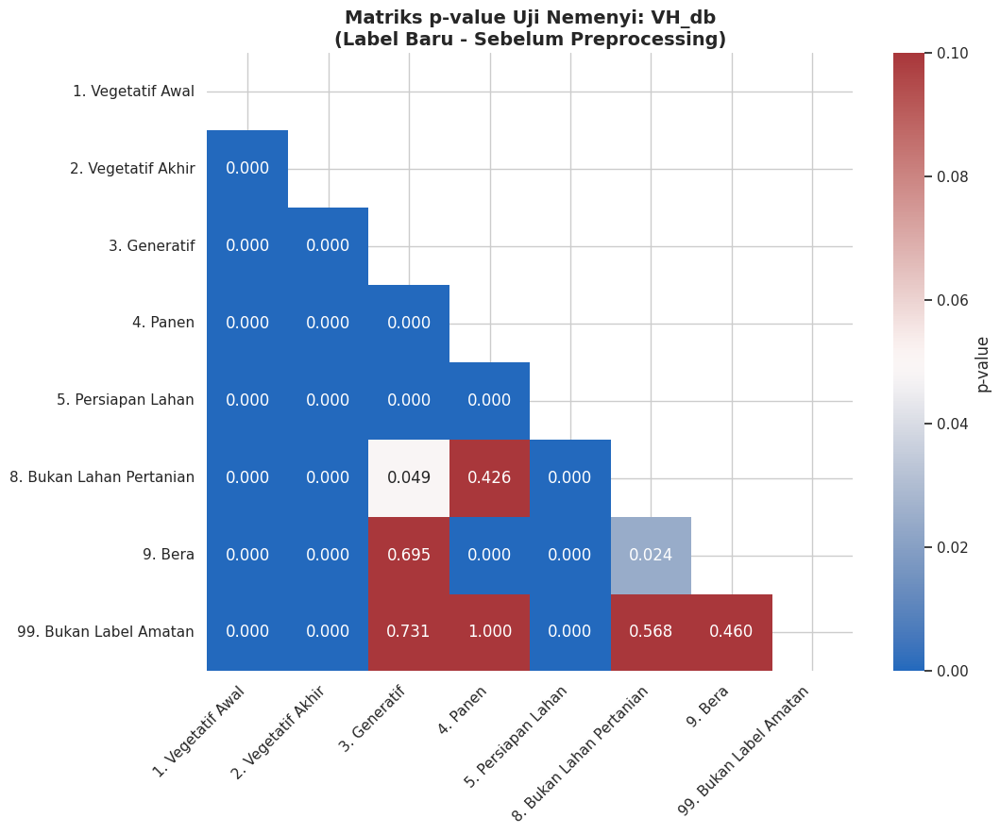


------------------------------------------------------------
▶ FITUR: RPI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2316.29, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


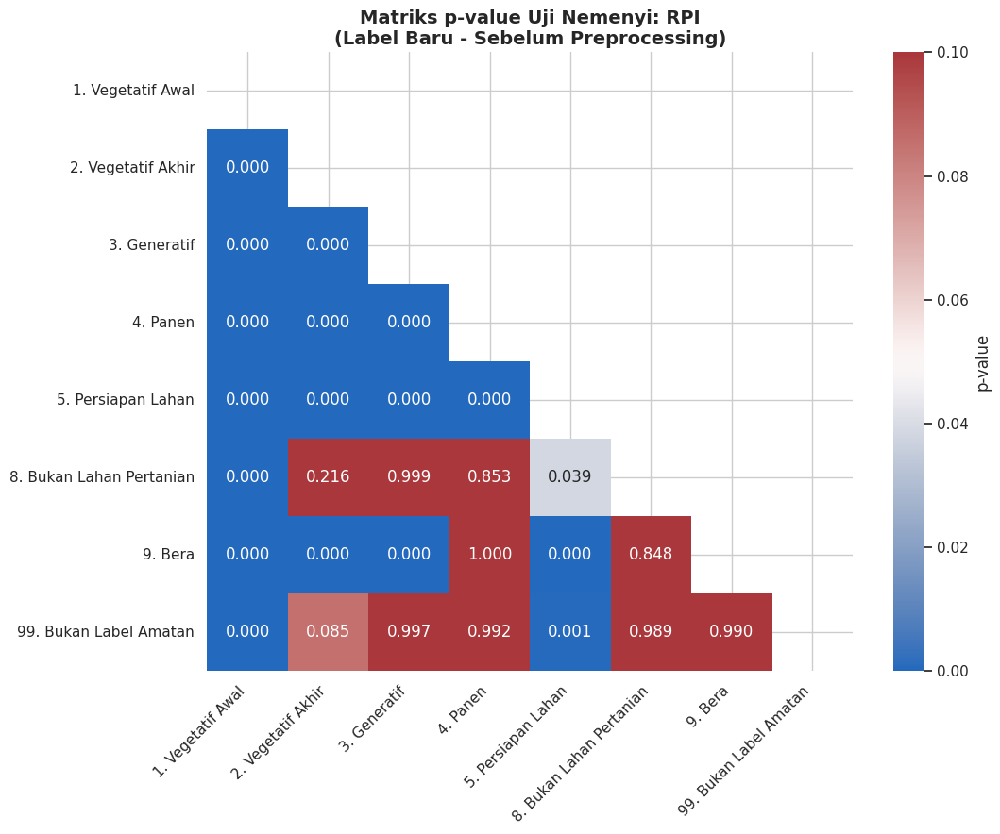


------------------------------------------------------------
▶ FITUR: NDPI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2314.68, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


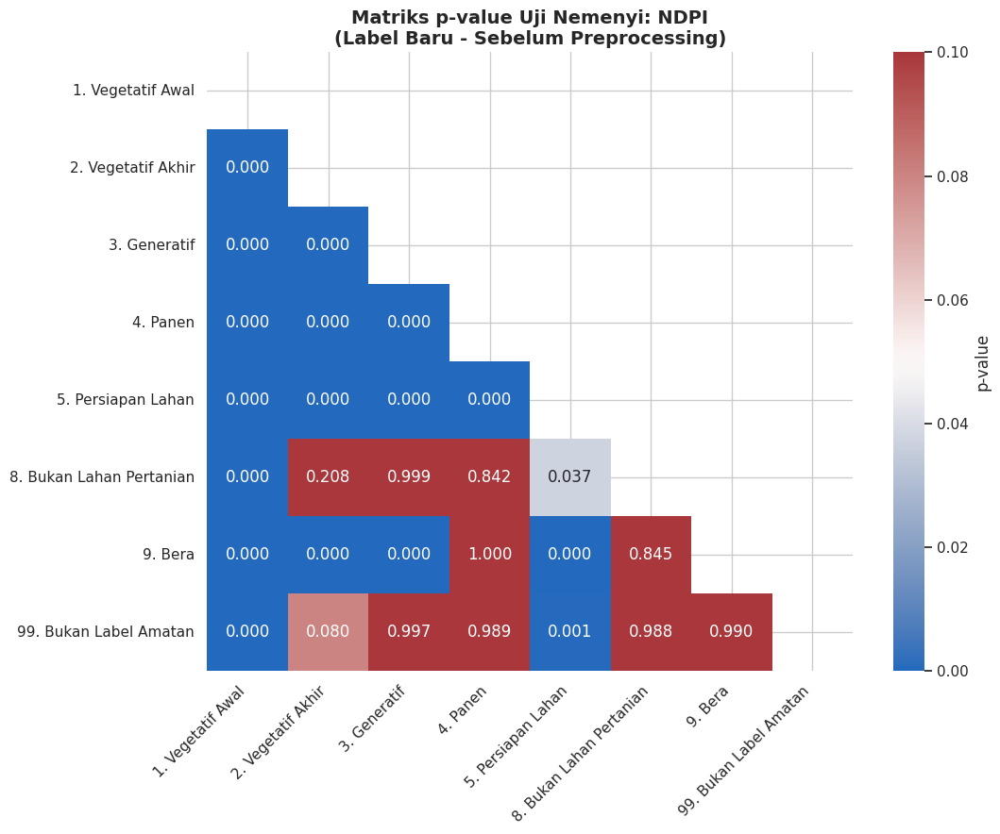


------------------------------------------------------------
▶ FITUR: API
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 3258.28, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


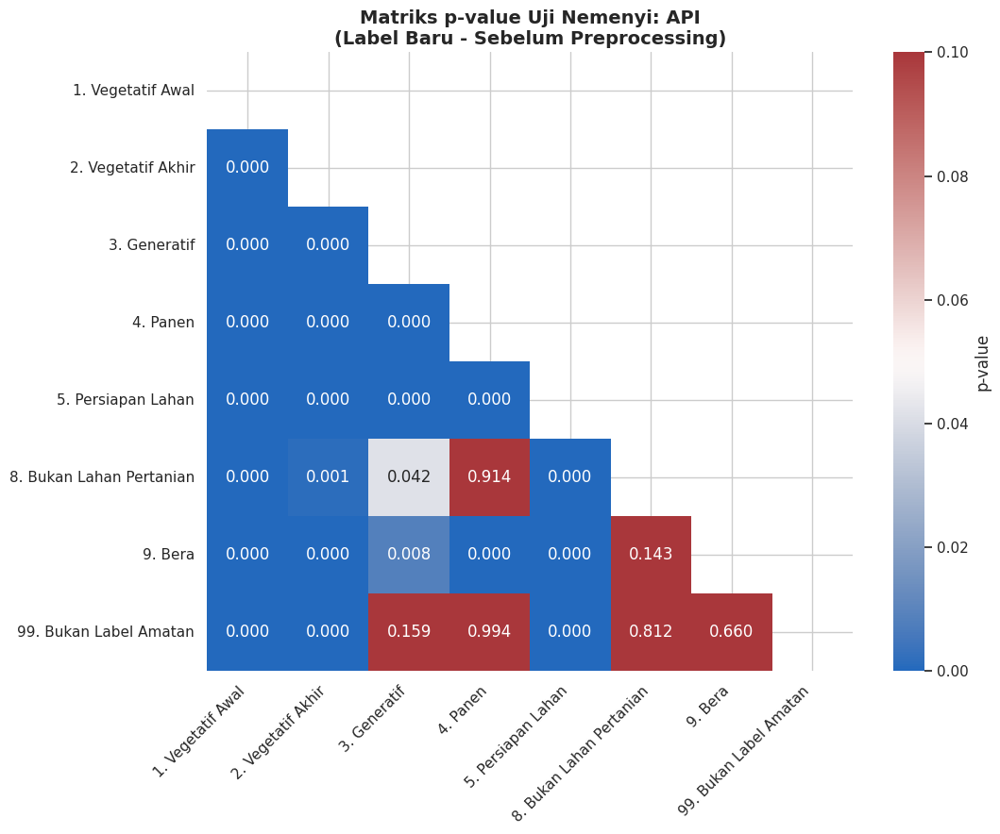


------------------------------------------------------------
▶ FITUR: B2
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 4724.78, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


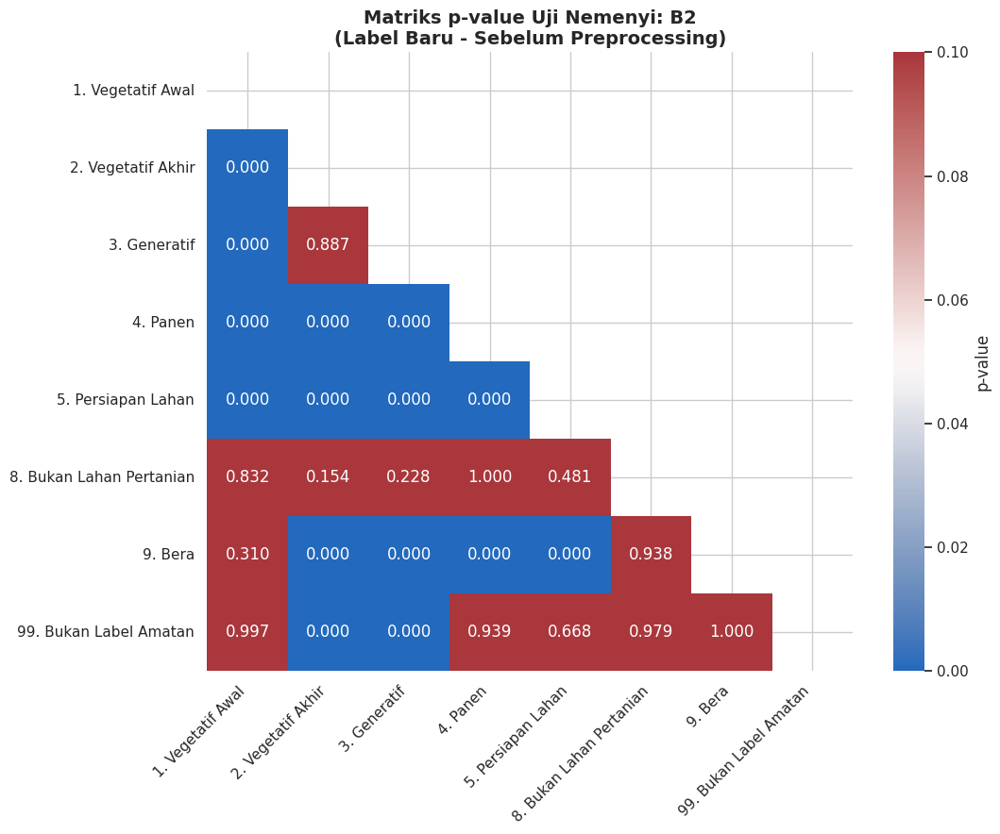


------------------------------------------------------------
▶ FITUR: B3
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 5059.45, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


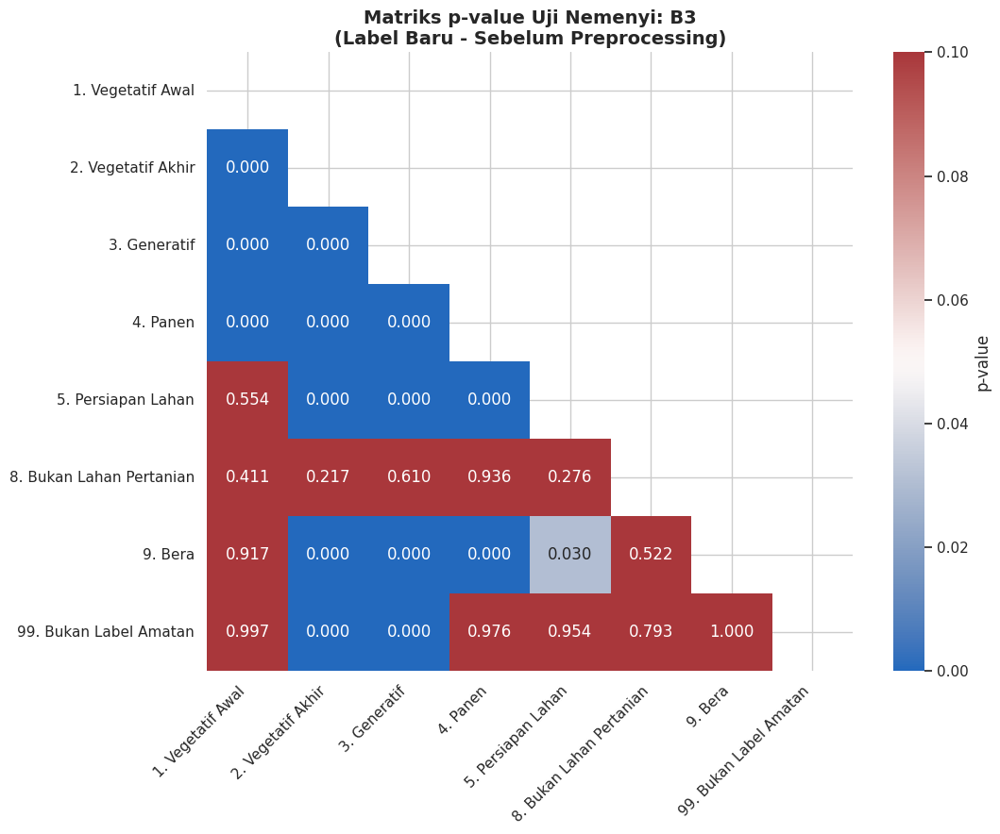


------------------------------------------------------------
▶ FITUR: B4
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 6847.54, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


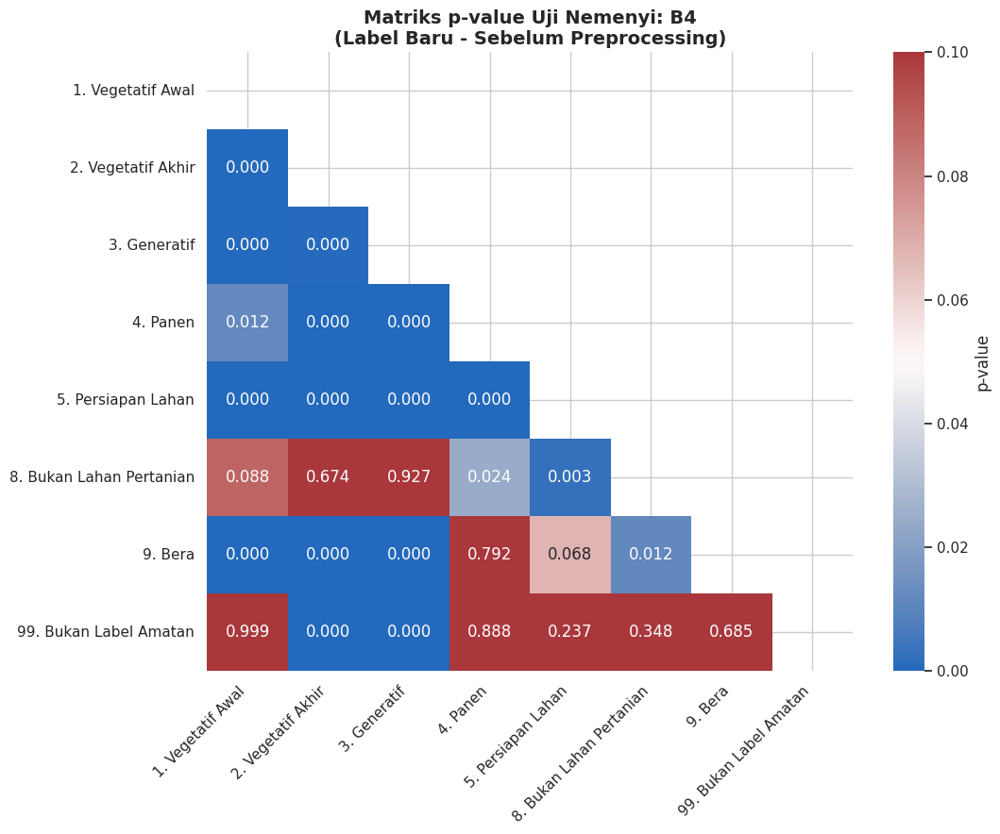


------------------------------------------------------------
▶ FITUR: B8
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 8221.50, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


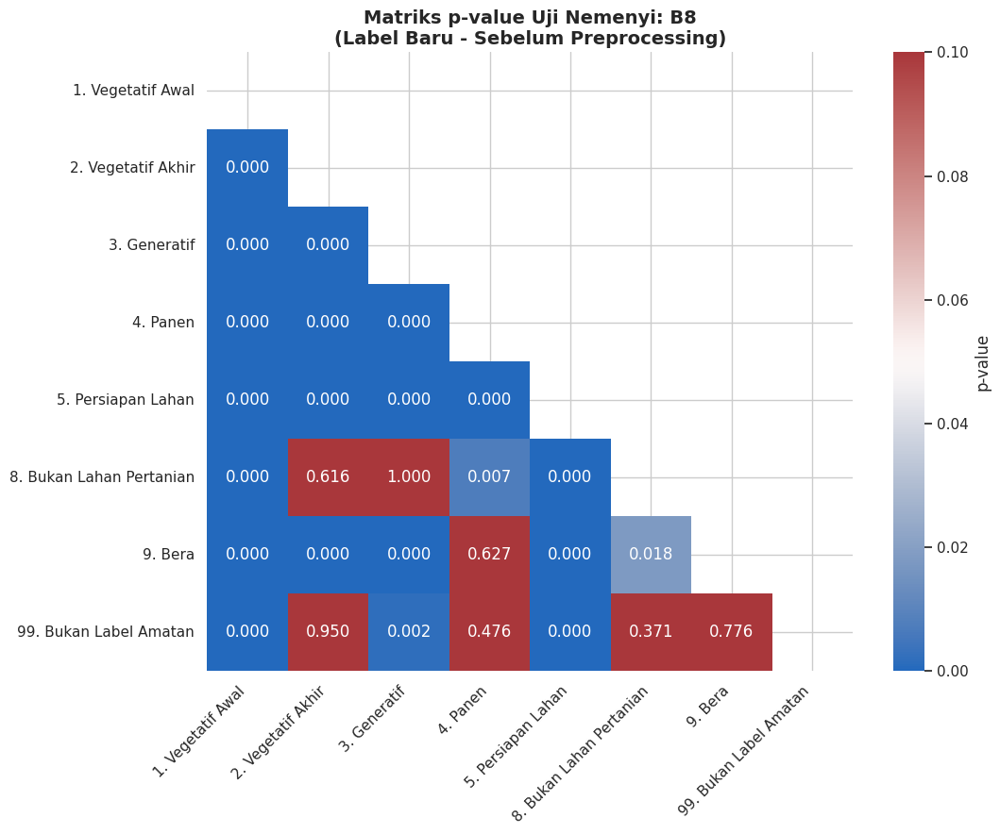


------------------------------------------------------------
▶ FITUR: B11
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 7434.80, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


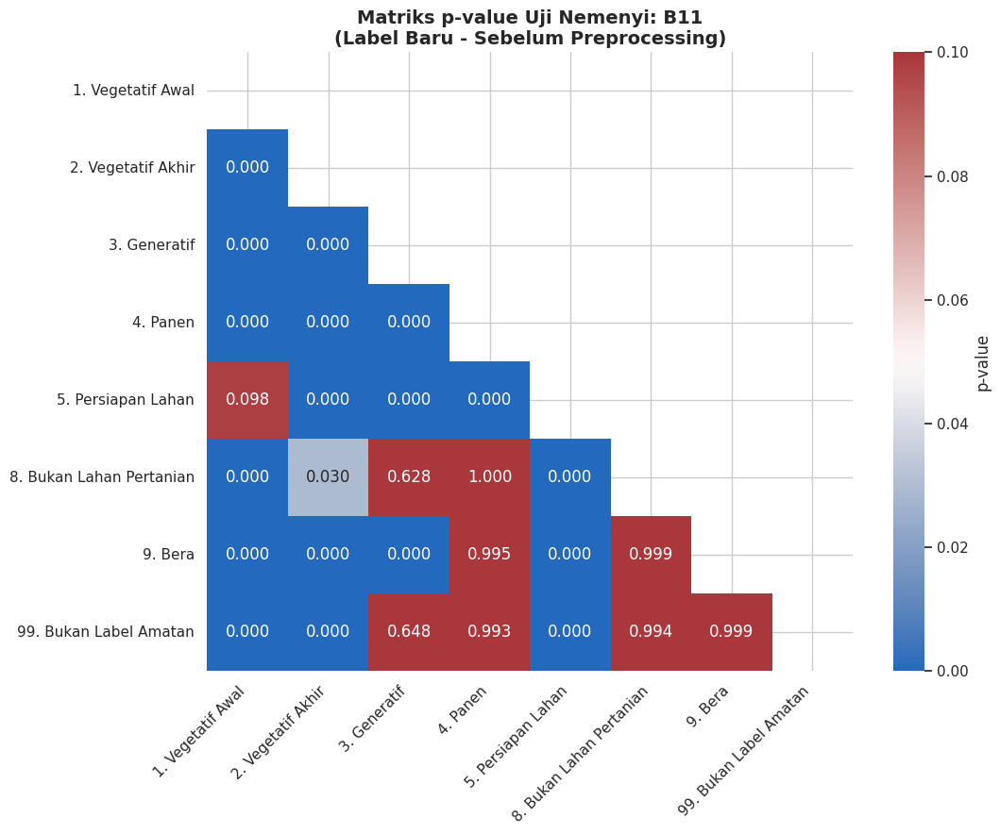


------------------------------------------------------------
▶ FITUR: EVI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 9435.04, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


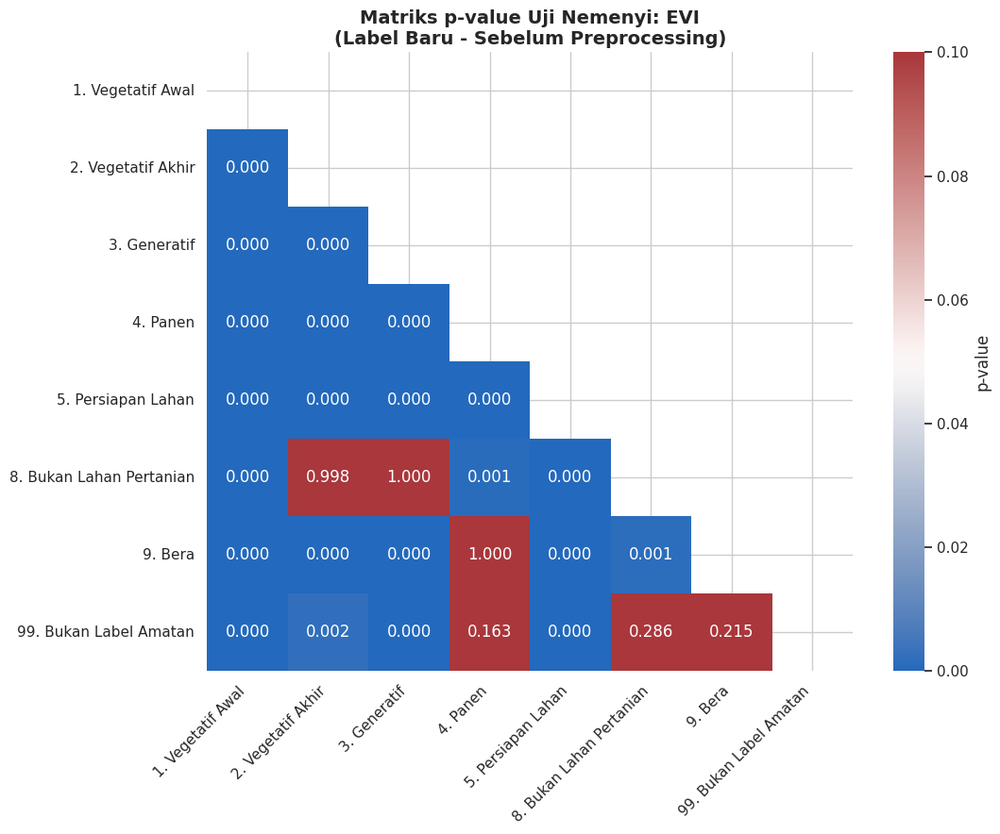


------------------------------------------------------------
▶ FITUR: LSWI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 6471.56, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...


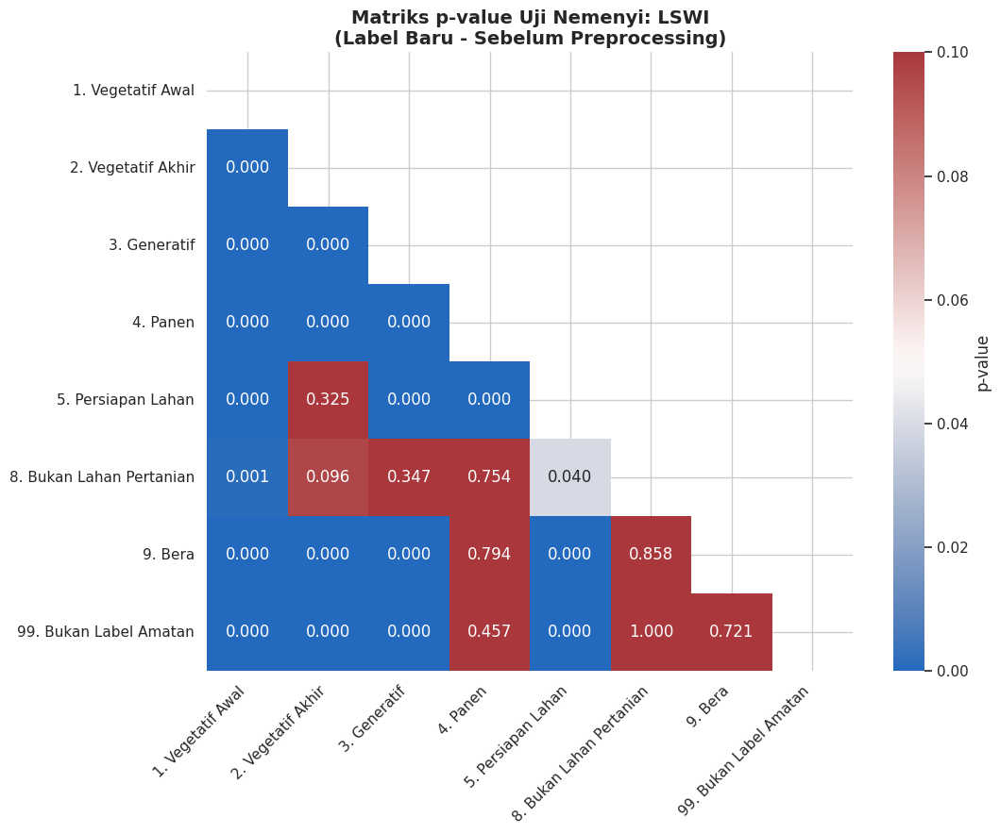

In [12]:
# ==============================================================================
# 9. EKSPERIMEN STATISTIK: UJI KRUSKAL-WALLIS & NEMENYI (SEMUA LABEL BARU)
# ==============================================================================
import scipy.stats as stats
import scikit_posthocs as sp
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

print("\n" + "="*80)
print("🔬 UJI STATISTIK BEDA NYATA: LABEL BARU (MEI-OKT 2023 & 2024, PRE-PROCESSING)")
print("="*80)

# 1. PERSIAPAN DATA (Menggunakan Label_Final)
df_stat_all = df_final.dropna(subset=['Label_Final']).copy()
df_stat_all['Nama_Fase_Baru'] = df_stat_all['Label_Final'].map(label_map_baru)

# Pastikan urutannya rapi sesuai custom_palette_baru
urutan_baru = list(custom_palette_baru.keys())

# Hapus baris yang gagal di-mapping (jika ada) dan ubah ke tipe Categorical
df_stat_all = df_stat_all.dropna(subset=['Nama_Fase_Baru'])
df_stat_all['Nama_Fase_Baru'] = pd.Categorical(df_stat_all['Nama_Fase_Baru'], categories=urutan_baru, ordered=True)

print(f"Total data dievaluasi: {len(df_stat_all)} baris")
print("Tingkat Signifikansi (Alpha) = 0.05\n")

# 2. LOOPING UJI STATISTIK UNTUK SETIAP FITUR
for fitur in fitur_citra:
    if fitur not in df_stat_all.columns:
        continue

    print(f"\n" + "-"*60)
    print(f"▶ FITUR: {fitur}")
    print("-"*60)

    # Kumpulkan array data untuk masing-masing kelas
    grup_data = []
    nama_grup_valid = []
    for nama_fase, grup in df_stat_all.groupby('Nama_Fase_Baru', observed=True):
        data_fitur = grup[fitur].dropna().values
        if len(data_fitur) > 0:
            grup_data.append(data_fitur)
            nama_grup_valid.append(nama_fase)

    # Pastikan minimal ada 2 grup untuk diuji
    if len(grup_data) < 2:
        print(f"Data tidak cukup untuk diuji pada fitur {fitur}.")
        continue

    # UJI 1: KRUSKAL-WALLIS
    # H0: Tidak ada perbedaan nilai median antar kelas
    # H1: Minimal ada satu kelas yang berbeda
    stat_kw, pval_kw = stats.kruskal(*grup_data)

    print(f"Hasil Kruskal-Wallis -> Statistik H: {stat_kw:.2f}, p-value: {pval_kw:.4e}")

    if pval_kw < 0.05:
        print("Kesimpulan: Terdapat perbedaan signifikan antar kelas. Melanjutkan ke Uji Nemenyi...")

        # UJI 2: NEMENYI POST-HOC TEST
        hasil_nemenyi = sp.posthoc_nemenyi(df_stat_all, val_col=fitur, group_col='Nama_Fase_Baru')

        # Mengurutkan matriks sesuai dengan urutan_baru agar mudah dibaca
        label_ada = [lbl for lbl in urutan_baru if lbl in hasil_nemenyi.columns]
        hasil_nemenyi = hasil_nemenyi.loc[label_ada, label_ada]

        # Visualisasi Heatmap
        plt.figure(figsize=(11, 9))

        # Sembunyikan segitiga atas agar fokus ke satu sisi matriks
        mask = np.triu(np.ones_like(hasil_nemenyi, dtype=bool))

        sns.heatmap(
            hasil_nemenyi,
            mask=mask,
            annot=True,
            fmt=".3f",
            cmap="vlag",    # Biru untuk < 0.05, Merah/Putih untuk > 0.05
            vmin=0,
            vmax=0.1,       # Skala warna difokuskan di sekitar batas alpha 0.05
            cbar_kws={'label': 'p-value'}
        )

        plt.title(f'Matriks p-value Uji Nemenyi: {fitur}\n(Label Baru - Sebelum Preprocessing)',
                  fontsize=14, fontweight='bold')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    else:
        print("Kesimpulan: TIDAK ada perbedaan signifikan antar kelas (p >= 0.05).")

# **Praparation Data**



## *1. Resampling Label (Penghapusan Anomali)*

In [13]:
# ==============================================================================
# TAHAP 1: RESAMPLING LABEL – PENGHAPUSAN ANOMALI
# (Urutan ke-1 dalam pipeline preprocessing)
# ==============================================================================
print("="*60)
print("TAHAP 1: RESAMPLING LABEL (PENGHAPUSAN ANOMALI)")
print("="*60 + "\n")

label_yang_dihapus = [8, 99]

# Simpan salinan data mentah untuk visualisasi perbandingan
df_mentah_kotor = df_final.copy()

# Buat salinan data untuk preprocessing akhir
df_prep = df_final.copy() # DATAFRAME YANG DIGUNAKAN
df_prep['ID_Titik'] = df_prep['TitikAmatX'].astype(str) + "_" + df_prep['TitikAmatY'].astype(str)
tahun_tersedia = sorted(df_prep['Tahun'].unique())

# 1. Hitung total baris yang mengandung label target
df_anomali = df_prep[df_prep['Label_Final'].isin(label_yang_dihapus)]
jml_baris_anomali = len(df_anomali)

print(f"Target Label Asli yang akan dihapus: {label_yang_dihapus}")
print(f"Total kemunculan (baris) dari target tersebut: {jml_baris_anomali} baris\n")

# 2. Perbandingan Titik Keseluruhan vs Titik Terinfeksi
total_titik = df_prep.groupby('Tahun')['ID_Titik'].nunique().rename('Total Titik')
titik_bermasalah = df_anomali.groupby('Tahun')['ID_Titik'].nunique().rename('Titik Terinfeksi')

df_rekap = pd.concat([total_titik, titik_bermasalah], axis=1).fillna(0).astype(int)
df_rekap['Sisa Titik (Jika Dihapus)'] = df_rekap['Total Titik'] - df_rekap['Titik Terinfeksi']
print("--- Perbandingan Jumlah Titik Sampel per Tahun ---")
display(df_rekap)

# 3. Rincian Titik Terinfeksi
print("\n--- Rincian Titik Sampel yang Terinfeksi ---")
if not df_anomali.empty:
    detail_titik = df_anomali.groupby(['TitikAmatX', 'TitikAmatY', 'Tahun']).size().unstack(fill_value=0)

    for thn in tahun_tersedia:
        if thn not in detail_titik.columns: detail_titik[thn] = 0

    detail_titik = detail_titik[tahun_tersedia].rename(columns={thn: f'Anomali ({thn})' for thn in tahun_tersedia})
    detail_titik['Total Kemunculan'] = detail_titik.sum(axis=1)
    detail_titik = detail_titik.sort_values(by='Total Kemunculan', ascending=False).reset_index()
    display(detail_titik)
else:
    print("Aman! Tidak ditemukan target label tersebut.")

print("\n==========================================================")
print("B. PROSES PENGHAPUSAN SIKLUS")
print("==========================================================")
# 1. Identifikasi siklus
# Eksekusi penghapusan per siklus (Titik × Tahun)
df_prep['ID_Titik_Tahun'] = df_prep['ID_Titik'] + "_" + df_prep['Tahun'].astype(str)
hitung_anomali = df_prep[df_prep['Label_Final'].isin(label_yang_dihapus)].groupby('ID_Titik_Tahun').size()
target_hapus   = hitung_anomali[hitung_anomali >= 1].index.tolist()
print(f"Ditemukan {len(target_hapus)} siklus (Titik per Tahun) yang terinfeksi.")

# 2. Eksekusi Penghapusan
df_bersih = df_prep[~df_prep['ID_Titik_Tahun'].isin(target_hapus)].copy()
print(f"-> Baris data menyusut dari {len(df_prep)} menjadi {len(df_bersih)} baris.")
df_prep = df_bersih.drop(columns=['ID_Titik_Tahun'])

print("==========================================================")
print("C. HASIL EVALUASI (SETELAH PENGHAPUSAN)")
print("==========================================================")
# 1. Hitung ulang statistik
df_anomali_baru = df_prep[df_prep['Label_Final'].isin(label_yang_dihapus)]
print(f"Total kemunculan target tersisa: {len(df_anomali_baru)} baris")

total_titik_baru = df_prep.groupby('Tahun')['ID_Titik'].nunique().rename('Total Titik')
titik_bermasalah_baru = df_anomali_baru.groupby('Tahun')['ID_Titik'].nunique().rename('Titik Terinfeksi')

df_rekap_baru = pd.concat([total_titik_baru, titik_bermasalah_baru], axis=1).fillna(0).astype(int)
df_rekap_baru['Sisa Titik Aktual'] = df_rekap_baru['Total Titik'] - df_rekap_baru['Titik Terinfeksi']
print("--- Perbandingan Jumlah Titik Sampel per Tahun ---")
display(df_rekap_baru)

# Bersihkan kolom bantu
df_prep = df_prep.drop(columns=['ID_Titik'])


TAHAP 1: RESAMPLING LABEL (PENGHAPUSAN ANOMALI)

Target Label Asli yang akan dihapus: [8, 99]
Total kemunculan (baris) dari target tersebut: 78 baris

--- Perbandingan Jumlah Titik Sampel per Tahun ---


,Total Titik,Titik Terinfeksi,Sisa Titik (Jika Dihapus)
Tahun,,,
2023,1170,11,1159
2024,1170,11,1159



--- Rincian Titik Sampel yang Terinfeksi ---


Tahun,TitikAmatX,TitikAmatY,Anomali (2023),Anomali (2024),Total Kemunculan
0,107.217732,-6.527445,6,6,12
1,107.367212,-6.405651,6,6,12
2,107.515144,-6.359761,6,6,12
3,107.514246,-6.359761,6,6,12
4,107.461242,-6.422383,6,0,6
5,107.417405,-6.321369,5,0,5
6,107.487527,-6.252339,3,0,3
7,107.365608,-6.047727,0,2,2
8,107.350907,-6.196935,2,0,2
9,107.297150,-6.090502,2,0,2



B. PROSES PENGHAPUSAN SIKLUS
Ditemukan 22 siklus (Titik per Tahun) yang terinfeksi.
-> Baris data menyusut dari 28080 menjadi 27816 baris.
C. HASIL EVALUASI (SETELAH PENGHAPUSAN)
Total kemunculan target tersisa: 0 baris
--- Perbandingan Jumlah Titik Sampel per Tahun ---


,Total Titik,Titik Terinfeksi,Sisa Titik Aktual
Tahun,,,
2023,1159,0,1159
2024,1159,0,1159


In [14]:
# Melihat daftar nilai yang ada di masing-masing kolom
print("Nilai unik Label BPS:", df_prep['Label_BPS'].unique())
print("Nilai unik Label Generatif:", df_prep['Label_Generatif'].unique())
print("Nilai unik Label Panen:", df_prep['Label_Panen'].unique())

Nilai unik Label BPS: [nan 4.  5.  1.  3.  2.  3.3 3.1 3.2]
Nilai unik Label Generatif: [nan  4.  5.  1.  3.  2.]
Nilai unik Label Panen: [nan  4.  5.  1.  3.  2.  9.]


## *2. Interpolasi Linear*

In [15]:
# ==============================================================================
# TAHAP 2: INTERPOLASI LINEAR
# (Urutan ke-2 dalam pipeline preprocessing)
# ==============================================================================
print("="*60)
print("TAHAP 2: INTERPOLASI LINEAR")
print("="*60)

fitur_s1 = ['VV_db', 'VH_db', 'RPI', 'API', 'NDPI']
fitur_s2 = ['B2', 'B3', 'B4', 'B8', 'B11', 'EVI', 'LSWI']

total_sel      = df_prep[fitur_citra].size
missing_sebelum = df_prep[fitur_citra].isnull().sum().sum()
pct_sebelum     = missing_sebelum / total_sel * 100

# Rekap per sensor: jumlah sel kosong dibagi ukuran blok fiturnya sendiri
missing_s1 = df_prep[fitur_s1].isnull().sum().sum()
missing_s2 = df_prep[fitur_s2].isnull().sum().sum()

print(f"Total sel fitur     : {total_sel} ({len(df_prep)} baris x {len(fitur_citra)} fitur)")
print(f"Missing value total : {missing_sebelum} sel ({pct_sebelum:.2f}%)")
print(f"  - Sentinel-1 ({len(fitur_s1)} fitur) : {missing_s1} sel ({missing_s1/df_prep[fitur_s1].size*100:.2f}% dari blok S1)")
print(f"  - Sentinel-2 ({len(fitur_s2)} fitur) : {missing_s2} sel ({missing_s2/df_prep[fitur_s2].size*100:.2f}% dari blok S2)")

# Rincian per fitur, diurutkan dari yang paling parah
rekap_fitur = df_prep[fitur_citra].isnull().sum().sort_values(ascending=False)
rekap_fitur = rekap_fitur[rekap_fitur > 0]
print("\nRincian missing value per fitur (>0 saja):")
for fitur, jml in rekap_fitur.items():
    sensor = 'S1' if fitur in fitur_s1 else 'S2'
    print(f"  - {fitur:<8} [{sensor}] : {jml:>5} sel ({jml/len(df_prep)*100:.2f}% dari baris)")

# Baris yang benar-benar terdampak (>=1 fitur kosong), berbeda dari hitungan sel
baris_terdampak = df_prep[fitur_citra].isnull().any(axis=1).sum()
print(f"\nBaris terdampak (>=1 fitur kosong): {baris_terdampak} dari {len(df_prep)} baris "
      f"({baris_terdampak/len(df_prep)*100:.2f}%)")

# A. INTERPOLASI LINEAR
for fitur in fitur_citra:
    df_prep[fitur] = df_prep.groupby(
        ['TitikAmatX', 'TitikAmatY', 'Tahun']
    )[fitur].transform(lambda x: x.interpolate(method='linear', limit_direction='both'))

missing_sesudah = df_prep[fitur_citra].isnull().sum().sum()
print(f"\nTotal Missing Value sesudah interpolasi : {missing_sesudah} (Harus 0!)")
print("Interpolasi Linear Selesai!\n")

TAHAP 2: INTERPOLASI LINEAR
Total sel fitur     : 333792 (27816 baris x 12 fitur)
Missing value total : 6806 sel (2.04%)
  - Sentinel-1 (5 fitur) : 170 sel (0.12% dari blok S1)
  - Sentinel-2 (7 fitur) : 6636 sel (3.41% dari blok S2)

Rincian missing value per fitur (>0 saja):
  - B8       [S2] :   948 sel (3.41% dari baris)
  - B4       [S2] :   948 sel (3.41% dari baris)
  - B3       [S2] :   948 sel (3.41% dari baris)
  - B2       [S2] :   948 sel (3.41% dari baris)
  - EVI      [S2] :   948 sel (3.41% dari baris)
  - B11      [S2] :   948 sel (3.41% dari baris)
  - LSWI     [S2] :   948 sel (3.41% dari baris)
  - VV_db    [S1] :    34 sel (0.12% dari baris)
  - NDPI     [S1] :    34 sel (0.12% dari baris)
  - RPI      [S1] :    34 sel (0.12% dari baris)
  - VH_db    [S1] :    34 sel (0.12% dari baris)
  - API      [S1] :    34 sel (0.12% dari baris)

Baris terdampak (>=1 fitur kosong): 979 dari 27816 baris (3.52%)

Total Missing Value sesudah interpolasi : 0 (Harus 0!)
Interpolasi 

## *Analisis Data*


1. ANALISIS DESKRIPTIF STATISTIK


,count,mean,std,min,25%,50%,75%,max
VV_db,27816.0,-10.865973,2.591498,-21.791306,-12.293111,-10.675675,-9.165303,-1.117027
VH_db,27816.0,-18.219538,3.357817,-35.256296,-19.980516,-17.488564,-15.836265,-9.239222
RPI,27816.0,0.218351,0.123858,0.004538,0.129181,0.193888,0.280543,1.386119
NDPI,27816.0,0.658374,0.151829,-0.161819,0.564506,0.676946,0.771778,0.990966
API,27816.0,0.058533,0.032107,0.004327,0.037044,0.053281,0.074187,0.409123
B2,27816.0,0.058053,0.025644,0.000000,0.040000,0.056700,0.074000,0.320000
B3,27816.0,0.082214,0.025795,0.000000,0.064100,0.081300,0.098412,0.288400
B4,27816.0,0.078988,0.035759,0.000000,0.050850,0.079200,0.102600,0.280350
B8,27816.0,0.218504,0.073607,0.039900,0.154200,0.215100,0.275200,0.523400
B11,27816.0,0.137849,0.080798,0.007800,0.074800,0.128000,0.175200,0.476450



2. HEATMAP PERSENTASE DATA KOSONG PER PERIODE


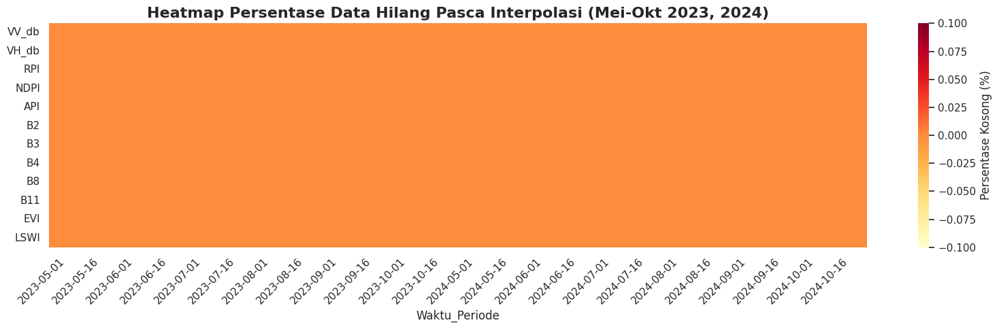


3. MATRIKS KORELASI ANTAR FITUR


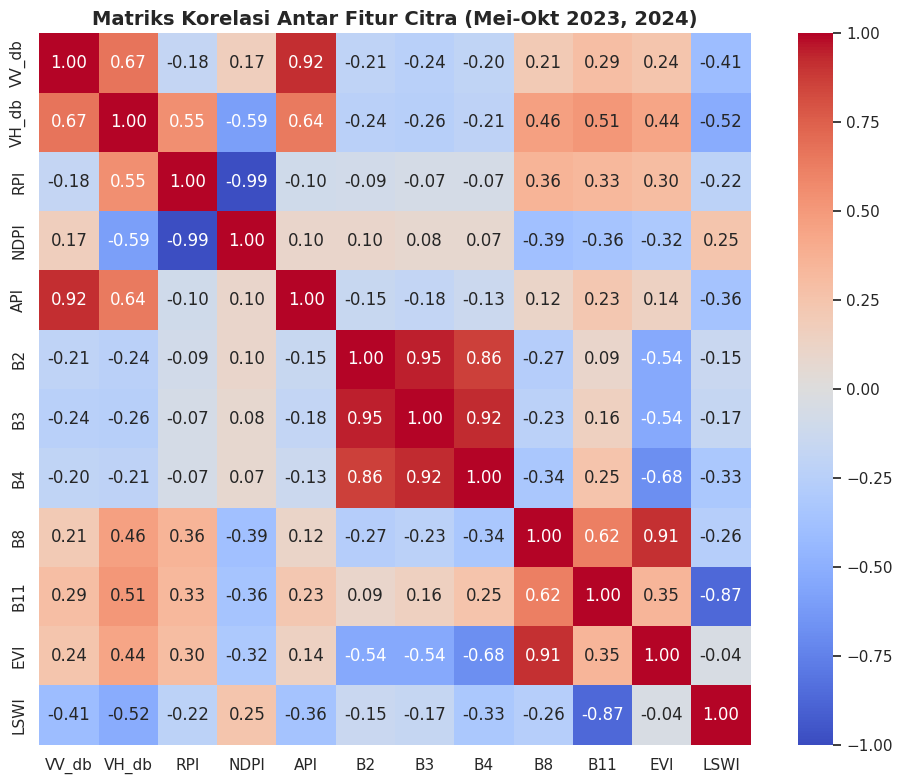


⚖️ 4. DISTRIBUSI KELAS FASE PERTUMBUHAN (PASCA PREPARATION)

[TABEL] DISTRIBUSI KELAS PASCA PREPROCESSING:


,Jumlah,Persentase (%)
Nama_Fase,,
1. Vegetatif Awal,2494,17.93
2. Vegetatif Akhir,1726,12.41
3. Generatif,2695,19.38
4. Panen,2323,16.70
5. Persiapan Lahan,2695,19.38
9. Bera,1975,14.20


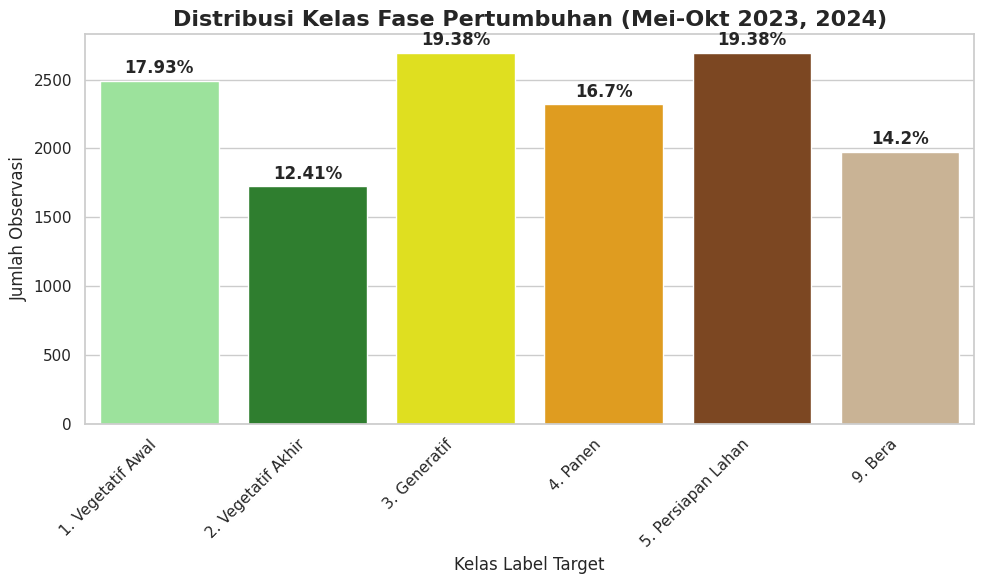


5. TREN FASE TANAM PER BULAN TIME-SERIES (PASCA PREP)


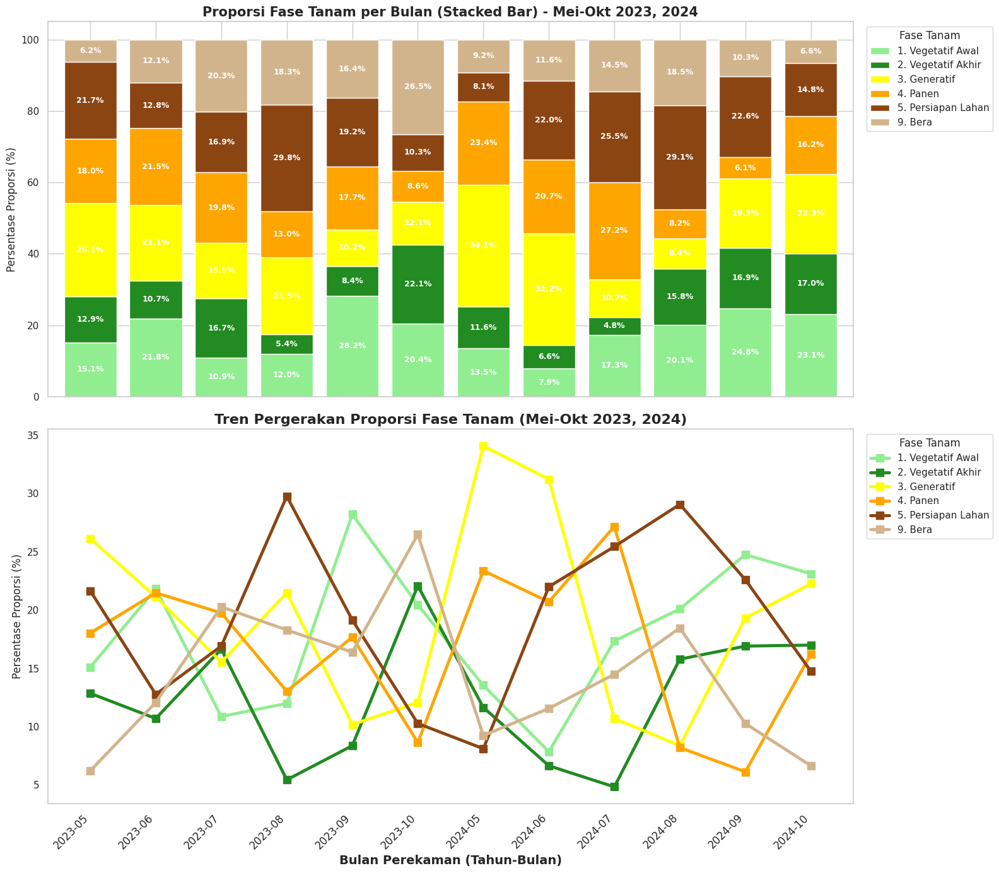


6. VISUALISASI BOXPLOT OVERALL PER VARIABEL (GLOBAL)



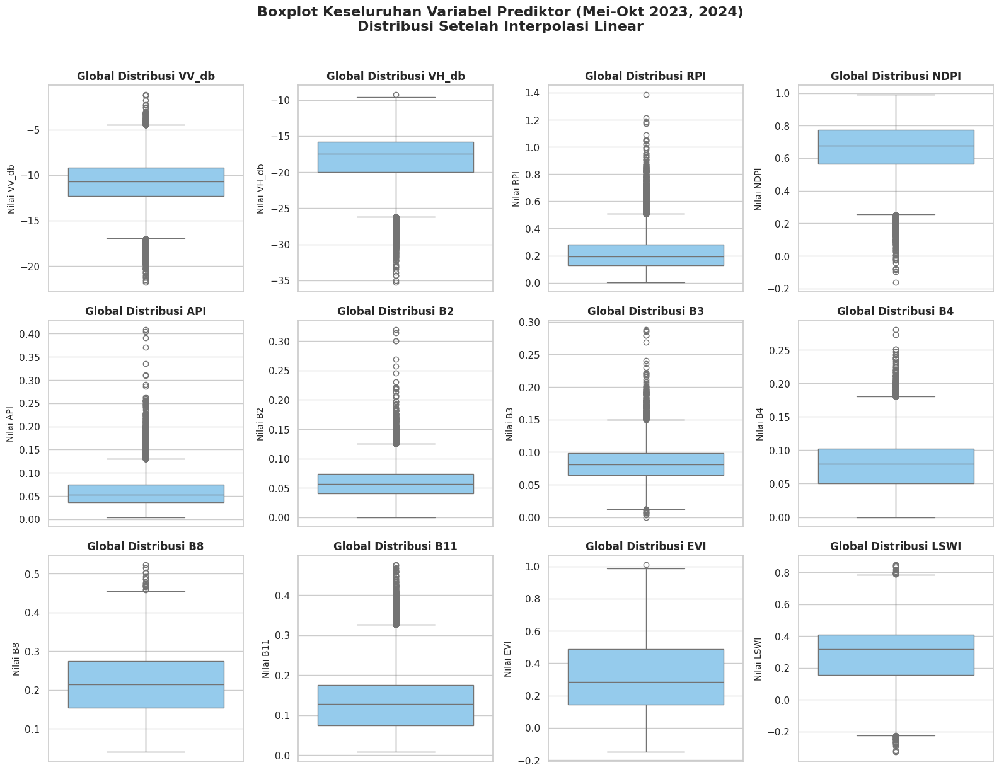


7. VISUALISASI BOXPLOT DISTRIBUSI FITUR PER FASE TANAM



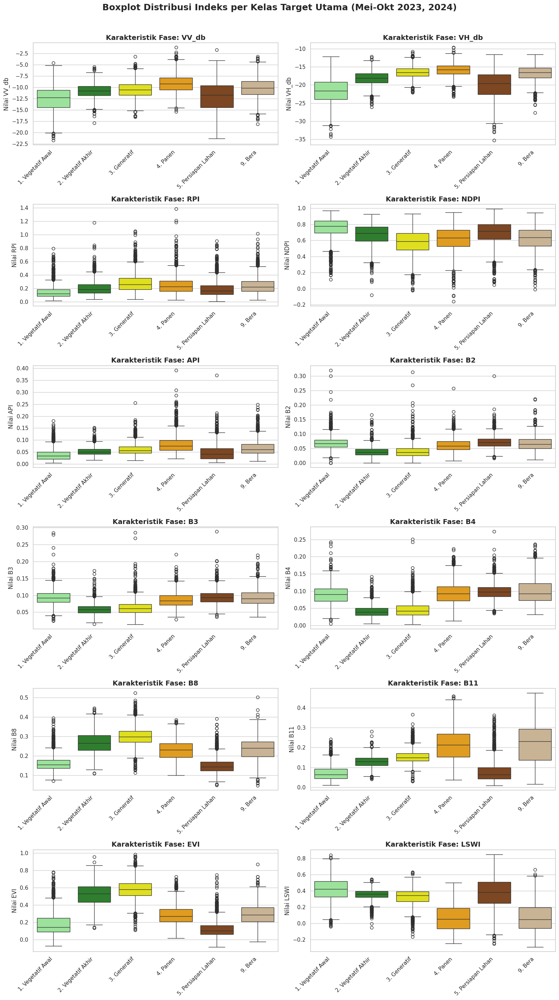


8. VISUALISASI HISTOGRAM OVERALL PER VARIABEL (GLOBAL)



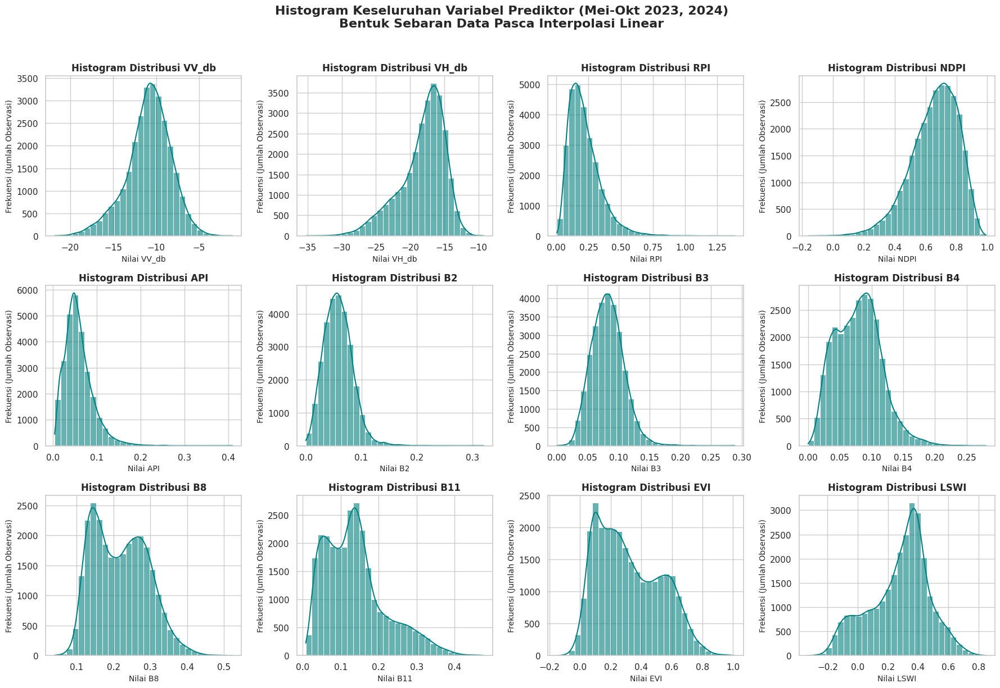

In [16]:
# ==============================================================================
# DEFINISI MAPPING & PALET WARNA BARU (Hanya Fase Target)
# ==============================================================================
teks_tahun = ", ".join(map(str, tahun_fokus)) if isinstance(tahun_fokus, list) else tahun_fokus

# Mapping disesuaikan untuk 6 kelas target final
label_map_baru = {
    1 : '1. Vegetatif Awal',
    2 : '2. Vegetatif Akhir',
    3 : '3. Generatif',
    4 : '4. Panen',
    5 : '5. Persiapan Lahan',
    9 : '9. Bera'
}

custom_palette_baru = {
    '1. Vegetatif Awal'  : '#90EE90',
    '2. Vegetatif Akhir' : '#228B22',
    '3. Generatif'       : '#FFFF00',
    '4. Panen'           : '#FFA500',
    '5. Persiapan Lahan' : '#8B4513',
    '9. Bera'            : '#D2B48C'
}

# ==============================================================================
# 1. ANALISIS DESKRIPTIF STATISTIK (PASCA INTERPOLASI)
# ==============================================================================
print("\n" + "="*60)
print("1. ANALISIS DESKRIPTIF STATISTIK")
print("="*60)
# Menggunakan df_prep
desc_stats = df_prep[fitur_citra].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
display(desc_stats)

# ==============================================================================
# 2. HEATMAP MISSING VALUE PER PERIODE
# ==============================================================================
print("\n" + "="*60)
print("2. HEATMAP PERSENTASE DATA KOSONG PER PERIODE")
print("="*60)
df_prep['Waktu_Periode'] = df_prep['Tanggal'].dt.strftime('%Y-%m-%d')

missing_per_periode = df_prep.groupby('Waktu_Periode', sort=False)[fitur_citra].apply(lambda x: (x.isnull().mean() * 100)).round(2)

plt.figure(figsize=(16, 5))
sns.heatmap(missing_per_periode.T, cmap="YlOrRd", cbar_kws={'label': 'Persentase Kosong (%)'})
plt.title(f'Heatmap Persentase Data Hilang Pasca Interpolasi (Mei-Okt {teks_tahun})', fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. MATRIKS KORELASI ANTAR FITUR
# ==============================================================================
print("\n" + "="*60)
print("3. MATRIKS KORELASI ANTAR FITUR")
print("="*60)
plt.figure(figsize=(10, 8))
sns.heatmap(df_prep[fitur_citra].corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, square=True)
plt.title(f'Matriks Korelasi Antar Fitur Citra (Mei-Okt {teks_tahun})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. ANALISIS KETIDAKSEIMBANGAN KELAS (PASCA PREPARATION)
# ==============================================================================
print("\n" + "="*60)
print("⚖️ 4. DISTRIBUSI KELAS FASE PERTUMBUHAN (PASCA PREPARATION)")
print("="*60)

# 1. Ekstraksi Data SESUDAH Prep (Sudah bersih dari anomali)
df_sesudah = df_prep.copy()
df_sesudah['Nama_Fase'] = df_sesudah['Label_Final'].map(label_map_baru)
dist_sesudah = df_sesudah['Nama_Fase'].value_counts(dropna=True).sort_index()
df_dist_sesudah = pd.DataFrame({'Jumlah': dist_sesudah, 'Persentase (%)': (dist_sesudah / dist_sesudah.sum() * 100).round(2)})

# Menampilkan Tabel
print("\n[TABEL] DISTRIBUSI KELAS PASCA PREPROCESSING:")
display(df_dist_sesudah)

# 2. Visualisasi Grafik Tunggal
plt.figure(figsize=(10, 6))
ax = plt.gca() # Mengambil axis dari figure saat ini

sns.barplot(x=df_dist_sesudah.index, y=df_dist_sesudah['Jumlah'], palette=custom_palette_baru, ax=ax)
ax.set_title(f'Distribusi Kelas Fase Pertumbuhan (Mei-Okt {teks_tahun})', fontsize=16, fontweight='bold')
ax.set_xlabel('Kelas Label Target', fontsize=12)
ax.set_ylabel('Jumlah Observasi', fontsize=12)
ax.tick_params(axis='x', rotation=45)
for tick in ax.get_xticklabels():
    tick.set_ha('right')
for i, p in enumerate(ax.patches):
    ax.annotate(f"{df_dist_sesudah['Persentase (%)'].iloc[i]}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 9),
                textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. TREN FASE TANAM PER BULAN (BAR & LINE CHART)
# ==============================================================================
print("\n" + "="*60)
print("5. TREN FASE TANAM PER BULAN TIME-SERIES (PASCA PREP)")
print("="*60)

# Gunakan data df_sesudah yang sudah diremap
df_tren_ses = df_sesudah.dropna(subset=['Label_Final']).copy()
df_tren_ses['Bulan_Tahun'] = df_tren_ses['Tanggal'].dt.strftime('%Y-%m')

urutan_ses = list(custom_palette_baru.keys())
df_tren_ses['Nama_Fase'] = pd.Categorical(df_tren_ses['Nama_Fase'], categories=urutan_ses, ordered=True)

tren_ses = df_tren_ses.groupby(['Bulan_Tahun', 'Nama_Fase'], observed=False).size().unstack(fill_value=0)
tren_ses_pct = tren_ses.div(tren_ses.sum(axis=1), axis=0) * 100
warna_ses = [custom_palette_baru[col] for col in tren_ses_pct.columns]

# --- 1. BAR CHART ---
fig, axes = plt.subplots(2, 1, figsize=(16, 14), sharex=True)

tren_ses_pct.plot(kind='bar', stacked=True, color=warna_ses, width=0.8, ax=axes[0])
axes[0].set_title(f'Proporsi Fase Tanam per Bulan (Stacked Bar) - Mei-Okt {teks_tahun}', fontsize=15, fontweight='bold')
axes[0].set_ylabel('Persentase Proporsi (%)', fontsize=12)
axes[0].legend(title='Fase Tanam', bbox_to_anchor=(1.01, 1), loc='upper left')

for c in axes[0].containers:
    labels = [f'{v.get_height():.1f}%' if v.get_height() > 3 else '' for v in c]
    axes[0].bar_label(c, labels=labels, label_type='center', fontsize=9, color='white', fontweight='bold')

# --- 2. LINE CHART ---
tren_ses_pct.plot(kind='line', ax=axes[1], color=warna_ses, linewidth=3.5, marker='s', markersize=8)
axes[1].set_title(f'Tren Pergerakan Proporsi Fase Tanam (Mei-Okt {teks_tahun})', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Bulan Perekaman (Tahun-Bulan)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Persentase Proporsi (%)', fontsize=12)
axes[1].legend(title='Fase Tanam', bbox_to_anchor=(1.01, 1), loc='upper left')
axes[1].grid(False)

plt.xticks(range(len(tren_ses_pct.index)), tren_ses_pct.index, rotation=45, ha='right', fontsize=12)
plt.tight_layout()
plt.show()

# ==============================================================================
# 6. BOXPLOT DISTRIBUSI FITUR OVERALL (MENDETEKSI GLOBAL OUTLIER)
# ==============================================================================
print("\n" + "="*60)
print("6. VISUALISASI BOXPLOT OVERALL PER VARIABEL (GLOBAL)")
print("="*60 + "\n")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

# Looping menggunakan df_prep
for i, fitur in enumerate(fitur_citra):
    if fitur in df_prep.columns:
        sns.boxplot(
            y=df_prep[fitur],
            ax=axes[i],
            color='#87CEFA',
            showfliers=True
        )
        axes[i].set_title(f'Global Distribusi {fitur}', fontsize=12, fontweight='bold')
        axes[i].set_ylabel(f'Nilai {fitur}', fontsize=10)

plt.suptitle(f'Boxplot Keseluruhan Variabel Prediktor (Mei-Okt {teks_tahun})\nDistribusi Setelah Interpolasi Linear',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# ==============================================================================
# 7. BOXPLOT DISTRIBUSI FITUR PER FASE TANAM (KARAKTERISTIK KELAS)
# ==============================================================================
print("\n" + "="*60)
print("7. VISUALISASI BOXPLOT DISTRIBUSI FITUR PER FASE TANAM")
print("="*60 + "\n")

# Siapkan data dari df_sesudah yang labelnya sudah rapi
df_box = df_sesudah.dropna(subset=['Label_Final']).copy()
urutan_fase = list(custom_palette_baru.keys())
df_box['Nama_Fase'] = pd.Categorical(df_box['Nama_Fase'], categories=urutan_fase, ordered=True)

fig, axes = plt.subplots(6, 2, figsize=(16, 28))
axes = axes.flatten()
for i, fitur in enumerate(fitur_citra):
    if fitur in df_box.columns:
        sns.boxplot(
            data=df_box,
            x='Nama_Fase',
            y=fitur,
            hue='Nama_Fase',
            palette=custom_palette_baru,
            ax=axes[i],
            showfliers=True,
            legend=False
        )
        axes[i].set_title(f'Karakteristik Fase: {fitur}', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('')
        axes[i].set_ylabel(f'Nilai {fitur}', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)

        for tick in axes[i].get_xticklabels():
            tick.set_ha('right')

plt.suptitle(f'Boxplot Distribusi Indeks per Kelas Target Utama (Mei-Okt {teks_tahun})',
             fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# ==============================================================================
# 8. HISTOGRAM DISTRIBUSI FITUR OVERALL (MENDETEKSI BENTUK SEBARAN GLOBAL)
# ==============================================================================
print("\n" + "="*60)
print("8. VISUALISASI HISTOGRAM OVERALL PER VARIABEL (GLOBAL)")
print("="*60 + "\n")

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

# Looping menggunakan df_prep
for i, fitur in enumerate(fitur_citra):
    if fitur in df_prep.columns:
        sns.histplot(
            data=df_prep,
            x=fitur,
            ax=axes[i],
            color='teal',
            bins=30,
            kde=True,
            alpha=0.6
        )
        axes[i].set_title(f'Histogram Distribusi {fitur}', fontsize=12, fontweight='bold')
        axes[i].set_xlabel(f'Nilai {fitur}', fontsize=10)
        axes[i].set_ylabel('Frekuensi (Jumlah Observasi)', fontsize=10)

plt.suptitle(f'Histogram Keseluruhan Variabel Prediktor (Mei-Okt {teks_tahun})\nBentuk Sebaran Data Pasca Interpolasi Linear',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## *3. Data Splitting (Train, Val, Test) — Anti-Leakage Spasial*

In [17]:
# ==============================================================================
# TAHAP 3: DATA SPLITTING (TRAIN / VAL / TEST) – ANTI SPATIAL LEAKAGE
# ==============================================================================
print("="*60)
print("TAHAP 3: DATA SPLITTING (TRAIN / VAL / TEST)")
print("="*60)

RANDOM_SEED = 42
TEST_SIZE   = 0.10
VAL_SIZE    = 0.10

# [LANGKAH 1] MEMBERI IDENTITAS PER SIKLUS
df_prep['Sequence_ID'] = (
    df_prep['TitikAmatX'].astype(str) + '_' +
    df_prep['TitikAmatY'].astype(str) + '_' +
    df_prep['Tahun'].astype(str)
)

# [LANGKAH 2] MENGAMBIL KUNCI KOORDINAT MURNI (TANPA TAHUN)
spatial_keys_all = np.array(
    ['_'.join(s.split('_')[:2]) for s in df_prep['Sequence_ID'].unique()]
)
# Menghitung berapa kali sebuah koordinat muncul.
unique_coords, counts = np.unique(spatial_keys_all, return_counts=True)

# [LANGKAH 3] MEMISAHKAN KOORDINAT BERDASARKAN KETERSEDIAAN TAHUN
dual_coords   = unique_coords[counts == 2]
single_coords = unique_coords[counts == 1]
rng = np.random.default_rng(RANDOM_SEED)

# [LANGKAH 4] FUNGSI PEMOTONGAN DATA (SPLITTING MATEMATIS)
def split_coords(coords, test_size, val_size):
    # Mengacak urutan daftar koordinat
    shuffled = rng.permutation(coords)
    # Menghitung kuota (jumlah) titik untuk keranjang Test dan Val
    n_test   = int(np.floor(len(coords) * test_size))
    n_val    = int(np.floor(len(coords) * val_size))
    # Mengembalikan 3 kelompok set (Himpunan Train, Himpunan Val, Himpunan Test)
    return (
        set(shuffled[n_test + n_val:]),
        set(shuffled[n_test:n_test + n_val]),
        set(shuffled[:n_test])
    )

# Mengeksekusi pemotongan untuk kelompok dual-year dan single-year secara terpisah
tr_d, va_d, te_d = split_coords(dual_coords,   TEST_SIZE, VAL_SIZE)
tr_s, va_s, te_s = split_coords(single_coords, TEST_SIZE, VAL_SIZE)

# Menggabungkan kembali hasilnya menjadi keranjang final
coords_train = tr_d | tr_s
coords_val   = va_d | va_s
coords_test  = te_d | te_s

# [LANGKAH 5] VERIFIKASI KEAMANAN (ASSERT)
# Fungsi 'assert' adalah palang pintu. Jika ada satu saja koordinat yang sama
# nyangkut di Train dan Val sekaligus, program akan langsung crash dan memunculkan error "LEAKAGE!"
assert not (coords_train & coords_val),  "LEAKAGE Train-Val!"
assert not (coords_train & coords_test), "LEAKAGE Train-Test!"
assert not (coords_val   & coords_test), "LEAKAGE Val-Test!"

# [LANGKAH 6] MENCIPTAKAN DATAFRAME BARU
df_prep['Spatial_Key'] = df_prep['TitikAmatX'].astype(str) + '_' + df_prep['TitikAmatY'].astype(str)

# Memasukkan baris-baris data ke rumah barunya masing-masing sesuai keranjang koordinat tadi
# Fungsi .copy() digunakan agar dataframe baru ini berdiri sendiri dan tidak terikat dengan df_prep
df_train = df_prep[df_prep['Spatial_Key'].isin(coords_train)].copy()
df_val   = df_prep[df_prep['Spatial_Key'].isin(coords_val)].copy()
df_test  = df_prep[df_prep['Spatial_Key'].isin(coords_test)].copy()

# [LANGKAH 7] MENGHITUNG & MENCETAK LAPORAN
total = len(df_train) + len(df_val) + len(df_test)
n_sampel_train = df_train['Sequence_ID'].nunique()
n_sampel_val   = df_val['Sequence_ID'].nunique()
n_sampel_test  = df_test['Sequence_ID'].nunique()
total_sampel   = n_sampel_train + n_sampel_val + n_sampel_test

total_baris = len(df_train) + len(df_val) + len(df_test)

# Mencetak tabel ringkasan ke layar
print(f"[DISTRIBUSI SPLIT (Non-Leakage)]")
print(f"{'-'*55}")
print(f"{'Set':<12} | {'Sampel':<8} | {'Baris':<8} | {'Persen':<8}")
print(f"{'-'*55}")
print(f"{'Training':<12} | {n_sampel_train:<8} | {len(df_train):<8} | {n_sampel_train/total_sampel:<8.1%}")
print(f"{'Validation':<12} | {n_sampel_val:<8} | {len(df_val):<8} | {n_sampel_val/total_sampel:<8.1%}")
print(f"{'Testing':<12} | {n_sampel_test:<8} | {len(df_test):<8} | {n_sampel_test/total_sampel:<8.1%}")
print(f"{'-'*55}")
print(f"Total : {total_sampel} sampel ({total_baris} baris) | Verifikasi Leakage: LULUS")

TAHAP 3: DATA SPLITTING (TRAIN / VAL / TEST)
[DISTRIBUSI SPLIT (Non-Leakage)]
-------------------------------------------------------
Set          | Sampel   | Baris    | Persen  
-------------------------------------------------------
Training     | 1856     | 22272    | 80.1%   
Validation   | 231      | 2772     | 10.0%   
Testing      | 231      | 2772     | 10.0%   
-------------------------------------------------------
Total : 2318 sampel (27816 baris) | Verifikasi Leakage: LULUS


## *Eksplorasi Outlier Ekstrem*

In [18]:
import pandas as pd
import numpy as nps
# ==============================================================================
# TAHAP 4: WINSORIZING 3 IQR & DIAGNOSTIK NILAI EKSTREM BERDASARKAN FASE
# ==============================================================================
print("=" * 70)
print("TAHAP 4: WINSORIZING 3 IQR & DIAGNOSTIK")
print("=" * 70)
# Fitur yang dianalisis
var_winsorize = [
    'VV_db', 'VH_db', 'RPI', 'NDPI', 'API',
    'B2', 'B3', 'B4', 'B8', 'B11', 'EVI', 'LSWI'
]
# Pemetaan kode kelas
label_map_baru = {
    1: '1. Vegetatif Awal',
    2: '2. Vegetatif Akhir',
    3: '3. Generatif',
    4: '4. Panen',
    5: '5. Persiapan Lahan',
    9: '9. Bera'
}
# Urutan fase, termasuk observasi tanpa label di bagian akhir
urutan_fase = list(label_map_baru.values()) + ['Tanpa Label (NaN)']
# Simpan data latih sebelum winsorizing
df_plot_outlier = df_train.copy()
# Pastikan fitur numerik
df_plot_outlier[var_winsorize] = df_plot_outlier[
    var_winsorize
].apply(pd.to_numeric, errors='coerce')

# ==============================================================================
# 1. PEMETAAN LABEL, TERMASUK NaN
# ==============================================================================
label_col = 'Label_Final'
label_numeric = pd.to_numeric(
    df_plot_outlier[label_col], errors='coerce')
df_plot_outlier['Nama_Fase'] = (
    label_numeric.map(label_map_baru)
    .fillna('Tanpa Label (NaN)'))
# Tetapkan urutan kategori
df_plot_outlier['Nama_Fase'] = pd.Categorical(
    df_plot_outlier['Nama_Fase'],
    categories=urutan_fase,
    ordered=True)

# ==============================================================================
# 2. HITUNG BATAS 3 IQR DARI DATA LATIH
# ==============================================================================
batas_dict = {}
for col in var_winsorize:
    Q1, Q3 = df_plot_outlier[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    batas_bawah = Q1 - (3 * IQR)
    batas_atas = Q3 + (3 * IQR)
    batas_dict[col] = (batas_bawah, batas_atas)
    print(
        f"Batas {col:<5}: "
        f"Bawah = {batas_bawah:>8.4f} | "
        f"Atas = {batas_atas:>8.4f}")

# ==============================================================================
# 3. HITUNG TOTAL OBSERVASI PADA SETIAP FASE, TERMASUK NaN
# ==============================================================================
total_per_fase = (
    df_plot_outlier['Nama_Fase']
    .value_counts()
    .reindex(urutan_fase, fill_value=0)
    .to_dict())

# ==============================================================================
# 4. DIAGNOSTIK NILAI EKSTREM PER FITUR, ARAH, DAN FASE
# ==============================================================================
rows = []
for col in var_winsorize:
    lb, ub = batas_dict[col]
    data = df_plot_outlier[col]
    for jenis, kondisi in [
        ('Bawah', data < lb),
        ('Atas', data > ub)]:
        # Abaikan nilai fitur yang kosong, tetapi tetap sertakan label NaN
        kondisi = kondisi.fillna(False)
        # Ambil semua observasi ekstrem, termasuk Tanpa Label
        data_out = df_plot_outlier.loc[kondisi]
        jumlah_total_ekstrem = len(data_out)
        jumlah_per_fase = (
            data_out['Nama_Fase']
            .value_counts()
            .to_dict())
        # Persentase ekstrem dari seluruh data latih
        persen_total_data = (
            jumlah_total_ekstrem / len(df_plot_outlier) * 100
            if len(df_plot_outlier) > 0 else 0)
        # Buat baris untuk setiap fase, termasuk Tanpa Label
        for fase in urutan_fase:
            total_observasi = total_per_fase[fase]
            jumlah_ekstrem = jumlah_per_fase.get(fase, 0)
            # Persentase ekstrem dibandingkan seluruh observasi fase
            persen_dari_fase = (
                jumlah_ekstrem / total_observasi * 100
                if total_observasi > 0 else 0)
            # Persentase fase dari seluruh nilai ekstrem fitur dan arah
            persen_dari_ekstrem = (
                jumlah_ekstrem / jumlah_total_ekstrem * 100
                if jumlah_total_ekstrem > 0 else 0)
            rows.append({
                'Fitur': col,
                'Jenis': jenis,
                'Fase': fase,
                'Jumlah_Ekstrem': jumlah_ekstrem,
                'Total_Ekstrem_Fitur': jumlah_total_ekstrem,
                'Persen_dari_Ekstrem': round(persen_dari_ekstrem, 2),
                'Total_Observasi_Fase': total_observasi,
                'Persen_dari_Observasi Fase': round(persen_dari_fase, 2), #jumlah ekstrem pada fase/total observasi pada fase
                'Persen_dari_Seluruh_Data': round(persen_total_data, 3)}) #total ekstrem pada fitur/total seluruh observasi data latih (22.272)
# Gabungkan hasil menjadi DataFrame
hasil_diagnostik = pd.DataFrame(rows)
# Tampilkan hanya fase yang memiliki nilai ekstrem
hasil_ada_ekstrem = hasil_diagnostik[
    hasil_diagnostik['Jumlah_Ekstrem'] > 0
].copy()
# Pastikan urutan fitur, arah, dan fase
hasil_ada_ekstrem['Fitur'] = pd.Categorical(
    hasil_ada_ekstrem['Fitur'],
    categories=var_winsorize,
    ordered=True)
hasil_ada_ekstrem['Jenis'] = pd.Categorical(
    hasil_ada_ekstrem['Jenis'],
    categories=['Bawah', 'Atas'],
    ordered=True)
hasil_ada_ekstrem['Fase'] = pd.Categorical(
    hasil_ada_ekstrem['Fase'],
    categories=urutan_fase,
    ordered=True)
hasil_ada_ekstrem = hasil_ada_ekstrem.sort_values(
    ['Fitur', 'Jenis', 'Fase']
).reset_index(drop=True)
print("\nDIAGNOSTIK NILAI EKSTREM PER FASE")
display(hasil_ada_ekstrem)

# ==============================================================================
# 5. TABEL RINGKAS JUMLAH EKSTREM PER FITUR DAN ARAH
# ==============================================================================
hasil_ringkas = (
    hasil_diagnostik
    .groupby(['Fitur', 'Jenis'], sort=False, as_index=False, observed=True)
    .agg(
        Jumlah_Ekstrem=('Jumlah_Ekstrem', 'sum'),
        Persen_dari_Seluruh_Data=(
            'Persen_dari_Seluruh_Data', 'first'
        )
    )
)
# Tambahkan fase dengan proporsi ekstrem tertinggi
fase_tertinggi = (
    hasil_ada_ekstrem
    .sort_values(
        ['Fitur', 'Jenis', 'Persen_dari_Ekstrem'],
        ascending=[True, True, False]
    )
    .drop_duplicates(['Fitur', 'Jenis'])
    [['Fitur', 'Jenis', 'Fase', 'Persen_dari_Ekstrem']]
    .rename(columns={
        'Fase': 'Fase_Dominan',
        'Persen_dari_Ekstrem': 'Persen_Fase_Dominan'
    }))
hasil_ringkas = hasil_ringkas.merge(
    fase_tertinggi,
    on=['Fitur', 'Jenis'],
    how='left')
# Pertahankan urutan fitur dan arah pada tabel ringkasan
hasil_ringkas['Fitur'] = pd.Categorical(
    hasil_ringkas['Fitur'],
    categories=var_winsorize,
    ordered=True)
hasil_ringkas['Jenis'] = pd.Categorical(
    hasil_ringkas['Jenis'],
    categories=['Bawah', 'Atas'],
    ordered=True)
hasil_ringkas = hasil_ringkas.sort_values(
    ['Fitur', 'Jenis']
).reset_index(drop=True)
print("\nRINGKASAN NILAI EKSTREM")
display(hasil_ringkas)

# ==============================================================================
# 6. SIMPAN HASIL KE EXCEL
# ==============================================================================
with pd.ExcelWriter(
    'diagnostik_nilai_ekstrem_per_fase.xlsx'
) as writer:
    hasil_ada_ekstrem.to_excel(
        writer, sheet_name='Detail per Fase', index=False)
    hasil_ringkas.to_excel(
        writer, sheet_name='Ringkasan', index=False)
print(
    "\nHasil berhasil disimpan ke "
    "diagnostik_nilai_ekstrem_per_fase.xlsx")

TAHAP 4: WINSORIZING 3 IQR & DIAGNOSTIK
Batas VV_db: Bawah = -21.6362 | Atas =   0.1891
Batas VH_db: Bawah = -32.4521 | Atas =  -3.3976
Batas RPI  : Bawah =  -0.3257 | Atas =   0.7346
Batas NDPI : Bawah =  -0.0584 | Atas =   1.3957
Batas API  : Bawah =  -0.0742 | Atas =   0.1854
Batas B2   : Bawah =  -0.0626 | Atas =   0.1768
Batas B3   : Bawah =  -0.0385 | Atas =   0.2012
Batas B4   : Bawah =  -0.1042 | Atas =   0.2577
Batas B8   : Bawah =  -0.2071 | Atas =   0.6364
Batas B11  : Bawah =  -0.2266 | Atas =   0.4776
Batas EVI  : Bawah =  -0.8752 | Atas =   1.5076
Batas LSWI : Bawah =  -0.6130 | Atas =   1.1709

DIAGNOSTIK NILAI EKSTREM PER FASE


,Fitur,Jenis,Fase,Jumlah_Ekstrem,Total_Ekstrem_Fitur,Persen_dari_Ekstrem,Total_Observasi_Fase,Persen_dari_Observasi Fase,Persen_dari_Seluruh_Data
0,VV_db,Bawah,1. Vegetatif Awal,1,2,50.00,1998,0.05,0.009
1,VV_db,Bawah,Tanpa Label (NaN),1,2,50.00,11136,0.01,0.009
2,VH_db,Bawah,1. Vegetatif Awal,2,8,25.00,1998,0.10,0.036
3,VH_db,Bawah,5. Persiapan Lahan,2,8,25.00,2157,0.09,0.036
4,VH_db,Bawah,Tanpa Label (NaN),4,8,50.00,11136,0.04,0.036
5,RPI,Atas,1. Vegetatif Awal,1,79,1.27,1998,0.05,0.355
6,RPI,Atas,2. Vegetatif Akhir,5,79,6.33,1380,0.36,0.355
7,RPI,Atas,3. Generatif,15,79,18.99,2147,0.70,0.355
8,RPI,Atas,4. Panen,16,79,20.25,1869,0.86,0.355
9,RPI,Atas,5. Persiapan Lahan,5,79,6.33,2157,0.23,0.355



RINGKASAN NILAI EKSTREM


,Fitur,Jenis,Jumlah_Ekstrem,Persen_dari_Seluruh_Data,Fase_Dominan,Persen_Fase_Dominan
0,VV_db,Bawah,2,0.009,1. Vegetatif Awal,50.00
1,VV_db,Atas,0,0.000,NaN,NaN
2,VH_db,Bawah,8,0.036,Tanpa Label (NaN),50.00
3,VH_db,Atas,0,0.000,NaN,NaN
4,RPI,Bawah,0,0.000,NaN,NaN
5,RPI,Atas,79,0.355,Tanpa Label (NaN),40.51
6,NDPI,Bawah,3,0.013,2. Vegetatif Akhir,33.33
7,NDPI,Atas,0,0.000,NaN,NaN
8,API,Bawah,0,0.000,NaN,NaN
9,API,Atas,97,0.436,Tanpa Label (NaN),46.39



Hasil berhasil disimpan ke diagnostik_nilai_ekstrem_per_fase.xlsx


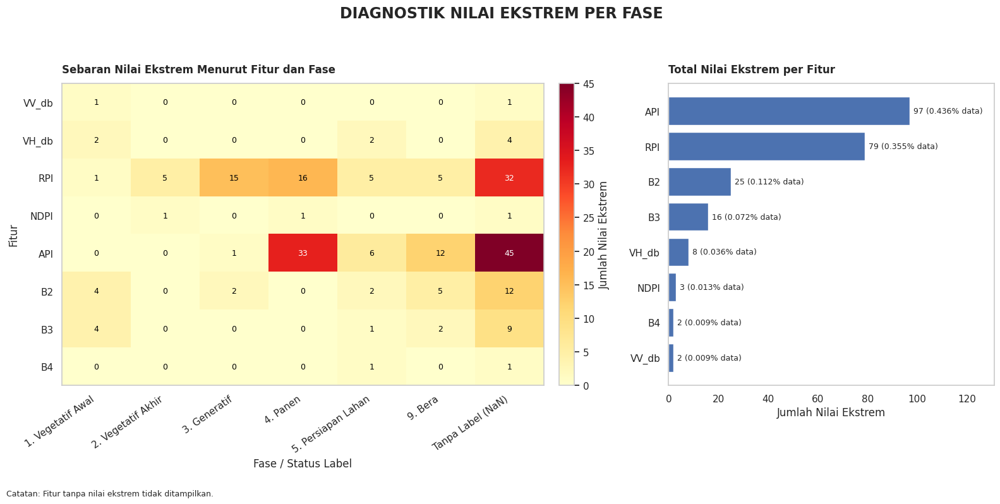

In [19]:
# ==============================================================================
# 6. VISUALISASI DIAGNOSTIK NILAI EKSTREM
# ==============================================================================
# Agregasi jumlah ekstrem berdasarkan fitur dan fase
df_heatmap = (
    hasil_diagnostik
    .groupby(['Fitur', 'Fase'], observed=False)['Jumlah_Ekstrem']
    .sum()
    .unstack(fill_value=0)
    .reindex(index=var_winsorize, columns=urutan_fase, fill_value=0)
)
# Tampilkan hanya fitur yang memiliki nilai ekstrem
df_heatmap = df_heatmap.loc[df_heatmap.sum(axis=1) > 0]
# Total ekstrem per fitur dan persentase dari seluruh data latih
total_ekstrem = df_heatmap.sum(axis=1)
persen_data = total_ekstrem / len(df_plot_outlier) * 100
# Buat figure
fig, (ax1, ax2) = plt.subplots(
    ncols=2,
    figsize=(16, 8),
    gridspec_kw={'width_ratios': [1.6, 1]}
)
# ------------------------------
# A. Heatmap jumlah ekstrem
# ------------------------------
im = ax1.imshow(
    df_heatmap.values,
    aspect='auto',
    cmap='YlOrRd',
    vmin=0,
    vmax=max(1, df_heatmap.values.max())
)
ax1.set_xticks(np.arange(len(urutan_fase)))
ax1.set_xticklabels(urutan_fase, rotation=35, ha='right')
ax1.set_yticks(np.arange(len(df_heatmap.index)))
ax1.set_yticklabels(df_heatmap.index)
ax1.set_title(
    'Sebaran Nilai Ekstrem Menurut Fitur dan Fase',
    loc='left',
    fontweight='bold',
    pad=12
)
ax1.set_xlabel('Fase / Status Label')
ax1.set_ylabel('Fitur')
ax1.grid(False)
# Angka pada setiap sel
for i in range(df_heatmap.shape[0]):
    for j in range(df_heatmap.shape[1]):
        value = df_heatmap.iloc[i, j]
        ax1.text(
            j, i, str(int(value)),
            ha='center',
            va='center',
            color='white' if value >= df_heatmap.values.max() * 0.5
            and value > 0 else 'black',
            fontsize=9
        )
cbar = fig.colorbar(im, ax=ax1, fraction=0.045, pad=0.03)
cbar.set_label('Jumlah Nilai Ekstrem')

# ------------------------------
# B. Diagram batang total ekstrem
# ------------------------------
total_urut = total_ekstrem.sort_values(ascending=True)
bars = ax2.barh(
    total_urut.index.astype(str),
    total_urut.values
)
ax2.set_title(
    'Total Nilai Ekstrem per Fitur',
    loc='left',
    fontweight='bold',
    pad=12
)
ax2.set_xlabel('Jumlah Nilai Ekstrem')
ax2.set_ylabel('')
ax2.grid(False)
for bar, fitur in zip(bars, total_urut.index):
    jumlah = total_urut[fitur]
    persen = persen_data[fitur]
    ax2.text(
        jumlah + max(total_urut.max() * 0.015, 0.5),
        bar.get_y() + bar.get_height() / 2,
        f'{int(jumlah)} ({persen:.3f}% data)',
        va='center',
        fontsize=9
    )
ax2.set_xlim(0, max(total_urut.max() * 1.35, 5))

# ------------------------------
# C. Judul dan simpan gambar
# ------------------------------
fig.suptitle('DIAGNOSTIK NILAI EKSTREM PER FASE', fontsize=17, fontweight='bold')
fig.text(0.01, 0.01, 'Catatan: Fitur tanpa nilai ekstrem tidak ditampilkan.', fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 0.94])
plt.savefig('diagnostik_nilai_ekstrem_per_fase.png', dpi=300, bbox_inches='tight')
plt.show()

In [20]:
df_train['API'].count()

np.int64(22272)

## *4. Winsorizing (Anti-Leakage: Fit hanya pada Train)*

TAHAP 4: WINSORIZING SELEKTIF (3 IQR) & VISUALISASI BATAS
Batas VV_db: Bawah = -21.6362 | Atas =   0.1891
Batas VH_db: Bawah = -32.4521 | Atas =  -3.3976
Batas RPI  : Bawah =  -0.3257 | Atas =   0.7346
Batas NDPI : Bawah =  -0.0584 | Atas =   1.3957
Batas API  : Bawah =  -0.0742 | Atas =   0.1854
Batas B2   : Bawah =  -0.0626 | Atas =   0.1768
Batas B3   : Bawah =  -0.0385 | Atas =   0.2012
Batas B4   : Bawah =  -0.1042 | Atas =   0.2577
Batas B8   : Bawah =  -0.2071 | Atas =   0.6364
Batas B11  : Bawah =  -0.2266 | Atas =   0.4776
Batas EVI  : Bawah =  -0.8752 | Atas =   1.5076
Batas LSWI : Bawah =  -0.6130 | Atas =   1.1709

Winsorizing 3 IQR Selesai!


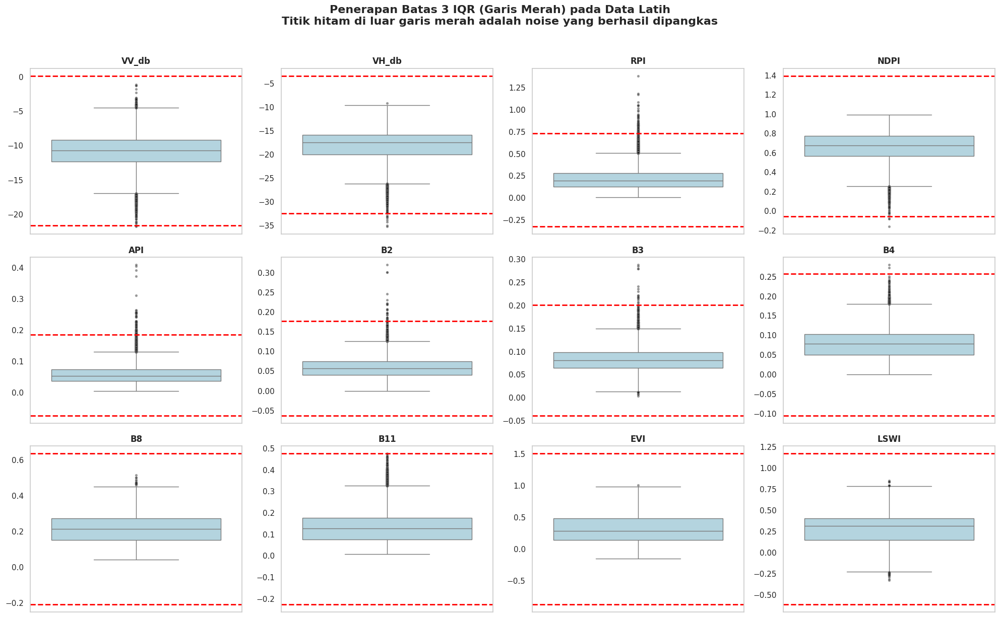

In [21]:
import math
# ==============================================================================
# TAHAP 4: WINSORIZING 3 IQR & VISUALISASI
# ==============================================================================
print("="*60)
print("TAHAP 4: WINSORIZING SELEKTIF (3 IQR) & VISUALISASI BATAS")
print("="*60)

var_winsorize = ['VV_db', 'VH_db', 'RPI', 'NDPI', 'API', 'B2', 'B3', 'B4', 'B8', 'B11', 'EVI', 'LSWI']

# 1. Simpan salinan data latih SEBELUM dipotong khusus untuk digambar di grafik
df_plot_outlier = df_train.copy()
batas_dict = {} # Tempat penampungan otomatis nilai batas

for col in var_winsorize:
    # 2. Hitung batas menggunakan satu baris perintah berkat array [0.25, 0.75]
    Q1, Q3 = df_train[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    batas_bawah, batas_atas = Q1 - (3 * IQR), Q3 + (3 * IQR)

    # 3. Simpan ke dictionary dan cetak ke layar
    batas_dict[col] = (batas_bawah, batas_atas)
    print(f"Batas {col:<5}: Bawah = {batas_bawah:>8.4f} | Atas = {batas_atas:>8.4f}")

    # 4. Terapkan pemotongan (clipping) ke semua split
    df_train[col] = df_train[col].clip(batas_bawah, batas_atas)
    df_val[col]   = df_val[col].clip(batas_bawah, batas_atas)
    df_test[col]  = df_test[col].clip(batas_bawah, batas_atas)

print("\nWinsorizing 3 IQR Selesai!")
df_sebelum_smooth = df_train.copy() # Simpan untuk perbandingan dengan S-G Smoothing nanti

# VISUALISASI
n_cols = 4
n_rows = math.ceil(len(var_winsorize) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(var_winsorize):
    bb, ba = batas_dict[col] # Panggil batas dari dictionary

    # Gambar boxplot dari data yang belum terpotong agar noise aslinya terlihat
    sns.boxplot(y=df_plot_outlier[col], ax=axes[i], color='lightblue',
                flierprops={'marker': 'o', 'markerfacecolor': 'black', 'markersize': 3, 'alpha': 0.4})

    # Gambar garis batas pemotongan (Merah Putus-putus)
    axes[i].axhline(bb, color='red', linestyle='--', linewidth=2)
    axes[i].axhline(ba, color='red', linestyle='--', linewidth=2)

    # Kosmetik grafik
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_ylabel('')
    axes[i].grid(False)

# Hapus sisa kanvas kosong jika jumlah variabel tidak kelipatan 4
for j in range(len(var_winsorize), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Penerapan Batas 3 IQR (Garis Merah) pada Data Latih\nTitik hitam di luar garis merah adalah noise yang berhasil dipangkas",
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [22]:
# Melihat daftar nilai yang ada di masing-masing kolom
print("Nilai unik Label BPS:", df_train['Label_BPS'].unique())
print("Nilai unik Label Generatif:", df_train['Label_Generatif'].unique())
print("Nilai unik Label Panen:", df_train['Label_Panen'].unique())

Nilai unik Label BPS: [nan 4.  5.  1.  3.  2.  3.3 3.1 3.2]
Nilai unik Label Generatif: [nan  4.  5.  1.  3.  2.]
Nilai unik Label Panen: [nan  4.  5.  1.  3.  2.  9.]


## *5. Savitzky-Golay Smoothing*

In [23]:
# ==============================================================================
# TAHAP 5: SAVITZKY-GOLAY SMOOTHING
# (Urutan ke-5 dalam pipeline preprocessing)
# Diterapkan secara terpisah per split untuk mencegah kebocoran temporal.
# ==============================================================================
print("="*60)
print("TAHAP 5: SAVITZKY-GOLAY SMOOTHING (Window=5, Poly=2)")
print("="*60)

def terapkan_savgol(x):
    if len(x.dropna()) >= 5:
        return savgol_filter(x, window_length=5, polyorder=2, mode='interp')
    return x

for split_name, df_split in [('TRAIN', df_train), ('VAL', df_val), ('TEST', df_test)]:
    for fitur in fitur_citra:
        df_split[fitur] = df_split.groupby(
            ['TitikAmatX', 'TitikAmatY', 'Tahun']
        )[fitur].transform(terapkan_savgol)
    print(f"   Smoothing pada {split_name} selesai.")

print("\nSavitzky-Golay Smoothing Selesai!\n")

TAHAP 5: SAVITZKY-GOLAY SMOOTHING (Window=5, Poly=2)
   Smoothing pada TRAIN selesai.
   Smoothing pada VAL selesai.
   Smoothing pada TEST selesai.

Savitzky-Golay Smoothing Selesai!



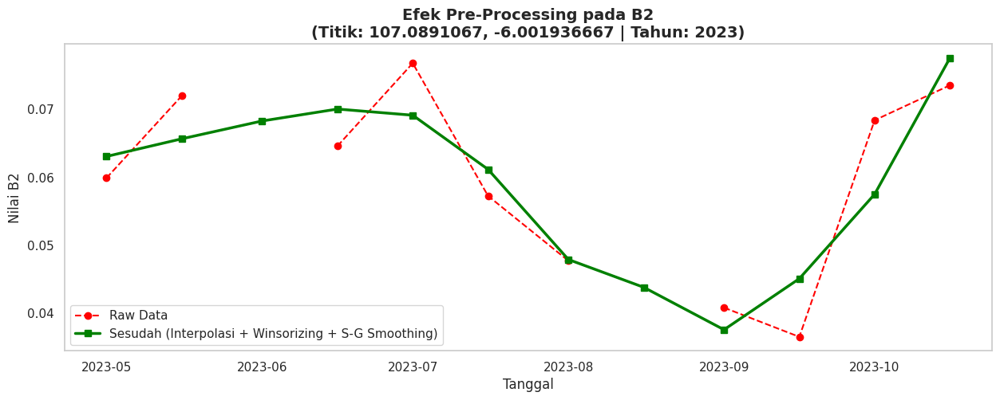

In [24]:
# ==============================================================================
# Visualisasi
# ==============================================================================
# Mengambil sampel titik koordinat secara acak
sampel_x     = df_train['TitikAmatX'].iloc[1]
sampel_y     = df_train['TitikAmatY'].iloc[1]
sampel_tahun = df_train['Tahun'].iloc[1]

sinyal_kotor = df_mentah_kotor[
    (df_mentah_kotor['TitikAmatX'] == sampel_x) &
    (df_mentah_kotor['TitikAmatY'] == sampel_y) &
    (df_mentah_kotor['Tahun'] == sampel_tahun)
]
sinyal_mulus = df_train[
    (df_train['TitikAmatX'] == sampel_x) &
    (df_train['TitikAmatY'] == sampel_y) &
    (df_train['Tahun'] == sampel_tahun)
]

plt.figure(figsize=(15, 5))
plt.plot(sinyal_kotor['Tanggal'], sinyal_kotor['B2'],
         marker='o', linestyle='--', color='red', label='Raw Data')
plt.plot(sinyal_mulus['Tanggal'], sinyal_mulus['B2'],
         marker='s', linestyle='-', color='green', linewidth=2.5,
         label='Sesudah (Interpolasi + Winsorizing + S-G Smoothing)')
plt.title(f'Efek Pre-Processing pada B2\n(Titik: {sampel_x}, {sampel_y} | Tahun: {sampel_tahun})',
          fontsize=14, fontweight='bold')
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Nilai B2', fontsize=12)
plt.legend(); plt.grid(False)
plt.show()

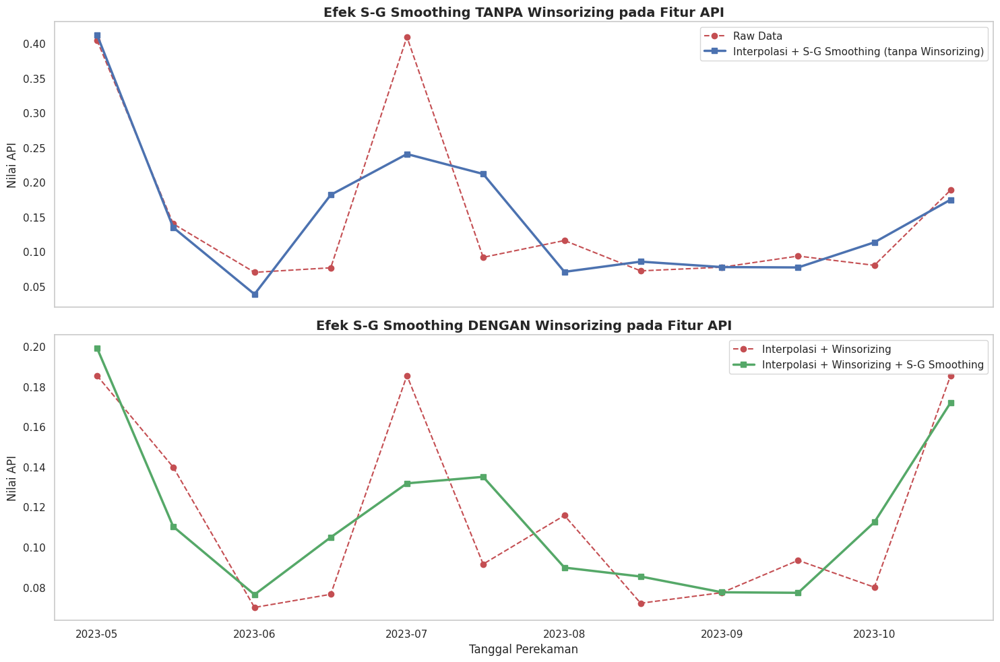

In [25]:
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# ==============================================================================
# 1. PENGATURAN PARAMETER VISUALISASI
# ==============================================================================
target_x, target_y, target_tahun = 107.3890357, -6.437172864, 2023
fitur_plot = 'API'

def ambil_sinyal(df):
    return df[(df['TitikAmatX'] == target_x) &
              (df['TitikAmatY'] == target_y) &
              (df['Tahun'] == target_tahun)].sort_values('Tanggal')

# ==============================================================================
# 2. EKSTRAKSI SINYAL PER TAHAP
# ==============================================================================
sinyal_kotor  = ambil_sinyal(df_mentah_kotor)    # Raw, belum diapa-apakan
sinyal_prep   = ambil_sinyal(df_prep)            # Interpolasi saja, TANPA winsorizing
sinyal_winsor = ambil_sinyal(df_sebelum_smooth)  # Interpolasi + winsorizing, belum SG
sinyal_mulus  = ambil_sinyal(df_train)           # Interpolasi + winsorizing + SG (pipeline final)

# SG diterapkan langsung ke sinyal_prep (tanpa winsorizing lebih dulu) — cabang baru
# untuk perbandingan; window/polyorder harus sama dengan pipeline asli agar adil
sinyal_prep_sg = sinyal_prep.copy()
sinyal_prep_sg[fitur_plot] = savgol_filter(sinyal_prep_sg[fitur_plot], window_length=5, polyorder=2, mode='interp')

# ==============================================================================
# 3. VISUALISASI
# ==============================================================================
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# --- Gambar 1: Raw vs Interpolasi + SG (TANPA winsorizing) ---
axes[0].plot(sinyal_kotor['Tanggal'], sinyal_kotor[fitur_plot], 'ro--', label='Raw Data')
axes[0].plot(sinyal_prep_sg['Tanggal'], sinyal_prep_sg[fitur_plot], 'bs-', linewidth=2.5,
             label='Interpolasi + S-G Smoothing (tanpa Winsorizing)')
axes[0].set_title(f'Efek S-G Smoothing TANPA Winsorizing pada Fitur {fitur_plot}', fontsize=14, fontweight='bold')
axes[0].set_ylabel(f'Nilai {fitur_plot}'); axes[0].legend(); axes[0].grid(False)

# --- Gambar 2: Raw+Winsorizing vs Interpolasi + Winsorizing + SG ---
axes[1].plot(sinyal_winsor['Tanggal'], sinyal_winsor[fitur_plot], 'ro--', label='Interpolasi + Winsorizing')
axes[1].plot(sinyal_mulus['Tanggal'], sinyal_mulus[fitur_plot], 'gs-', linewidth=2.5,
             label='Interpolasi + Winsorizing + S-G Smoothing')
axes[1].set_title(f'Efek S-G Smoothing DENGAN Winsorizing pada Fitur {fitur_plot}', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Tanggal Perekaman'); axes[1].set_ylabel(f'Nilai {fitur_plot}')
axes[1].legend(); axes[1].grid(False)

plt.tight_layout()
plt.show()

# **Analisis Data**

## *Analisis Pertama*


1. STATISTIK DESKRIPTIF PASCA PREPROCESSING


,count,mean,std,min,25%,50%,75%,max
VV_db,27816.0,-10.868,2.299,-21.191,-12.135,-10.671,-9.354,-0.540
VH_db,27816.0,-18.217,3.113,-32.105,-19.932,-17.474,-15.966,-9.957
RPI,27816.0,0.218,0.101,-0.023,0.143,0.205,0.278,0.774
NDPI,27816.0,0.658,0.127,-0.049,0.576,0.667,0.752,1.012
API,27816.0,0.058,0.028,-0.004,0.040,0.055,0.074,0.203
B2,27816.0,0.058,0.022,-0.006,0.042,0.057,0.073,0.200
B3,27816.0,0.082,0.023,0.000,0.066,0.082,0.097,0.198
B4,27816.0,0.079,0.033,-0.004,0.054,0.080,0.101,0.235
B8,27816.0,0.218,0.070,0.044,0.158,0.216,0.271,0.500
B11,27816.0,0.138,0.077,-0.012,0.079,0.128,0.179,0.484



2. HEATMAP MISSING VALUE PASCA INTERPOLASI


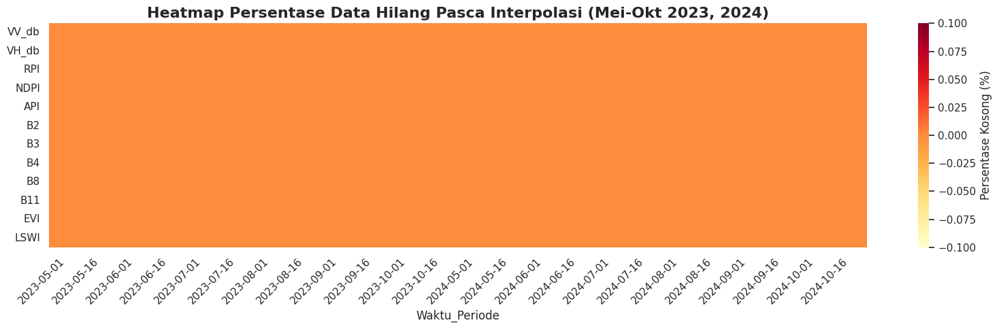


3. MATRIKS KORELASI ANTAR FITUR


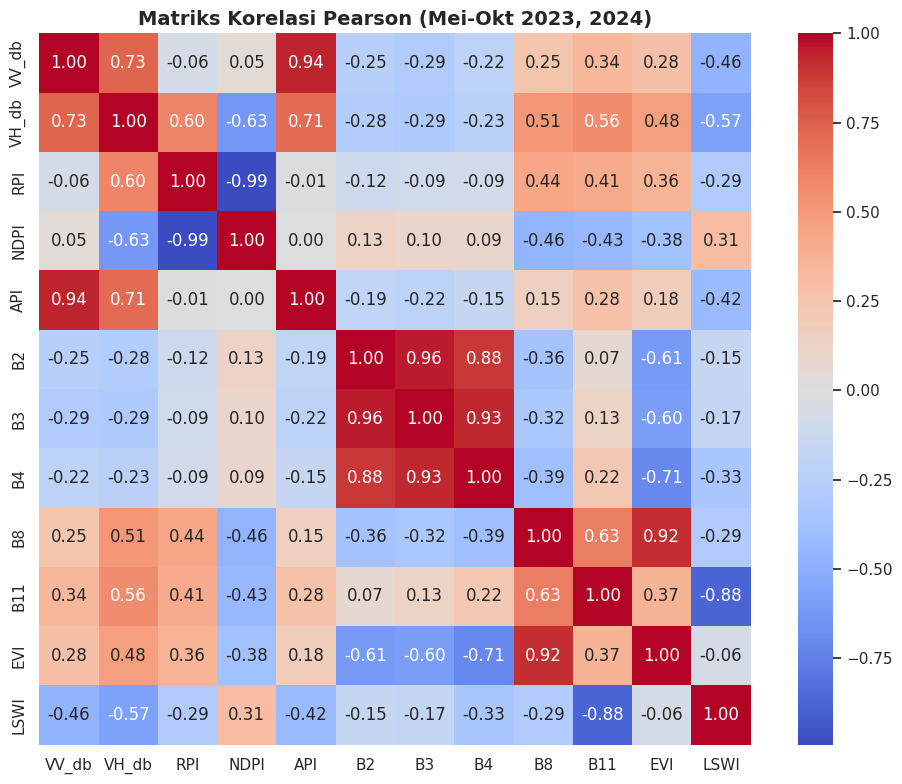


4. DISTRIBUSI KELAS LABEL FINAL


,Jumlah,Persentase (%)
Nama_Fase,,
1. Vegetatif Awal,2494,17.93
2. Vegetatif Akhir,1726,12.41
3. Generatif,2695,19.38
4. Panen,2323,16.70
5. Persiapan Lahan,2695,19.38
9. Bera,1975,14.20


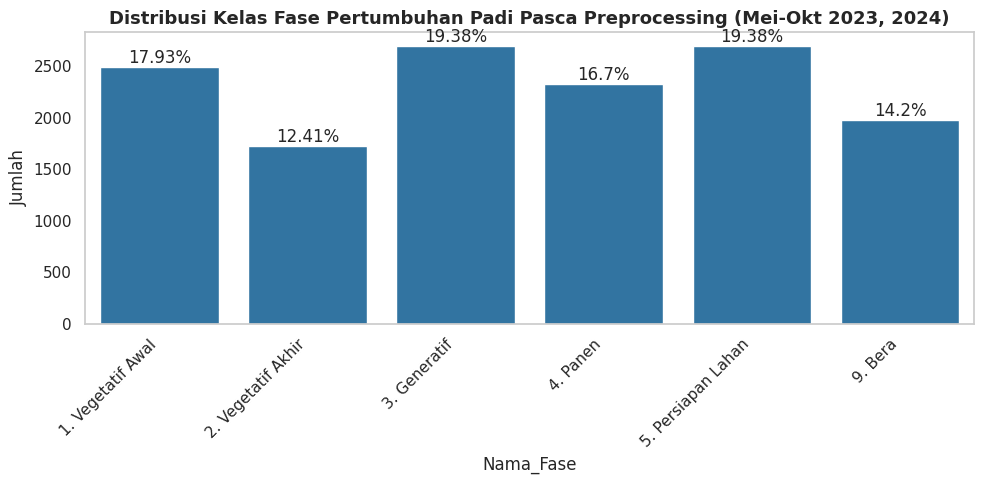


5. TREN FASE TANAM PER BULAN


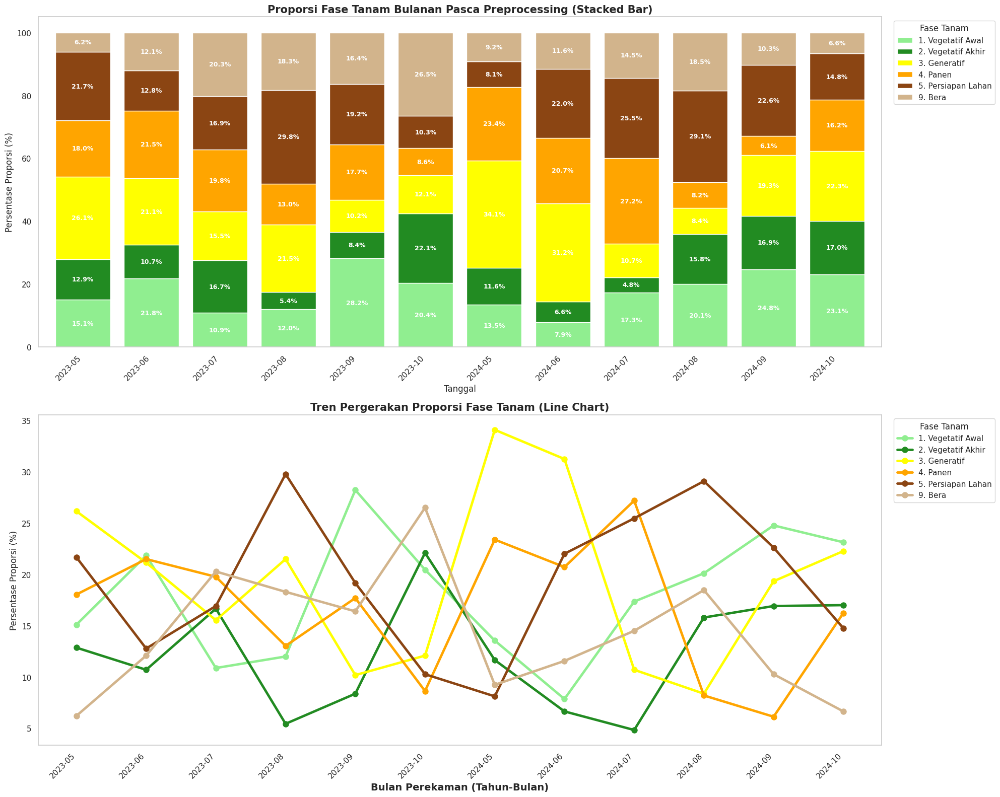


6. BOXPLOT OVERALL PER VARIABEL (PASCA PREPROCESSING)



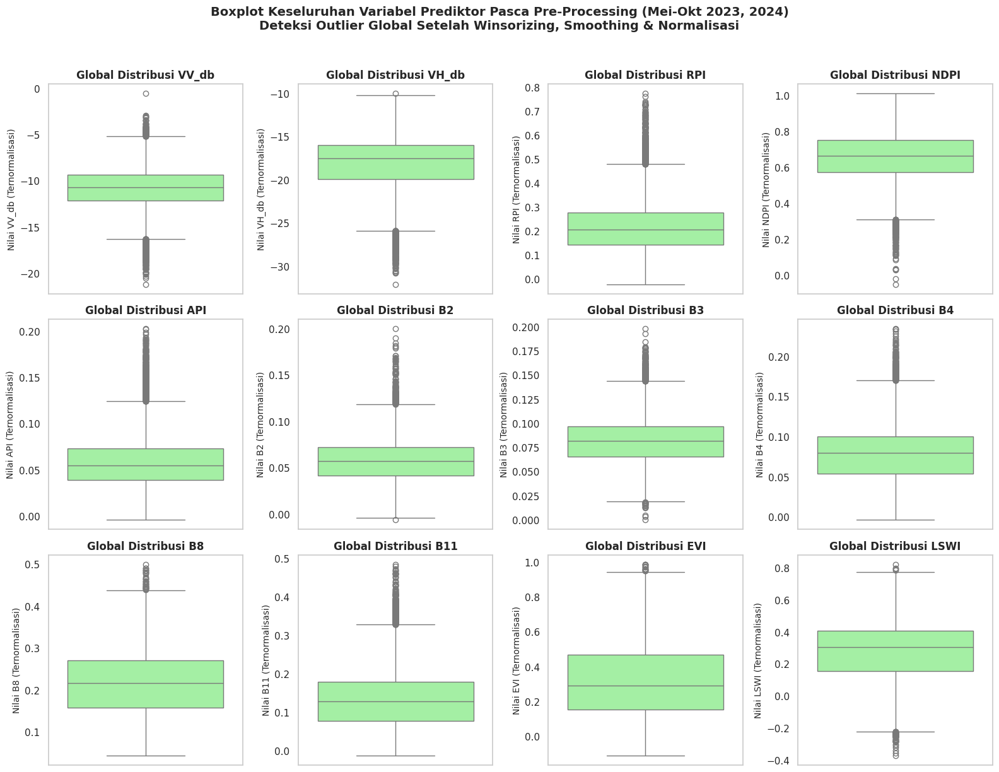


7. BOXPLOT DISTRIBUSI FITUR PER FASE TANAM



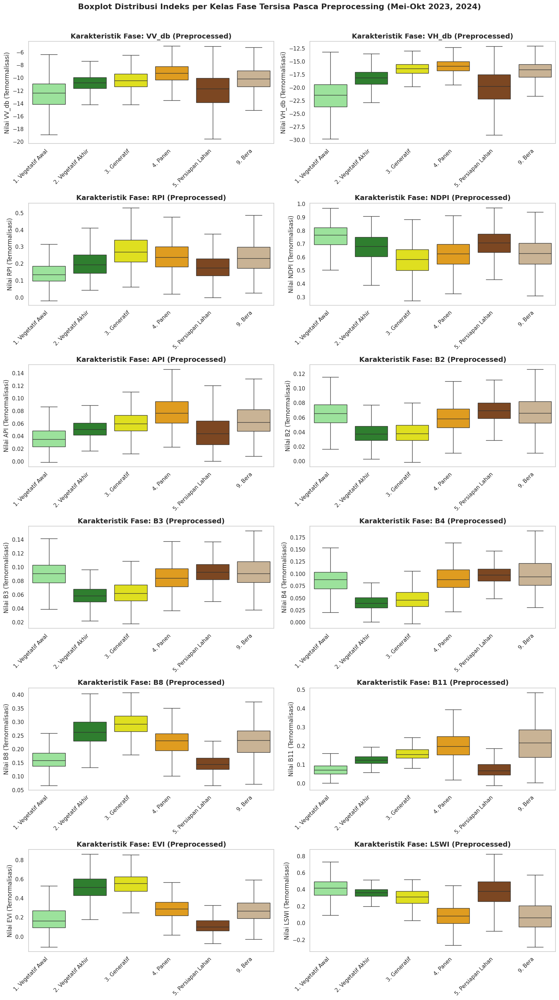


📋 Ringkasan Nilai Median per Fase (Data Ternormalisasi):


,VV_db,VH_db,RPI,NDPI,API,B2,B3,B4,B8,B11,EVI,LSWI
Nama_Fase,,,,,,,,,,,,
1. Vegetatif Awal,-12.3764,-21.4187,0.1345,0.7669,0.0352,0.0659,0.0912,0.0881,0.1580,0.0706,0.1652,0.4166
2. Vegetatif Akhir,-10.7761,-18.1107,0.1934,0.6821,0.0511,0.0374,0.0584,0.0394,0.2628,0.1245,0.5167,0.3643
3. Generatif,-10.4089,-16.3820,0.2696,0.5832,0.0596,0.0379,0.0625,0.0463,0.2921,0.1545,0.5558,0.3145
4. Panen,-9.2368,-15.8516,0.2378,0.6246,0.0767,0.0583,0.0841,0.0883,0.2313,0.1970,0.2911,0.0871
5. Persiapan Lahan,-11.7161,-19.7400,0.1752,0.7080,0.0444,0.0697,0.0931,0.0974,0.1446,0.0664,0.1034,0.3804
9. Bera,-10.1202,-16.5390,0.2325,0.6297,0.0623,0.0660,0.0910,0.0940,0.2329,0.2166,0.2685,0.0649



8. VISUALISASI HISTOGRAM OVERALL PER VARIABEL (PASCA PREPROCESSING)



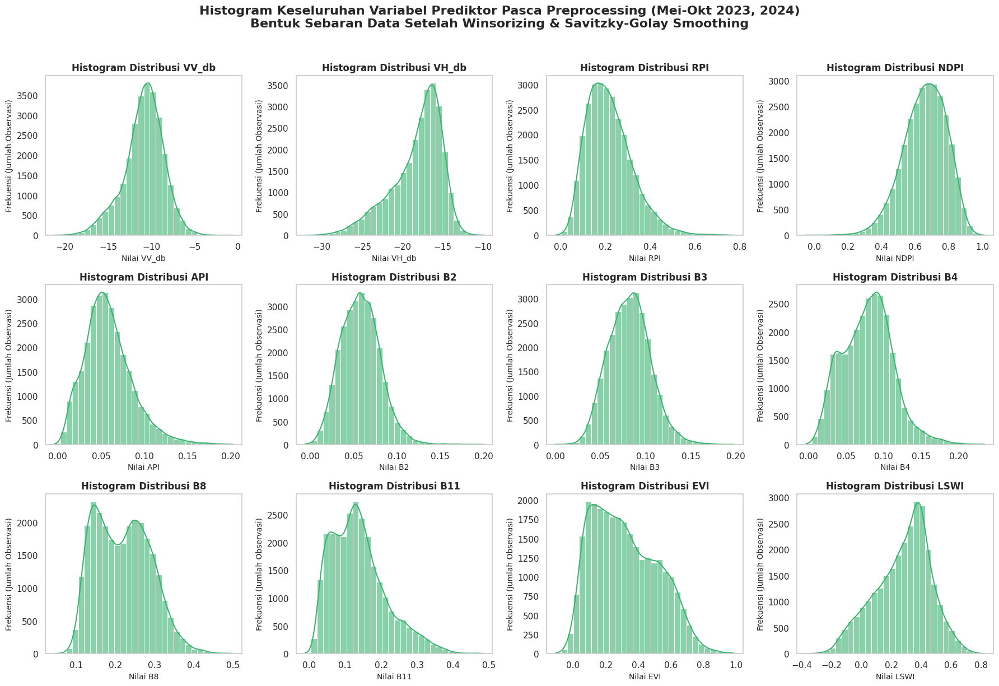

In [26]:
# ==============================================================================
# ANALISIS DESKRIPTIF PASCA PREPROCESSING
# (Data masih dalam format DataFrame 2D)
# ==============================================================================
# Gabung kembali semua split untuk analisis deskriptif menyeluruh
df_bersih_eval = pd.concat([df_train, df_val, df_test], ignore_index=True)
df_bersih_eval['Nama_Fase'] = df_bersih_eval['Label_Final'].map(label_map_baru)

# ==============================================================================
# 1. ANALISIS DESKRIPTIF STATISTIK
# ==============================================================================
print("\n" + "="*60)
print("1. STATISTIK DESKRIPTIF PASCA PREPROCESSING")
print("="*60)
display(df_bersih_eval[fitur_citra].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(3))

# ==============================================================================
# 2. HEATMAP MISSING VALUE (Harusnya 0% Semua)
# ==============================================================================
print("\n" + "="*60)
print("2. HEATMAP MISSING VALUE PASCA INTERPOLASI")
print("="*60)

df_bersih_eval['Waktu_Periode'] = df_bersih_eval['Tanggal'].dt.strftime('%Y-%m-%d')
missing_per_periode = df_bersih_eval.groupby('Waktu_Periode', sort=False)[fitur_citra].apply(
    lambda x: (x.isnull().mean() * 100)
).round(2)

plt.figure(figsize=(16, 5))
sns.heatmap(missing_per_periode.T, cmap="YlOrRd", cbar_kws={'label': 'Persentase Kosong (%)'})
plt.title(f'Heatmap Persentase Data Hilang Pasca Interpolasi (Mei-Okt {teks_tahun})',
          fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. MATRIKS KORELASI ANTAR FITUR
# ==============================================================================
print("\n" + "="*60)
print("3. MATRIKS KORELASI ANTAR FITUR")
print("="*60)

plt.figure(figsize=(10, 8))
sns.heatmap(df_bersih_eval[fitur_citra].corr(), annot=True, cmap='coolwarm',
            fmt=".2f", square=True)
plt.title(f'Matriks Korelasi Pearson (Mei-Okt {teks_tahun})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==============================================================================
# 4. DISTRIBUSI KELAS LABEL (DATA BERSIH)
# ==============================================================================
print("\n" + "="*60)
print("4. DISTRIBUSI KELAS LABEL FINAL")
print("="*60)

df_label_ok = df_bersih_eval.dropna(subset=['Label_Final']).copy()
df_label_ok['Nama_Fase'] = df_label_ok['Label_Final'].map(label_map_baru)

kategori_valid_urutan = [k for k in custom_palette_baru.keys() if k in df_label_ok['Nama_Fase'].unique()]
df_label_ok['Nama_Fase'] = pd.Categorical(df_label_ok['Nama_Fase'], categories=kategori_valid_urutan, ordered=True)

label_counts = df_label_ok['Nama_Fase'].value_counts(dropna=True).loc[kategori_valid_urutan]
df_dist = pd.DataFrame({
    'Jumlah'         : label_counts,
    'Persentase (%)' : (label_counts / label_counts.sum() * 100).round(2)
})
display(df_dist)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=df_dist.index, y=df_dist['Jumlah'], color='#1f77b4')
plt.title(f'Distribusi Kelas Fase Pertumbuhan Padi Pasca Preprocessing (Mei-Okt {teks_tahun})',
          fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
for i, p in enumerate(ax.patches):
    ax.annotate(f"{df_dist['Persentase (%)'].iloc[i]}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.grid(False)
plt.show()

# ==============================================================================
# 5. TREN FASE TANAM PER BULAN
# ==============================================================================
print("\n" + "="*60)
print("5. TREN FASE TANAM PER BULAN")
print("="*60)

tren_bersih_pct = pd.crosstab(
    df_label_ok['Tanggal'].dt.strftime('%Y-%m'),
    df_label_ok['Nama_Fase'],
    normalize='index'
) * 100

fase_tersedia_baru  = [f for f in custom_palette_baru.keys() if f in tren_bersih_pct.columns]
tren_bersih_pct     = tren_bersih_pct[fase_tersedia_baru]
warna_bersih        = [custom_palette_baru[f] for f in fase_tersedia_baru]

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(20, 16))

# --- 1. BAR CHART ---
tren_bersih_pct.plot(kind='bar', stacked=True, color=warna_bersih, width=0.8, ax=axes[0])
axes[0].set_title(f'Proporsi Fase Tanam Bulanan Pasca Preprocessing (Stacked Bar)',
                  fontsize=15, fontweight='bold')
for c in axes[0].containers:
    labels = [f'{v.get_height():.1f}%' if v.get_height() > 3 else '' for v in c]
    axes[0].bar_label(c, labels=labels, label_type='center', fontsize=9,
                      color='white', fontweight='bold')
    axes[0].grid(False)

# --- 2. LINE CHART ---
tren_bersih_pct.plot(kind='line', ax=axes[1], color=warna_bersih,
                     linewidth=3.5, marker='o', markersize=8)
axes[1].set_title('Tren Pergerakan Proporsi Fase Tanam (Line Chart)',
                  fontsize=15, fontweight='bold')
axes[1].set_xlabel('Bulan Perekaman (Tahun-Bulan)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Persentase Proporsi (%)', fontsize=12)
axes[1].legend(title='Fase Tanam', bbox_to_anchor=(1.01, 1), loc='upper left')
axes[1].grid(False)

for ax in axes:
    ax.set_ylabel('Persentase Proporsi (%)', fontsize=12)
    ax.set_xticks(range(len(tren_bersih_pct.index)))
    ax.set_xticklabels(tren_bersih_pct.index)
    ax.tick_params(axis='x', rotation=45)
    for tick in ax.get_xticklabels():
        tick.set_ha('right')
    ax.legend(title='Fase Tanam', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

# ==============================================================================
# 6. BOXPLOT DISTRIBUSI FITUR OVERALL (PASCA PRE-PROCESSING)
# ==============================================================================
print("\n" + "="*60)
print("6. BOXPLOT OVERALL PER VARIABEL (PASCA PREPROCESSING)")
print("="*60 + "\n")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, fitur in enumerate(fitur_citra):
    if fitur in df_bersih_eval.columns:
        sns.boxplot(y=df_bersih_eval[fitur], ax=axes[i],
                    color='#98FB98', showfliers=True)
        axes[i].set_title(f'Global Distribusi {fitur}', fontsize=12, fontweight='bold')
        axes[i].set_ylabel(f'Nilai {fitur} (Ternormalisasi)', fontsize=10)
        axes[i].grid(False)

plt.suptitle(
    f'Boxplot Keseluruhan Variabel Prediktor Pasca Pre-Processing (Mei-Okt {teks_tahun})\n'
    f'Deteksi Outlier Global Setelah Winsorizing, Smoothing & Normalisasi',
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

# ==============================================================================
# 7. BOXPLOT DISTRIBUSI FITUR PER FASE TANAM
# ==============================================================================
print("\n" + "="*60)
print("7. BOXPLOT DISTRIBUSI FITUR PER FASE TANAM")
print("="*60 + "\n")

df_box_bersih = df_bersih_eval.dropna(subset=['Label_Final']).copy()
df_box_bersih['Nama_Fase'] = df_box_bersih['Label_Final'].map(label_map_baru)
kategori_valid = [k for k in custom_palette_baru.keys() if k in df_box_bersih['Nama_Fase'].unique()]
df_box_bersih['Nama_Fase'] = pd.Categorical(df_box_bersih['Nama_Fase'],
                                             categories=kategori_valid, ordered=True)

fig, axes = plt.subplots(6, 2, figsize=(16, 28))
axes = axes.flatten()

for i, fitur in enumerate(fitur_citra):
    if fitur in df_box_bersih.columns:
        sns.boxplot(data=df_box_bersih, x='Nama_Fase', y=fitur,
                    hue='Nama_Fase', palette=custom_palette_baru, ax=axes[i],
                    showfliers=False, legend=False)
        axes[i].set_title(f'Karakteristik Fase: {fitur} (Preprocessed)', fontsize=14, fontweight='bold')
        axes[i].set_xlabel('')
        axes[i].set_ylabel(f'Nilai {fitur} (Ternormalisasi)', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)
        for tick in axes[i].get_xticklabels():
            tick.set_ha('right')
        axes[i].grid(False)

plt.suptitle(
    f'Boxplot Distribusi Indeks per Kelas Fase Tersisa Pasca Preprocessing (Mei-Okt {teks_tahun})',
    fontsize=16, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.show()

print("\n📋 Ringkasan Nilai Median per Fase (Data Ternormalisasi):")
display(df_box_bersih.groupby('Nama_Fase', observed=False)[fitur_citra].median().round(4))

# ==============================================================================
# 8. HISTOGRAM DISTRIBUSI FITUR OVERALL (PASCA PREPROCESSING)
# ==============================================================================
print("\n" + "="*60)
print("8. VISUALISASI HISTOGRAM OVERALL PER VARIABEL (PASCA PREPROCESSING)")
print("="*60 + "\n")

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

# Looping menggunakan df_bersih_eval
for i, fitur in enumerate(fitur_citra):
    if fitur in df_bersih_eval.columns:
        # Menggunakan warna hijau ('mediumseagreen') untuk menandakan data sudah bersih
        sns.histplot(
            data=df_bersih_eval,
            x=fitur,
            ax=axes[i],
            color='mediumseagreen',
            bins=30,
            kde=True,
            alpha=0.6
        )
        axes[i].set_title(f'Histogram Distribusi {fitur}', fontsize=12, fontweight='bold')
        # Sesuaikan keterangan sumbu X dengan status normalisasi saat ini
        axes[i].set_xlabel(f'Nilai {fitur}', fontsize=10)
        axes[i].set_ylabel('Frekuensi (Jumlah Observasi)', fontsize=10)
        axes[i].grid(False)

plt.suptitle(f'Histogram Keseluruhan Variabel Prediktor Pasca Preprocessing (Mei-Okt {teks_tahun})\nBentuk Sebaran Data Setelah Winsorizing & Savitzky-Golay Smoothing',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


5. TREN FASE TANAM PER BULAN (GRAFIK PER TAHUN)

----------------------------------------
MENGHASILKAN GRAFIK UNTUK TAHUN 2023
----------------------------------------


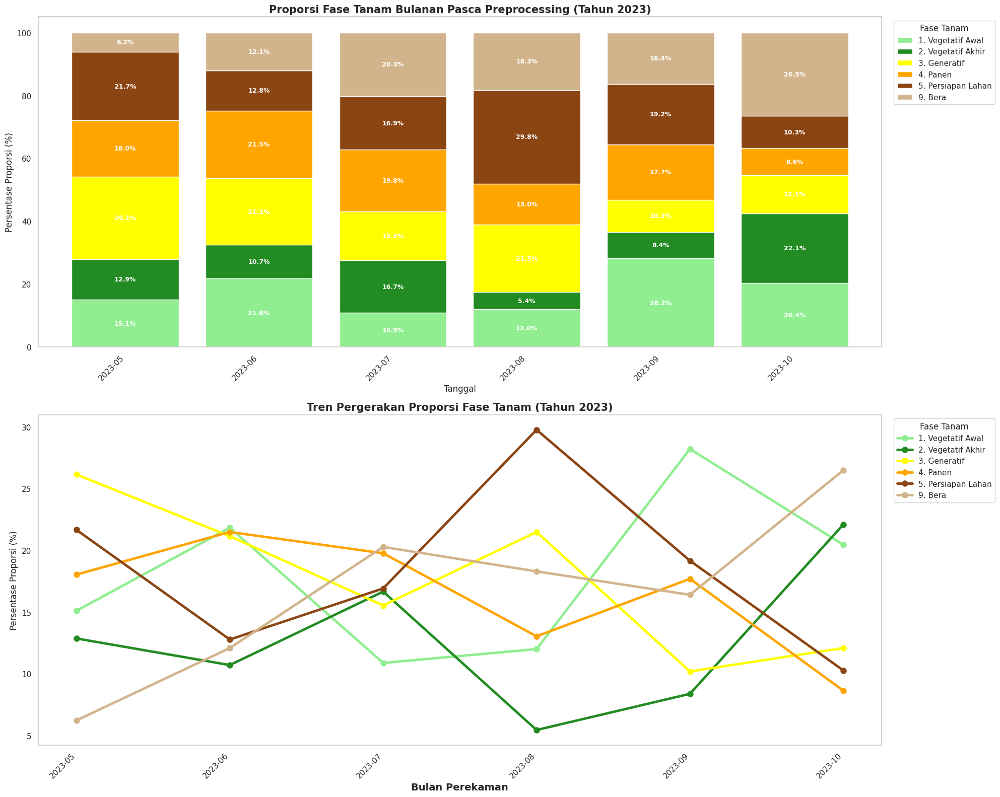


----------------------------------------
MENGHASILKAN GRAFIK UNTUK TAHUN 2024
----------------------------------------


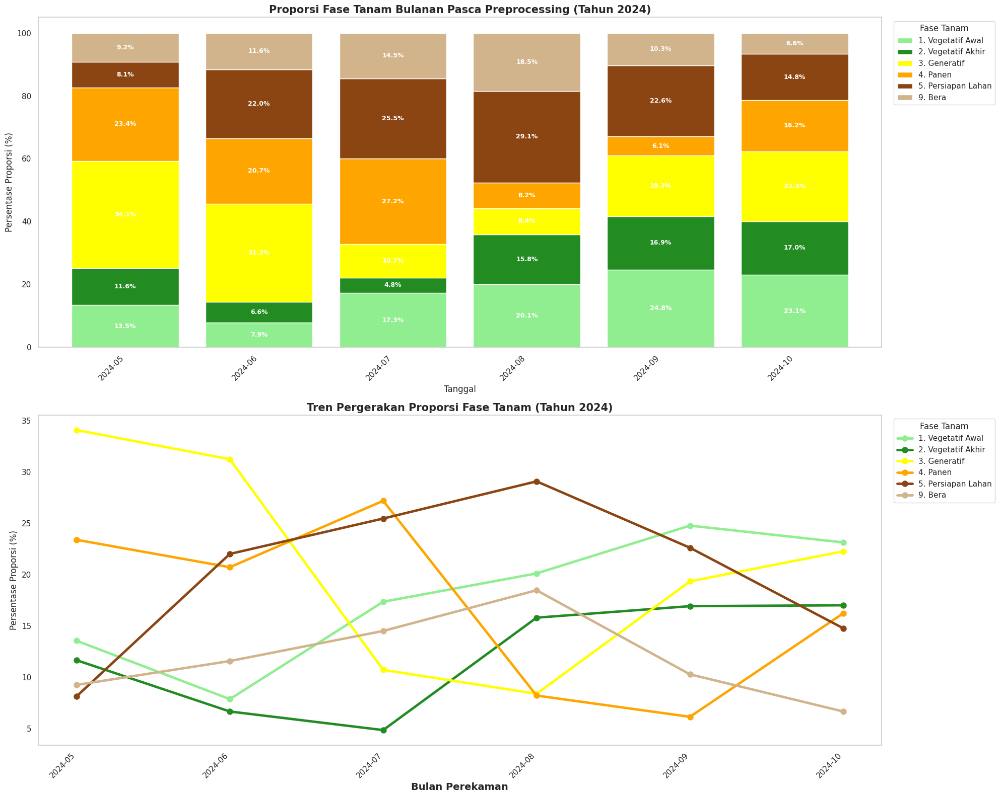

In [27]:
# ==============================================================================
# 5. TREN FASE TANAM PER BULAN (DIPISAH PER TAHUN)
# ==============================================================================
print("\n" + "="*60)
print("5. TREN FASE TANAM PER BULAN (GRAFIK PER TAHUN)")
print("="*60)

# Pastikan tipe data kolom Tanggal sudah datetime (sebagai pengaman)
df_label_ok['Tanggal'] = pd.to_datetime(df_label_ok['Tanggal'])

# Mengambil daftar tahun unik dari data secara otomatis (akan menghasilkan [2023, 2024])
daftar_tahun = df_label_ok['Tanggal'].dt.year.unique()

# Melakukan perulangan untuk mencetak grafik setiap tahun
for tahun in sorted(daftar_tahun):
    print(f"\n" + "-"*40)
    print(f"MENGHASILKAN GRAFIK UNTUK TAHUN {tahun}")
    print("-"  *40)

    # 1. Filter dataset agar hanya berisi data pada tahun yang sedang diloop
    df_tahun_ini = df_label_ok[df_label_ok['Tanggal'].dt.year == tahun].copy()

    # 2. Hitung persentase proporsi hanya untuk tahun tersebut
    tren_bersih_pct = pd.crosstab(
        df_tahun_ini['Tanggal'].dt.strftime('%Y-%m'),
        df_tahun_ini['Nama_Fase'],
        normalize='index'
    ) * 100

    fase_tersedia_baru  = [f for f in custom_palette_baru.keys() if f in tren_bersih_pct.columns]
    tren_bersih_pct     = tren_bersih_pct[fase_tersedia_baru]
    warna_bersih        = [custom_palette_baru[f] for f in fase_tersedia_baru]

    # 3. Visualisasi
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(20, 16))

    # --- 1. BAR CHART ---
    tren_bersih_pct.plot(kind='bar', stacked=True, color=warna_bersih, width=0.8, ax=axes[0])
    axes[0].set_title(f'Proporsi Fase Tanam Bulanan Pasca Preprocessing (Tahun {tahun})',
                      fontsize=15, fontweight='bold')
    for c in axes[0].containers:
        labels = [f'{v.get_height():.1f}%' if v.get_height() > 3 else '' for v in c]
        axes[0].bar_label(c, labels=labels, label_type='center', fontsize=9,
                          color='white', fontweight='bold')
        axes[0].grid(False)

    # --- 2. LINE CHART ---
    tren_bersih_pct.plot(kind='line', ax=axes[1], color=warna_bersih,
                         linewidth=3.5, marker='o', markersize=8)
    axes[1].set_title(f'Tren Pergerakan Proporsi Fase Tanam (Tahun {tahun})',
                      fontsize=15, fontweight='bold')
    axes[1].set_xlabel('Bulan Perekaman', fontsize=14, fontweight='bold')
    axes[1].grid(False)

    # --- Pengaturan Sumbu dan Legenda ---
    for ax in axes:
        ax.set_ylabel('Persentase Proporsi (%)', fontsize=12)
        ax.set_xticks(range(len(tren_bersih_pct.index)))

        # Sumbu X (YYYY-MM)
        ax.set_xticklabels(tren_bersih_pct.index)
        ax.tick_params(axis='x', rotation=45)
        for tick in ax.get_xticklabels():
            tick.set_ha('right')

        ax.legend(title='Fase Tanam', bbox_to_anchor=(1.01, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

## *Analisis Boxplot Before After Preprocessing*


8. PERBANDINGAN DISTRIBUSI FITUR: SEBELUM VS SESUDAH PREPROCESSING


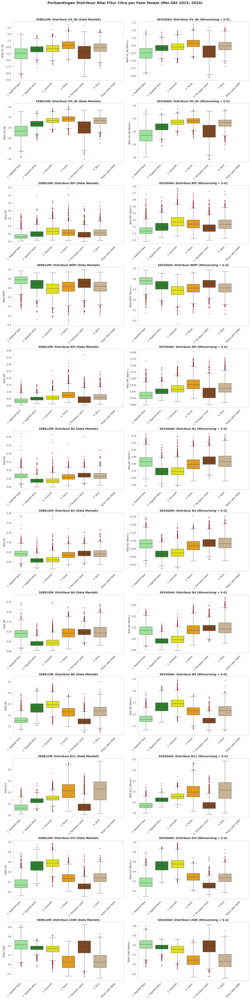

In [28]:
# ==============================================================================
# 8. PERBANDINGAN BOXPLOT SEBELUM VS SESUDAH PREPROCESSING (PER FASE TANAM)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

print("\n" + "="*80)
print("8. PERBANDINGAN DISTRIBUSI FITUR: SEBELUM VS SESUDAH PREPROCESSING")
print("="*80)

df_mentah_plot = df_mentah_kotor.dropna(subset=['Label_Final']).copy()
df_mentah_plot['Nama_Fase'] = df_mentah_plot['Label_Final'].map(label_map_baru)
df_mentah_plot = df_mentah_plot.dropna(subset=['Nama_Fase'])

df_prep_plot = df_bersih_eval.dropna(subset=['Label_Final']).copy()
df_prep_plot = df_prep_plot.dropna(subset=['Nama_Fase'])

# urutan_fase = [k for k in custom_palette_baru.keys() if k in df_prep_plot['Nama_Fase'].unique()]

fig, axes = plt.subplots(nrows=len(fitur_citra), ncols=2, figsize=(18, 6 * len(fitur_citra)))

for i, fitur in enumerate(fitur_citra):
    sns.boxplot(data=df_mentah_plot, x='Nama_Fase', y=fitur, ax=axes[i, 0],
                hue='Nama_Fase', legend=False, palette=custom_palette_baru, order=urutan_fase,
                flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 4, 'alpha': 0.5})
    axes[i, 0].set_title(f'SEBELUM: Distribusi {fitur} (Data Mentah)', fontsize=14, fontweight='bold')
    axes[i, 0].set_xlabel(''); axes[i, 0].set_ylabel(f'Nilai {fitur}', fontsize=12)
    axes[i, 0].tick_params(axis='x', rotation=45)
    axes[i, 0].grid(False)
    for tick in axes[i, 0].get_xticklabels(): tick.set_ha('right')

    sns.boxplot(data=df_prep_plot, x='Nama_Fase', y=fitur, ax=axes[i, 1],
                hue='Nama_Fase', legend=False, palette=custom_palette_baru, order=urutan_fase,
                flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 4, 'alpha': 0.5})
    axes[i, 1].set_title(f'SESUDAH: Distribusi {fitur} (Winsorizing + S-G)',
                         fontsize=14, fontweight='bold')
    axes[i, 1].set_xlabel(''); axes[i, 1].set_ylabel(f'Nilai {fitur} (Norm.)', fontsize=12)
    axes[i, 1].tick_params(axis='x', rotation=45)
    axes[i, 1].grid(False)
    for tick in axes[i, 1].get_xticklabels(): tick.set_ha('right')

plt.suptitle(f'Perbandingan Distribusi Nilai Fitur Citra per Fase Tanam (Mei-Okt {teks_tahun})',
             fontsize=18, fontweight='bold', y=0.99)
plt.tight_layout()
fig.subplots_adjust(top=0.97)
plt.show()

## *Analisis Boxplot P1(unlabel) P2(label)*


9. ANALISIS OUTLIER: PERBANDINGAN PERIODE P1 VS P2


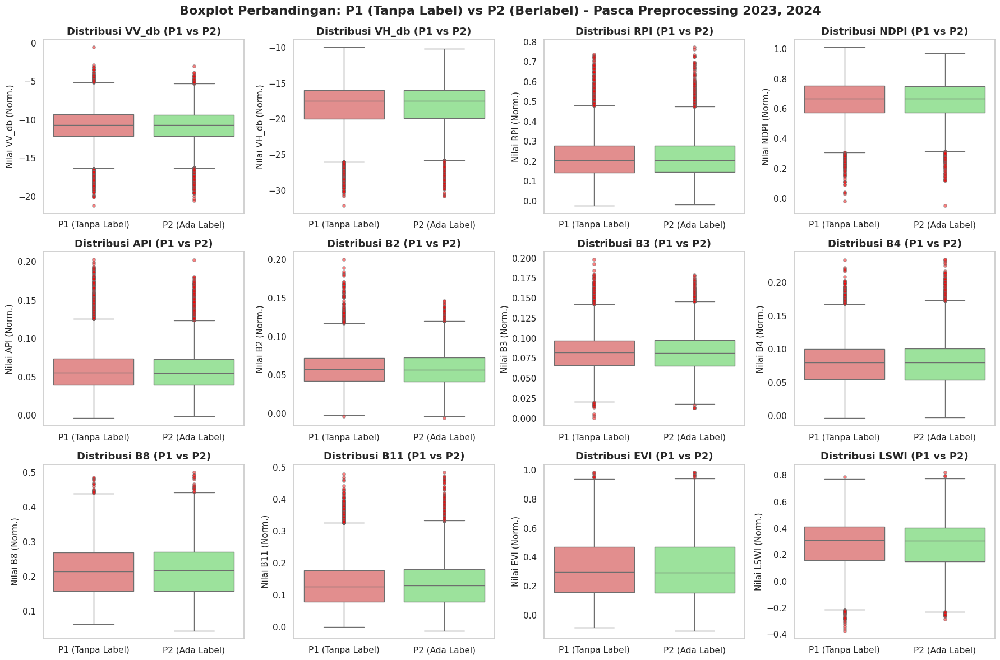

In [29]:
# ==============================================================================
# 9. BOXPLOT P1 (UNLABELED) VS P2 (LABELED)
# ==============================================================================
print("\n" + "="*80)
print("9. ANALISIS OUTLIER: PERBANDINGAN PERIODE P1 VS P2")
print("="*80)

df_p1_p2 = df_bersih_eval.copy()
df_p1_p2['Tipe_Periode'] = np.where(
    df_p1_p2['Label_Final'].isna(), 'P1 (Tanpa Label)', 'P2 (Ada Label)'
)

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
warna_periode = {'P1 (Tanpa Label)': 'lightcoral', 'P2 (Ada Label)': 'lightgreen'}

for i, fitur in enumerate(fitur_citra):
    sns.boxplot(data=df_p1_p2, x='Tipe_Periode', y=fitur, ax=axes[i],
                palette=warna_periode, hue='Tipe_Periode', legend=False,
                flierprops={'marker': 'o', 'markerfacecolor': 'red', 'markersize': 4, 'alpha': 0.5})
    axes[i].set_title(f'Distribusi {fitur} (P1 vs P2)', fontsize=13, fontweight='bold')
    axes[i].set_xlabel(''); axes[i].set_ylabel(f'Nilai {fitur} (Norm.)', fontsize=11)
    axes[i].grid(False)

plt.suptitle(
    f'Boxplot Perbandingan: P1 (Tanpa Label) vs P2 (Berlabel) - Pasca Preprocessing {teks_tahun}',
    fontsize=16, fontweight='bold', y=0.98
)
plt.tight_layout()
fig.subplots_adjust(top=0.93)
plt.show()


## *Analisis Boxplot time series berdasarkan label amatan KSA*


📦 10. ANALISIS TIME-SERIES: BOXPLOT DISTRIBUSI PER TIMESTEP & FASE KSA

Memproses grafik Boxplot Time-Series untuk fitur: VV_db...


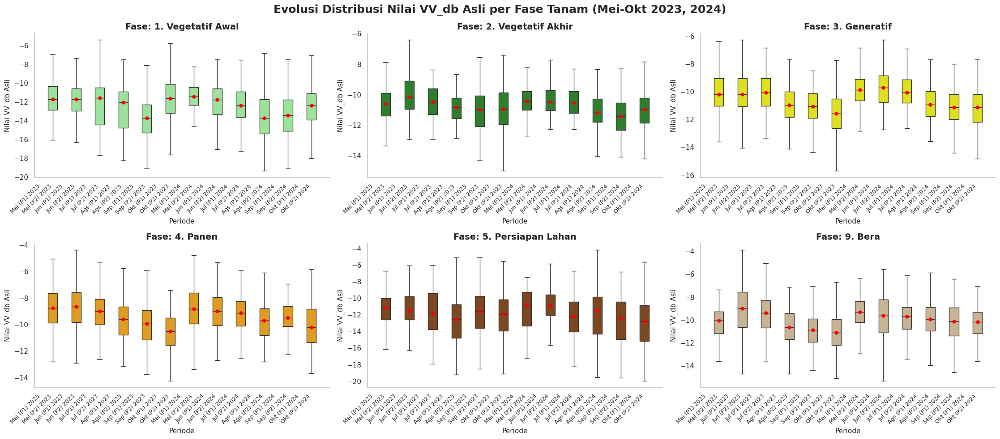


Memproses grafik Boxplot Time-Series untuk fitur: VH_db...


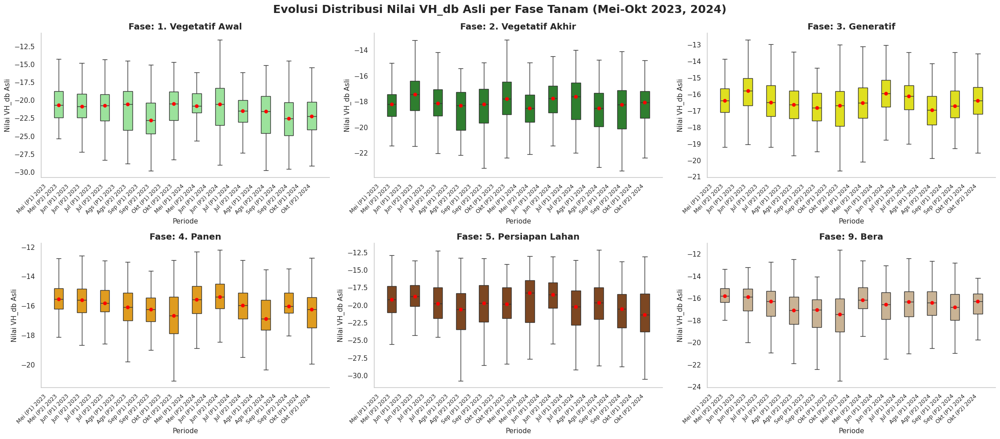


Memproses grafik Boxplot Time-Series untuk fitur: RPI...


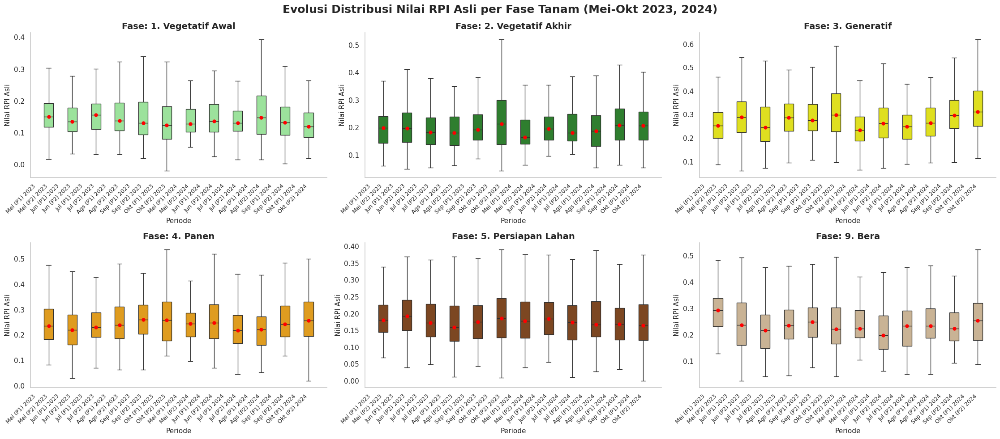


Memproses grafik Boxplot Time-Series untuk fitur: NDPI...


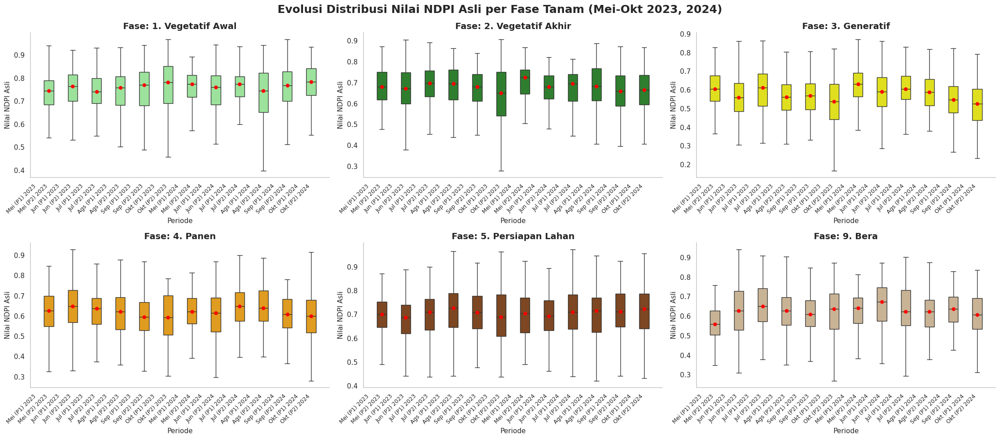


Memproses grafik Boxplot Time-Series untuk fitur: API...


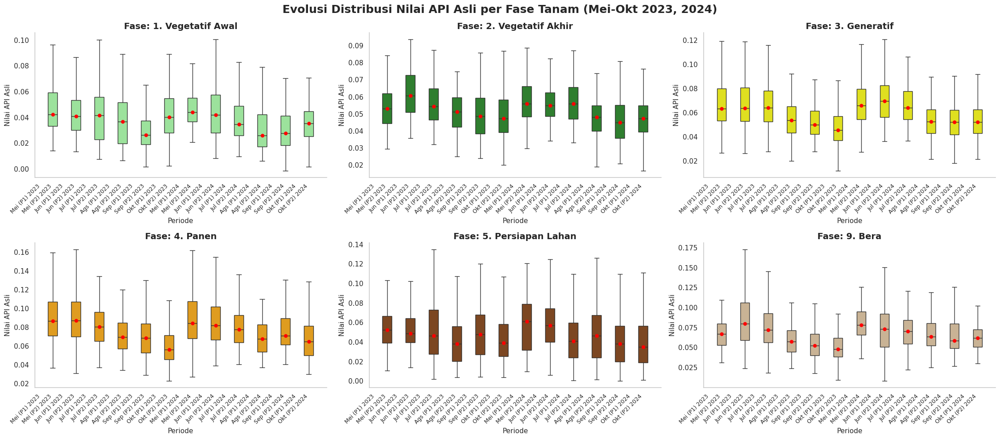


Memproses grafik Boxplot Time-Series untuk fitur: B2...


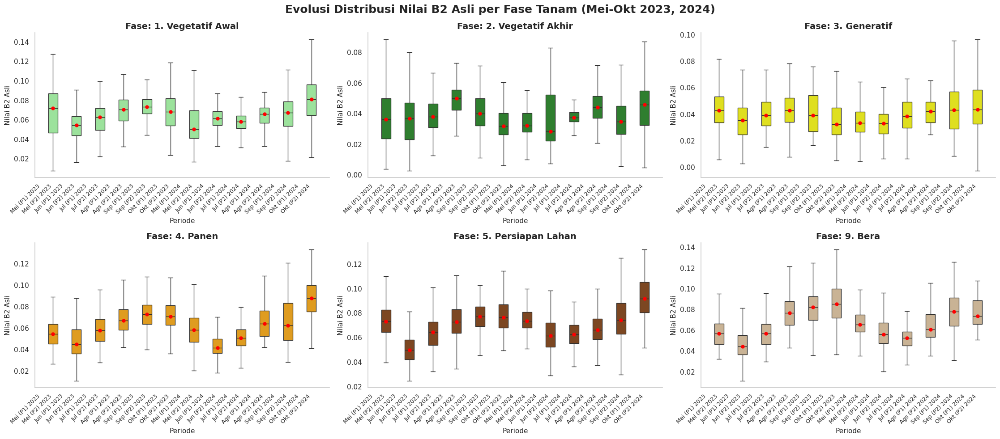


Memproses grafik Boxplot Time-Series untuk fitur: B3...


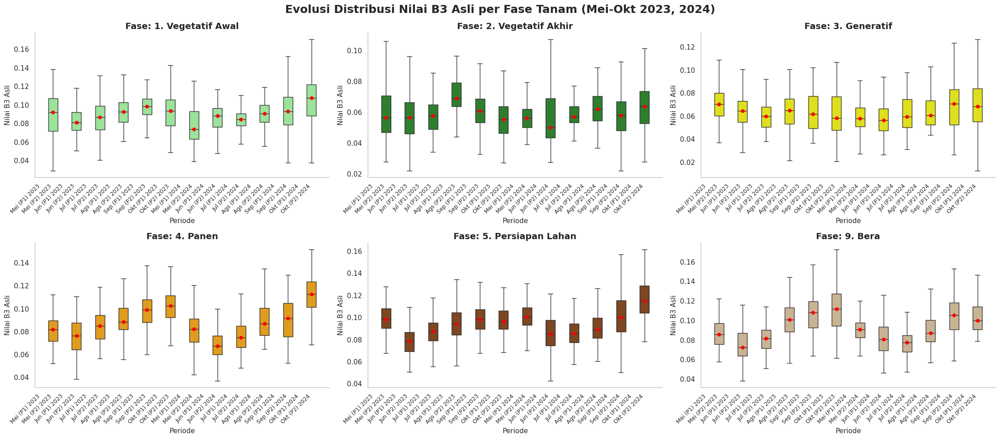


Memproses grafik Boxplot Time-Series untuk fitur: B4...


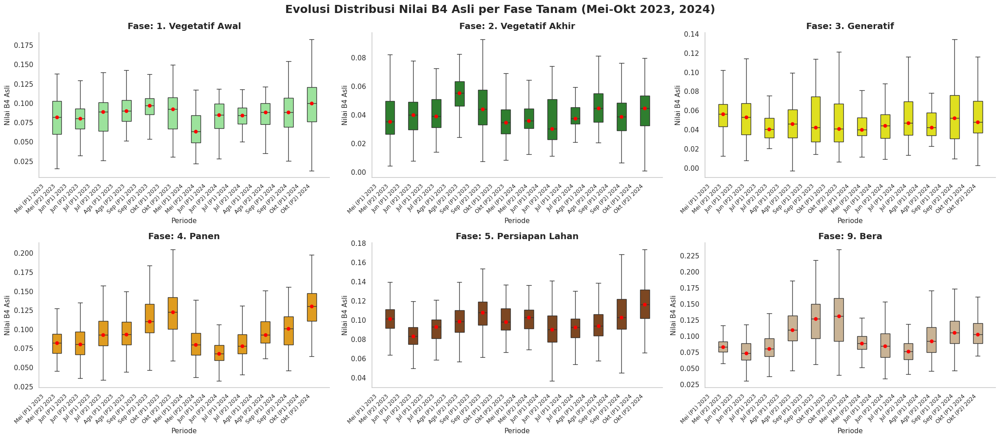


Memproses grafik Boxplot Time-Series untuk fitur: B8...


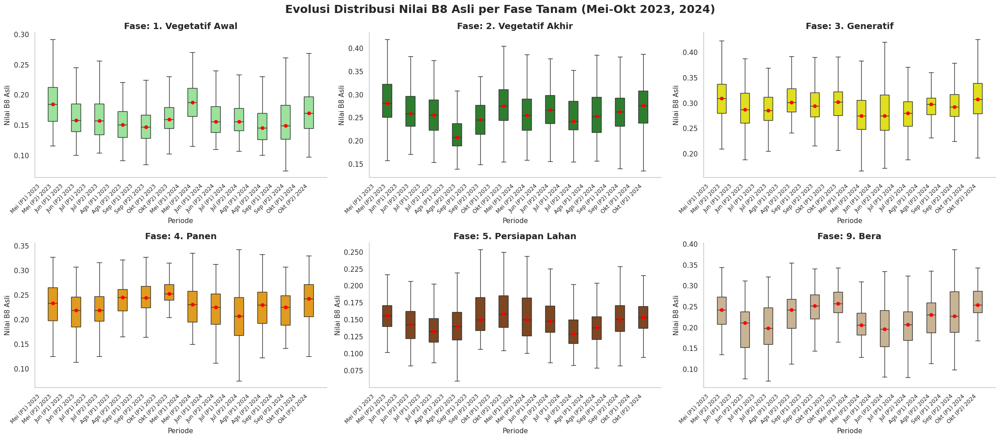


Memproses grafik Boxplot Time-Series untuk fitur: B11...


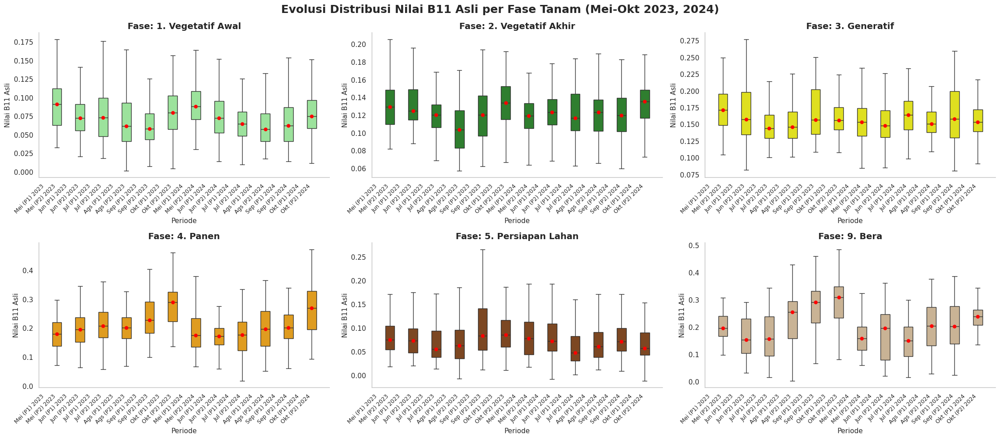


Memproses grafik Boxplot Time-Series untuk fitur: EVI...


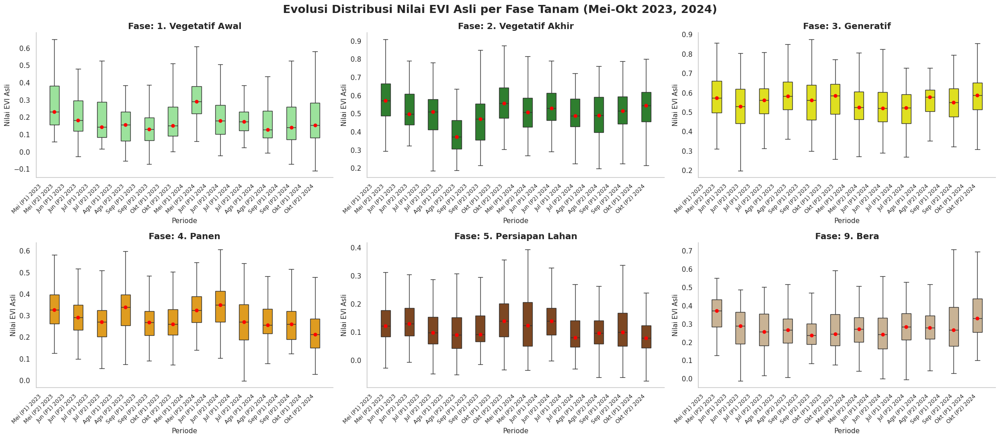


Memproses grafik Boxplot Time-Series untuk fitur: LSWI...


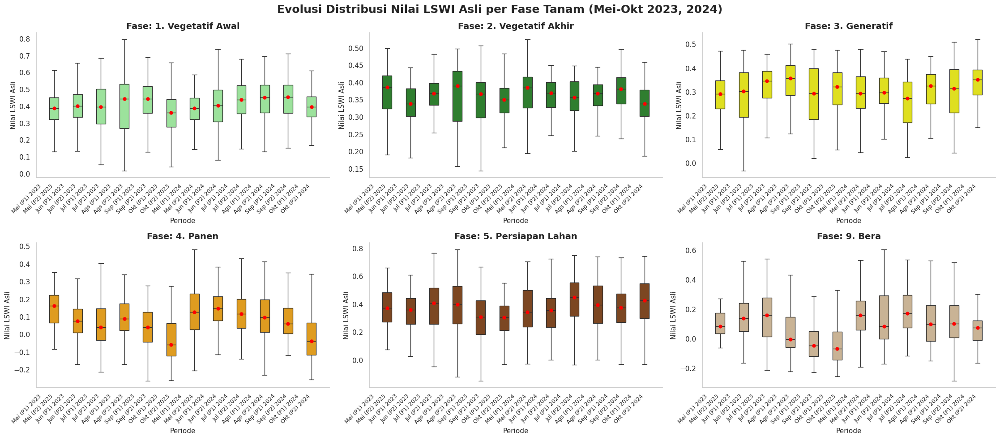

In [30]:
# ==============================================================================
# 10. ANALISIS TIME-SERIES: BOXPLOT DISTRIBUSI PER TIMESTEP & FASE KSA
# ==============================================================================
print("\n" + "="*80)
print("📦 10. ANALISIS TIME-SERIES: BOXPLOT DISTRIBUSI PER TIMESTEP & FASE KSA")
print("="*80)

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Persiapan Data (Menggunakan df_bersih_eval yang sudah di-smoothing)
df_ts_box = df_bersih_eval.dropna(subset=['Label_Final']).copy()
df_ts_box['Nama_Fase'] = pd.Categorical(df_ts_box['Label_Final'].map(label_map_baru), categories=kategori_valid_urutan, ordered=True)
df_ts_box = df_ts_box.dropna(subset=['Nama_Fase'])

# 2. Pembuatan Timestep (Bulan - Periode - Tahun)
bulan_dict_ts = {5: 'Mei', 6: 'Jun', 7: 'Jul', 8: 'Ags', 9: 'Sep', 10: 'Okt'}
df_ts_box['Timestep_Str'] = df_ts_box['Bulan'].map(bulan_dict_ts) + ' (P' + df_ts_box['Periode'].astype(str).str[-1] + ') ' + df_ts_box['Tahun'].astype(str)

# Menyusun urutan kronologis yang dinamis berdasarkan tahun yang tersedia
urutan_waktu = [f"{bln} (P{p}) {thn}" for thn in sorted(df_ts_box['Tahun'].unique()) for bln in ['Mei', 'Jun', 'Jul', 'Ags', 'Sep', 'Okt'] for p in [1, 2]]

df_ts_box['Timestep'] = pd.Categorical(df_ts_box['Timestep_Str'], categories=urutan_waktu, ordered=True)
df_ts_box = df_ts_box.sort_values(['Timestep', 'Nama_Fase'])

# 3. Visualisasi Grid Boxplot per Fitur Citra
for fitur in fitur_citra:
    print(f"\nMemproses grafik Boxplot Time-Series untuk fitur: {fitur}...")

    g = sns.catplot(
        data=df_ts_box,
        x='Timestep', y=fitur,
        col='Nama_Fase', hue='Nama_Fase',
        col_wrap=3, kind='box',
        palette=custom_palette_baru,
        showfliers=False, sharey=False, sharex=False,
        height=5, aspect=1.5, legend=False
    )

    g.figure.subplots_adjust(top=0.9, hspace=0.4, wspace=0.2)
    g.figure.suptitle(f'Evolusi Distribusi Nilai {fitur} Asli per Fase Tanam (Mei-Okt {teks_tahun})', fontsize=18, fontweight='bold')

    for ax in g.axes.flatten():
        # Judul & Label
        title = ax.get_title().split('Nama_Fase = ')[-1]
        ax.set_title(f'Fase: {title}', fontsize=14, fontweight='bold')
        ax.tick_params(labelbottom=True, labelleft=True)
        ax.set_xlabel('Periode', fontsize=11)
        ax.set_ylabel(f'Nilai {fitur} Asli', fontsize=11)

        # Plot Median (Garis Merah)
        median_vals = df_ts_box[df_ts_box['Nama_Fase'] == title].groupby('Timestep', observed=False)[fitur].median()
        ax.plot(range(len(median_vals)), median_vals.values, color='red', marker='o', linewidth=2, markersize=5, zorder=5)

        # Kosmetik Sumbu
        ax.tick_params(axis='x', labelrotation=45)
        for tick in ax.get_xticklabels():
            tick.set_ha('right')
            tick.set_fontsize(9)
        ax.grid(False)

    plt.tight_layout()
    plt.show()

## *Analisis Boxplot per fase Fitur*


🌟 11. MEMULAI ANALISIS DESKRIPTIF KARAKTERISTIK FASE (EDA)
-> Data yang dianalisis: Khusus Mei-Okt 2023, 2024 (Setelah Pembersihan Outlier)

--- A. TABEL STATISTIK DESKRIPTIF PER FITUR ---

=> Statistik Deskriptif untuk Fitur: VV_db Asli


,count,mean,std,min,25%,50%,75%,max
Nama_Fase,,,,,,,,
1. Vegetatif Awal,2494.0,-12.493,2.324,-19.352,-14.152,-12.376,-10.930,-5.055
2. Vegetatif Akhir,1726.0,-10.790,1.320,-16.106,-11.646,-10.776,-9.912,-5.512
3. Generatif,2695.0,-10.396,1.505,-15.705,-11.366,-10.409,-9.394,-5.124
4. Panen,2323.0,-9.245,1.658,-14.241,-10.333,-9.237,-8.208,-2.997
5. Persiapan Lahan,2695.0,-11.992,2.654,-20.552,-13.878,-11.716,-10.043,-4.149
9. Bera,1975.0,-10.108,1.821,-16.844,-11.375,-10.120,-8.894,-3.856



=> Statistik Deskriptif untuk Fitur: VH_db Asli


,count,mean,std,min,25%,50%,75%,max
Nama_Fase,,,,,,,,
1. Vegetatif Awal,2494.0,-21.531,2.981,-29.833,-23.632,-21.419,-19.379,-11.599
2. Vegetatif Akhir,1726.0,-18.230,1.784,-25.488,-19.356,-18.111,-16.993,-11.381
3. Generatif,2695.0,-16.386,1.285,-21.448,-17.250,-16.382,-15.526,-10.212
4. Panen,2323.0,-15.933,1.417,-22.497,-16.762,-15.852,-14.975,-11.627
5. Persiapan Lahan,2695.0,-20.009,3.219,-30.758,-22.171,-19.740,-17.531,-12.112
9. Bera,1975.0,-16.832,1.947,-26.682,-17.968,-16.539,-15.512,-11.610



=> Statistik Deskriptif untuk Fitur: RPI Asli


...


=> Statistik Deskriptif untuk Fitur: EVI Asli


,count,mean,std,min,25%,50%,75%,max
Nama_Fase,,,,,,,,
1. Vegetatif Awal,2494.0,0.192,0.129,-0.109,0.095,0.165,0.270,0.796
2. Vegetatif Akhir,1726.0,0.517,0.127,0.165,0.432,0.517,0.605,0.909
3. Generatif,2695.0,0.554,0.116,0.153,0.477,0.556,0.628,0.987
4. Panen,2323.0,0.292,0.101,-0.002,0.220,0.291,0.361,0.670
5. Persiapan Lahan,2695.0,0.121,0.088,-0.104,0.061,0.103,0.167,0.706
9. Bera,1975.0,0.277,0.114,-0.029,0.192,0.268,0.353,0.851



=> Statistik Deskriptif untuk Fitur: LSWI Asli


,count,mean,std,min,25%,50%,75%,max
Nama_Fase,,,,,,,,
1. Vegetatif Awal,2494.0,0.409,0.126,-0.051,0.334,0.417,0.495,0.797
2. Vegetatif Akhir,1726.0,0.356,0.067,-0.024,0.320,0.364,0.401,0.525
3. Generatif,2695.0,0.301,0.101,-0.093,0.238,0.314,0.380,0.522
4. Panen,2323.0,0.089,0.131,-0.262,-0.003,0.087,0.180,0.519
5. Persiapan Lahan,2695.0,0.371,0.169,-0.256,0.258,0.380,0.496,0.823
9. Bera,1975.0,0.086,0.169,-0.286,-0.046,0.065,0.210,0.687



--- B. VISUALISASI BOXPLOT DISTRIBUSI FITUR PER FASE ---


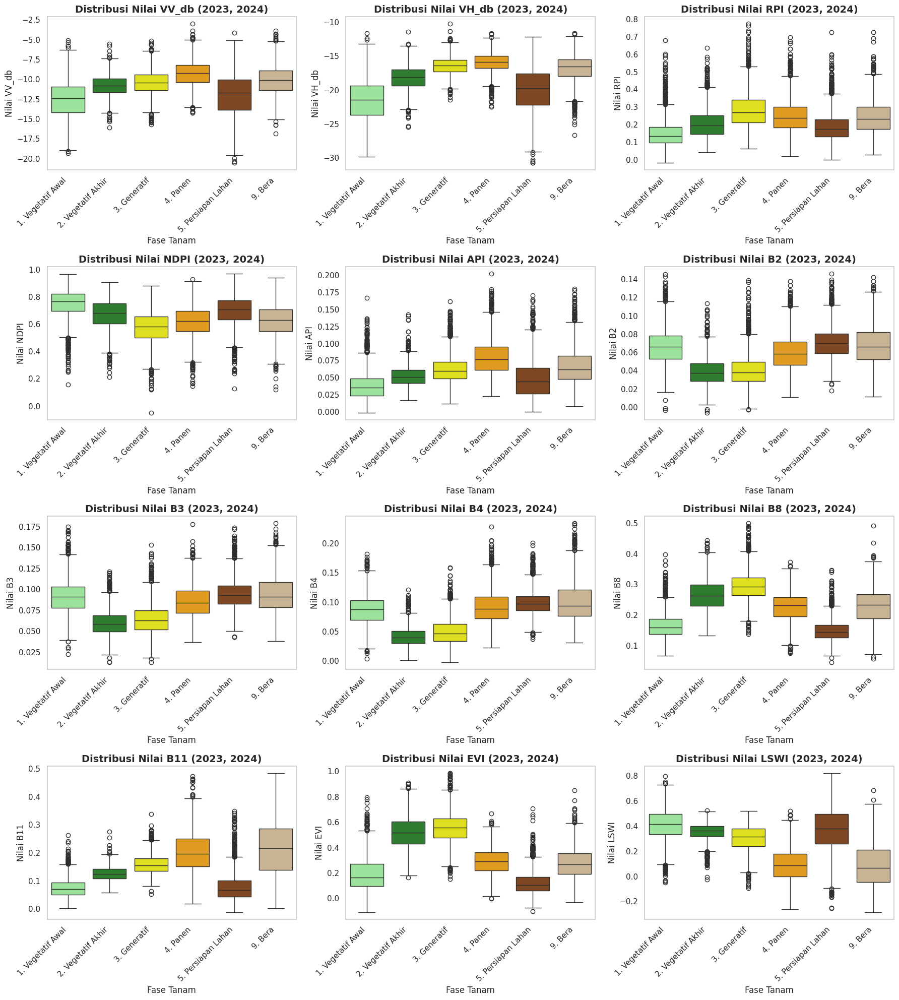


📈 12. MEMULAI ANALISIS TIME-SERIES (KURVA FENOLOGI TIMESTEP)


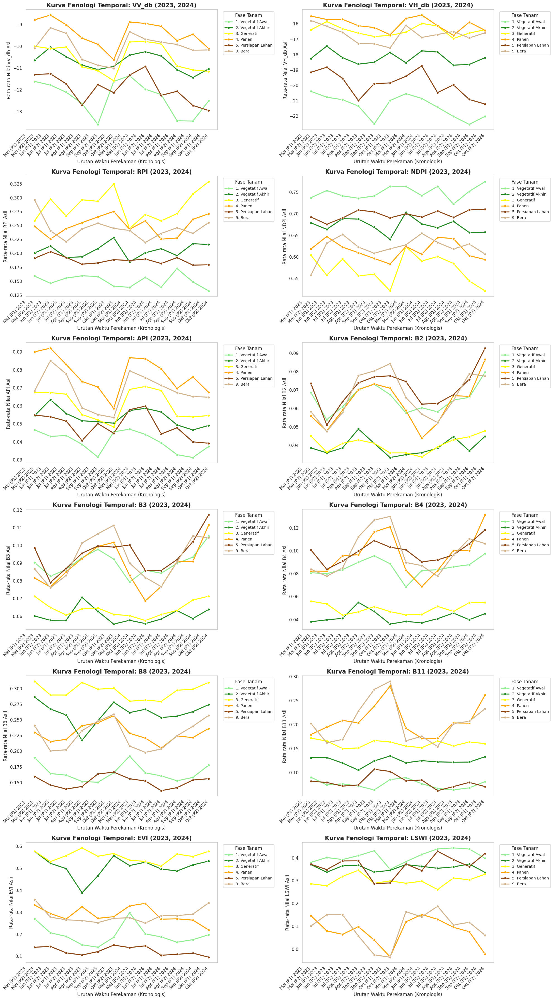

In [31]:
import math

# ==============================================================================
# 11. ANALISIS DESKRIPTIF & BOXPLOT (PER FASE PER FITUR - SKALA ASLI)
# ==============================================================================
print("\n" + "="*80)
print("🌟 11. MEMULAI ANALISIS DESKRIPTIF KARAKTERISTIK FASE (EDA)")
print("="*80)

# 1. Persiapan Data Bersih (Menggunakan df_bersih_eval)
df_analisis_fase = df_bersih_eval.dropna(subset=['Label_Final']).copy()
df_analisis_fase['Nama_Fase'] = pd.Categorical(df_analisis_fase['Label_Final'].map(label_map_baru), categories=kategori_valid_urutan, ordered=True)
df_analisis_fase = df_analisis_fase.dropna(subset=['Nama_Fase'])

print(f"-> Data yang dianalisis: Khusus Mei-Okt {teks_tahun} (Setelah Pembersihan Outlier)")

# --- A. STATISTIK DESKRIPTIF PER FITUR ---
print("\n--- A. TABEL STATISTIK DESKRIPTIF PER FITUR ---")
for col in fitur_citra:
    print(f"\n=> Statistik Deskriptif untuk Fitur: {col} Asli")
    stat_tabel = df_analisis_fase.groupby('Nama_Fase', observed=False)[col].describe().round(3)
    display(stat_tabel)


# --- B. VISUALISASI BOXPLOT DISTRIBUSI ---
print("\n--- B. VISUALISASI BOXPLOT DISTRIBUSI FITUR PER FASE ---")
n_cols = 3
n_rows = math.ceil(len(fitur_citra) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, col in enumerate(fitur_citra):
    sns.boxplot(
        data=df_analisis_fase, x='Nama_Fase', y=col,
        ax=axes[i], order=kategori_valid_urutan,
        palette=custom_palette_baru, hue='Nama_Fase',
        showfliers=True, legend=False
    )
    axes[i].set_title(f'Distribusi Nilai {col} ({teks_tahun})', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('Fase Tanam', fontsize=12)
    axes[i].set_ylabel(f'Nilai {col}', fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)

    for tick in axes[i].get_xticklabels():
        tick.set_ha('right')

    axes[i].grid(False)

for j in range(len(fitur_citra), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# ==============================================================================
# 12. ANALISIS TIME-SERIES (KURVA FENOLOGI DINAMIS 2023 & 2024)
# ==============================================================================
print("\n" + "="*80)
print("📈 12. MEMULAI ANALISIS TIME-SERIES (KURVA FENOLOGI TIMESTEP)")
print("="*80)

# Gunakan data df_ts_box yang sudah memiliki Timestep Categorical terurut dari Tahap 10
df_analisis_ts = df_ts_box.copy()

# VISUALISASI GRID MULTI-PLOT PER FITUR
n_cols_ts = 2
n_rows_ts = math.ceil(len(fitur_citra) / n_cols_ts)
fig, axes = plt.subplots(n_rows_ts, n_cols_ts, figsize=(20, 6 * n_rows_ts))
axes = axes.flatten()

for i, col in enumerate(fitur_citra):
    sns.lineplot(
        data=df_analisis_ts, x='Timestep', y=col,
        hue='Nama_Fase', ax=axes[i],
        palette=custom_palette_baru, hue_order=kategori_valid_urutan,
        marker='o', linewidth=2.5, errorbar=None
    )
    axes[i].set_title(f'Kurva Fenologi Temporal: {col} ({teks_tahun})', fontsize=15, fontweight='bold')
    axes[i].set_xlabel('Urutan Waktu Perekaman (Kronologis)', fontsize=12)
    axes[i].set_ylabel(f'Rata-rata Nilai {col} Asli', fontsize=12)
    axes[i].grid(False)

    axes[i].tick_params(axis='x', rotation=45)
    for tick in axes[i].get_xticklabels():
        tick.set_ha('right')

    axes[i].legend(title='Fase Tanam', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)

for j in range(len(fitur_citra), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

*Uji Kruskall Walis*


🔬 9. UJI STATISTIK BEDA NYATA ANTAR KELAS (Data Bersih - Kruskal-Wallis & Dunn's)
Total data dievaluasi: 13908 baris
Tingkat Signifikansi (Alpha) = 0.05


------------------------------------------------------------
▶ FITUR: VV_db
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2432.38, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


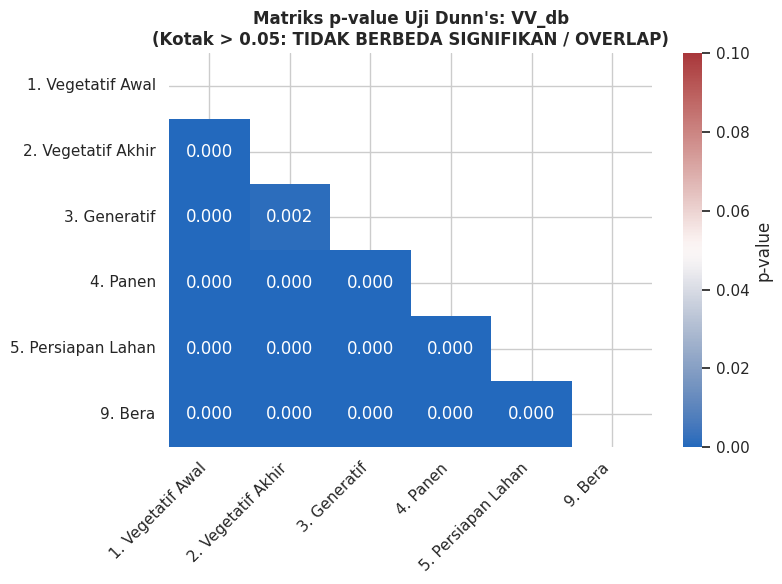


------------------------------------------------------------
▶ FITUR: VH_db
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 5328.32, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


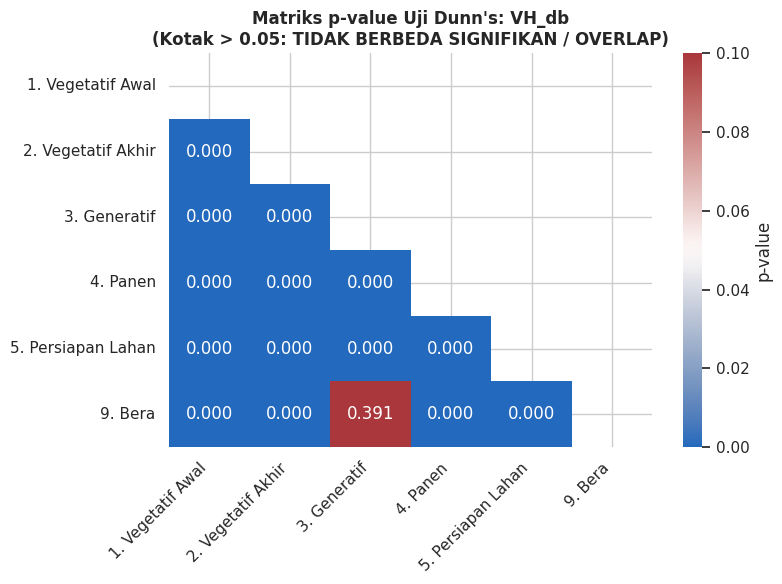


------------------------------------------------------------
▶ FITUR: RPI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2290.38, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


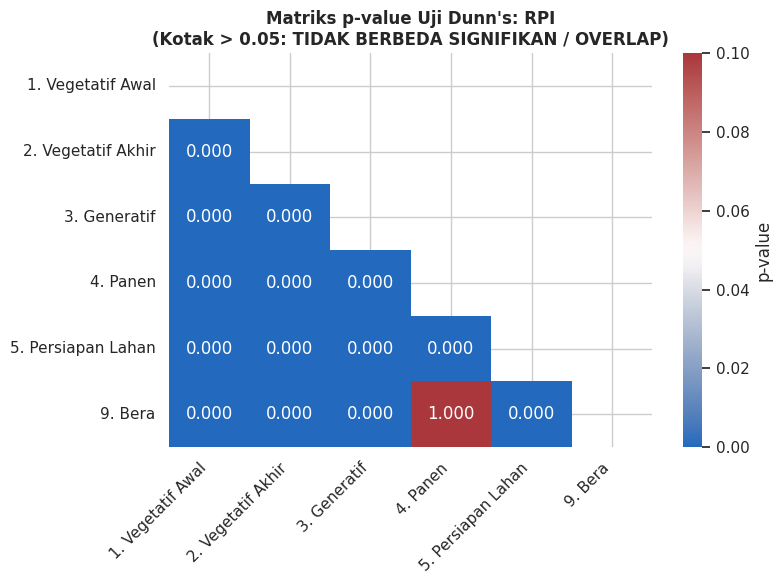


------------------------------------------------------------
▶ FITUR: NDPI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 2288.35, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


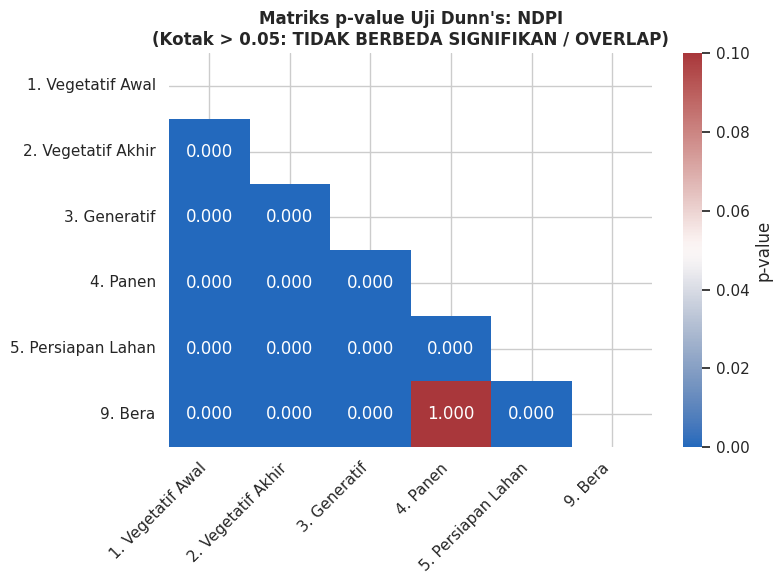


------------------------------------------------------------
▶ FITUR: API
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 3213.94, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


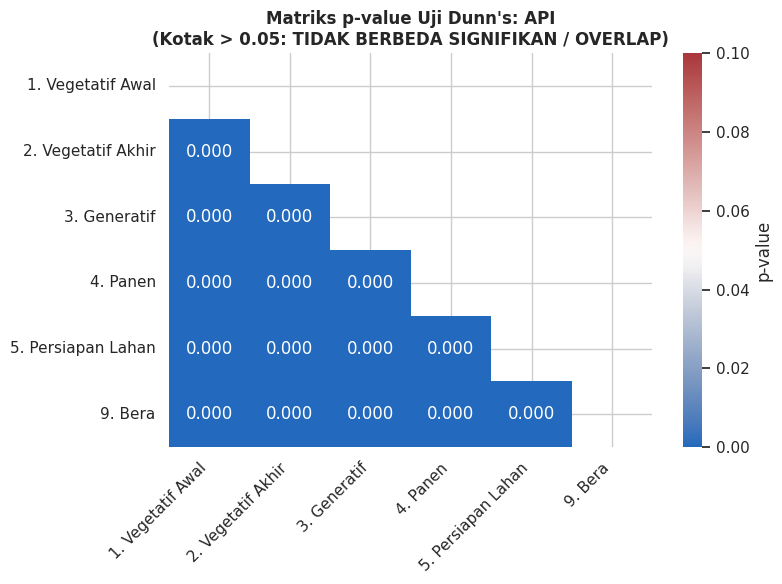


------------------------------------------------------------
▶ FITUR: B2
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 4696.46, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


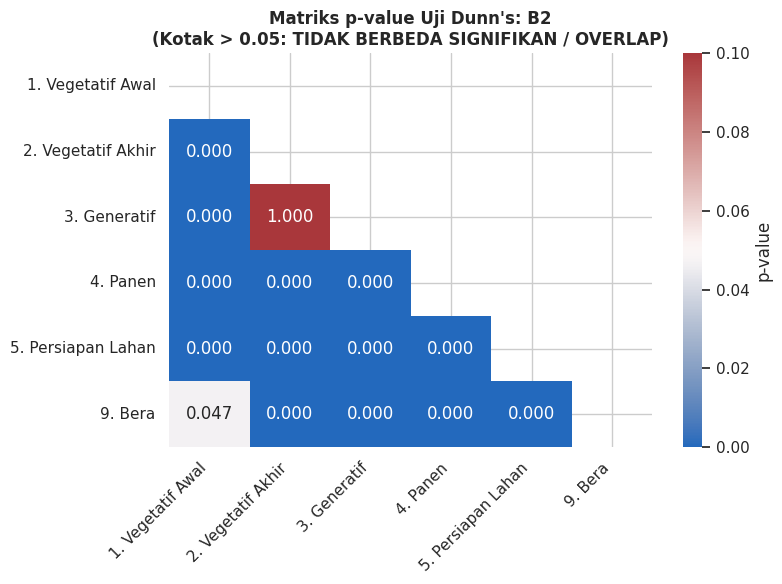


------------------------------------------------------------
▶ FITUR: B3
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 5027.52, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


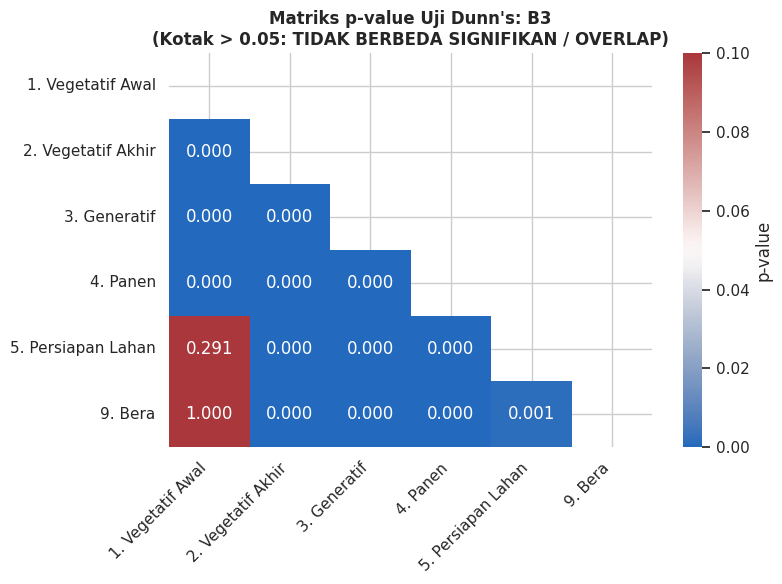


------------------------------------------------------------
▶ FITUR: B4
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 6801.93, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


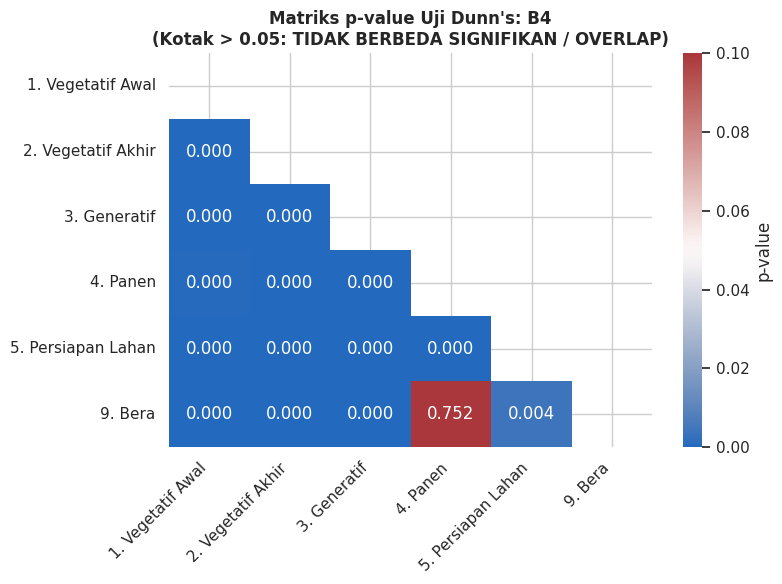


------------------------------------------------------------
▶ FITUR: B8
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 8151.08, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


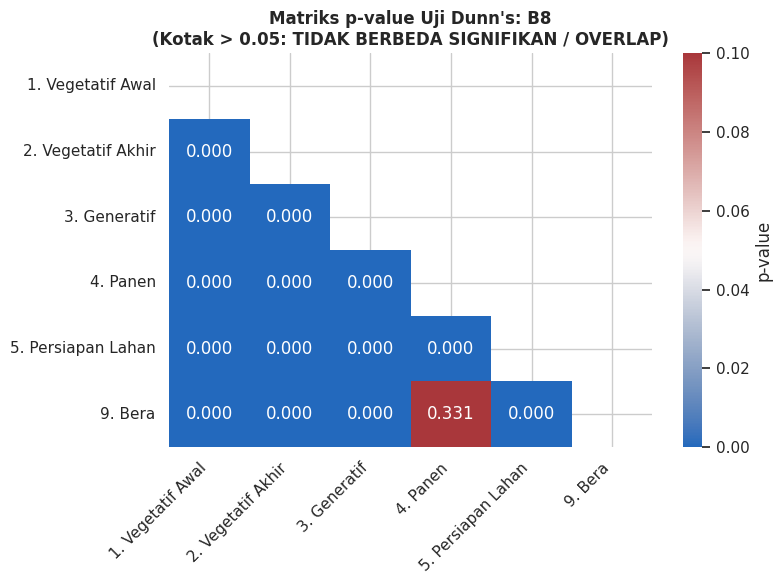


------------------------------------------------------------
▶ FITUR: B11
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 7364.17, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


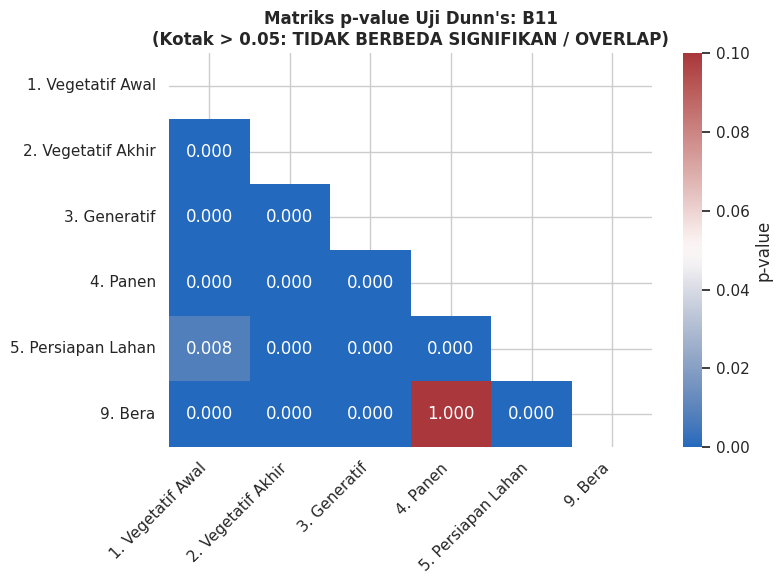


------------------------------------------------------------
▶ FITUR: EVI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 9357.35, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


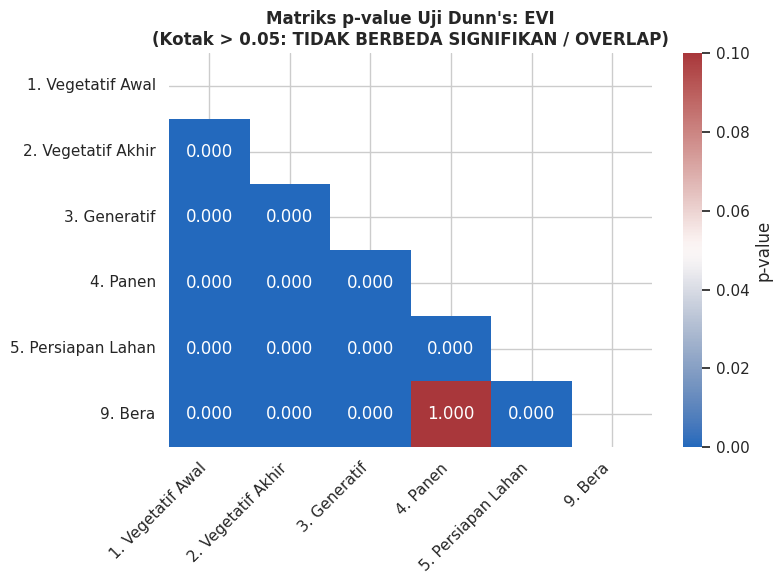


------------------------------------------------------------
▶ FITUR: LSWI
------------------------------------------------------------
Hasil Kruskal-Wallis -> Statistik H: 6407.06, p-value: 0.0000e+00
Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...


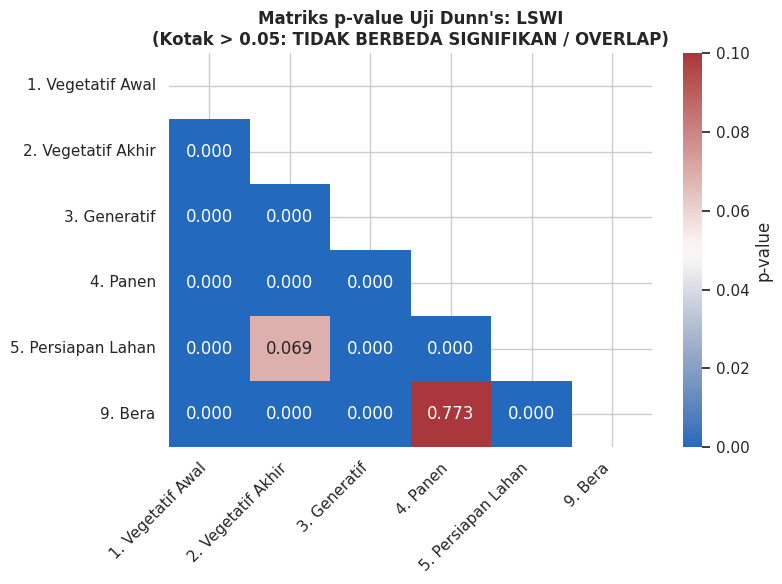

In [32]:
# ==============================================================================
# 9. EKSPERIMEN STATISTIK: UJI KRUSKAL-WALLIS & UJI DUNN'S (DATA BERSIH)
# ==============================================================================
import scipy.stats as stats
import scikit_posthocs as sp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("\n" + "="*80)
print("🔬 9. UJI STATISTIK BEDA NYATA ANTAR KELAS (Data Bersih - Kruskal-Wallis & Dunn's)")
print("="*80)

# 1. PERSIAPAN DATA
# Gunakan df hasil preparation (misal: df_bersih atau data khusus Train set agar tidak ada leakage)
# Pastikan data ini diambil SEBELUM dilakukan Min-Max Normalization.
df_stat = df_bersih.dropna(subset=['Label_Final']).copy()

# Petakan ke nama fase menggunakan kamus (dictionary) yang baru
df_stat['Nama_Fase'] = df_stat['Label_Final'].map(label_map_baru)
df_stat = df_stat.dropna(subset=['Nama_Fase'])

# Gunakan urutan kategori yang sudah digabung (kategori_valid_urutan)
df_stat['Nama_Fase'] = pd.Categorical(df_stat['Nama_Fase'], categories=kategori_valid_urutan, ordered=True)

print(f"Total data dievaluasi: {len(df_stat)} baris")
print("Tingkat Signifikansi (Alpha) = 0.05\n")

# 2. LOOPING UJI STATISTIK UNTUK SETIAP FITUR
for fitur in fitur_citra:
    if fitur not in df_stat.columns:
        continue

    print(f"\n" + "-"*60)
    print(f"▶ FITUR: {fitur}")
    print("-"*60)

    # Kumpulkan array data untuk masing-masing kelas yang tidak kosong
    grup_data = []
    nama_grup_valid = []
    for nama_fase, grup in df_stat.groupby('Nama_Fase', observed=True):
        data_fitur = grup[fitur].dropna().values
        if len(data_fitur) > 0:
            grup_data.append(data_fitur)
            nama_grup_valid.append(nama_fase)

    # UJI 1: KRUSKAL-WALLIS
    # H0: Semua kelompok memiliki distribusi median yang sama
    # H1: Setidaknya ada satu kelompok yang berbeda
    stat_kw, pval_kw = stats.kruskal(*grup_data)

    print(f"Hasil Kruskal-Wallis -> Statistik H: {stat_kw:.2f}, p-value: {pval_kw:.4e}")

    if pval_kw < 0.05:
        print("Kesimpulan: Terdapat perbedaan signifikan antar fase (p < 0.05). Melanjutkan ke Uji Post-Hoc Dunn's...")

        # UJI 2: DUNN'S POST-HOC TEST DENGAN KOREKSI BONFERRONI
        # Melakukan perbandingan pasangan (pairwise) antar semua fase yang ada
        hasil_posthoc = sp.posthoc_dunn(df_stat, val_col=fitur, group_col='Nama_Fase', p_adjust='bonferroni')

        # Visualisasi menggunakan Heatmap
        plt.figure(figsize=(8, 6))

        # Masking untuk menyembunyikan segitiga atas (karena matriksnya simetris)
        mask = np.triu(np.ones_like(hasil_posthoc, dtype=bool))

        sns.heatmap(
            hasil_posthoc,
            mask=mask,
            annot=True,
            fmt=".3f",
            cmap="vlag",    # Biru/Gelap untuk signifikan, Merah/Terang untuk tidak signifikan
            vmin=0,
            vmax=0.1,       # Memusatkan rentang warna di sekitar 0.05
            cbar_kws={'label': 'p-value'}
        )

        plt.title(f'Matriks p-value Uji Dunn\'s: {fitur}\n(Kotak > 0.05: TIDAK BERBEDA SIGNIFIKAN / OVERLAP)',
                  fontsize=12, fontweight='bold')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    else:
        print("Kesimpulan: TIDAK ada perbedaan signifikan antar kelas (p >= 0.05). Uji Post-Hoc tidak diperlukan.")

# **6. Min-Max Normalization (Anti-Leakage: Fit hanya pada Train)**

In [33]:
from sklearn.preprocessing import MinMaxScaler

# ==============================================================================
# TAHAP 6: MIN-MAX NORMALIZATION
# MinMaxScaler di-fit HANYA menggunakan data Train.
# Setelah scaler didapat, baru di-transform ke Train, Val, Test.
# ==============================================================================
print("="*60)
print("TAHAP 6: MIN-MAX NORMALIZATION (Fit dari Train saja)")
print("="*60 + "\n")

# --- 1. FIT: Latih scaler dari data TRAIN saja ---
fitted_scaler = MinMaxScaler()
fitted_scaler.fit(df_train[fitur_citra])
print("[FIT] MinMaxScaler berhasil di-fit pada data TRAIN.")
print(f"Fitur yang dinormalisasi: {fitur_citra}")

# --- 2. TRANSFORM: Terapkan ke Train, Val, Test ---
df_train[fitur_citra] = fitted_scaler.transform(df_train[fitur_citra])
df_val[fitur_citra]   = fitted_scaler.transform(df_val[fitur_citra])
df_test[fitur_citra]  = fitted_scaler.transform(df_test[fitur_citra])

print("[TRANSFORM] Normalisasi berhasil diterapkan ke Train, Val, dan Test.")
print()

# Cek rentang nilai setelah normalisasi (Train harus [0, 1])
print("Cek rentang nilai pada data TRAIN (harus mendekati 0 & 1):")
for fitur in fitur_citra:
    mn = df_train[fitur].min()
    mx = df_train[fitur].max()
    print(f"{fitur:<8}: Min={mn:.4f}  Max={mx:.4f}")

print("\nNormalisasi Selesai!")

TAHAP 6: MIN-MAX NORMALIZATION (Fit dari Train saja)

[FIT] MinMaxScaler berhasil di-fit pada data TRAIN.
Fitur yang dinormalisasi: ['VV_db', 'VH_db', 'RPI', 'NDPI', 'API', 'B2', 'B3', 'B4', 'B8', 'B11', 'EVI', 'LSWI']
[TRANSFORM] Normalisasi berhasil diterapkan ke Train, Val, dan Test.

Cek rentang nilai pada data TRAIN (harus mendekati 0 & 1):
VV_db   : Min=0.0000  Max=1.0000
VH_db   : Min=0.0000  Max=1.0000
RPI     : Min=0.0000  Max=1.0000
NDPI    : Min=0.0000  Max=1.0000
API     : Min=0.0000  Max=1.0000
B2      : Min=0.0000  Max=1.0000
B3      : Min=0.0000  Max=1.0000
B4      : Min=0.0000  Max=1.0000
B8      : Min=0.0000  Max=1.0000
B11     : Min=0.0000  Max=1.0000
EVI     : Min=0.0000  Max=1.0000
LSWI    : Min=0.0000  Max=1.0000

Normalisasi Selesai!


# **Output: Konversi ke Array 3D & Ekspor untuk Model**

In [34]:
# ==============================================================================
# TAHAP AKHIR: KONVERSI KE FORMAT ARRAY 3D (12 TIMESTEP) & EKSPOR
# ==============================================================================
import os
import numpy as np
from tensorflow.keras.utils import to_categorical
import os, gc, time, random, pickle, joblib

print("="*60)
print("TAHAP AKHIR: KONVERSI 3D & EKSPOR DATA")
print("="*60)

# Konfigurasi
FEATURES     = ['VV_db', 'VH_db', 'RPI', 'NDPI', 'API',
                'B2', 'B3', 'B4', 'B8', 'B11', 'EVI', 'LSWI']
LABEL_COL    = 'Label_Final'
VALID_LABELS = [1, 2, 3, 4, 5, 9]
LABEL_MAPPING = {9: 6}
NUM_CLASSES  = 6

NPY_DIR = '/content/drive/MyDrive/Skripsi/04. Data Ready Bi-LSTM/Split_NPY_v2'
os.makedirs(NPY_DIR, exist_ok=True)

def df_to_3d(df_split, split_name=''):
    """Konversi DataFrame 2D ke array 3D (samples, 12 timesteps, features)."""
    df_s = df_split.copy()
    df_s['Sequence_ID'] = (
        df_s['TitikAmatX'].astype(str) + '_' +
        df_s['TitikAmatY'].astype(str) + '_' +
        df_s['Tahun'].astype(str)
    )
    df_s = df_s.sort_values(['Sequence_ID', 'Tanggal']).reset_index(drop=True)

    X_list, y_list, seq_ids = [], [], []
    for seq_id, group in df_s.groupby('Sequence_ID', sort=False):
        if len(group) == 12:
            X_list.append(group[FEATURES].values)
            y_list.append(group[LABEL_COL].values)
            seq_ids.append(seq_id)

    X_3d    = np.array(X_list)          # (N, 12, n_features)
    y_2d    = np.array(y_list)          # (N, 12)
    seq_ids = np.array(seq_ids)

    # Ambil hanya timestep P2 (indeks ganjil: 1, 3, 5, 7, 9, 11)
    y_final = y_2d[:, 1::2]            # (N, 6)

    # Filter: hapus sampel yang memiliki NaN di label P2
    nan_mask    = ~np.isnan(y_final).any(axis=1)
    X_3d, y_final, seq_ids = X_3d[nan_mask], y_final[nan_mask], seq_ids[nan_mask]

    # Filter: hanya kelas yang valid
    valid_mask  = np.isin(y_final, VALID_LABELS).all(axis=1)
    X_3d, y_final, seq_ids = X_3d[valid_mask], y_final[valid_mask], seq_ids[valid_mask]

    # Re-mapping label (label 9 -> 6)
    for old_lbl, new_lbl in LABEL_MAPPING.items():
        y_final[y_final == old_lbl] = new_lbl

    y_final = y_final.astype(int)
    y_hot   = to_categorical(y_final - 1, num_classes=NUM_CLASSES)  # (N, 6, 6)

    n_samples = len(X_3d)
    print(f"   [{split_name}] {n_samples} sampel | Shape X: {X_3d.shape} | Shape y: {y_hot.shape}")

    # Verifikasi konsistensi 12 timestep
    if n_samples > 0:
        assert X_3d.shape[1] == 12, f"Dimensi timestep bukan 12! ({X_3d.shape[1]})"
    return X_3d, y_hot

# Konversi setiap split
print("Mengkonversi DataFrame ke Array 3D:")
X_train_3d, y_train_3d = df_to_3d(df_train, 'TRAIN')
X_val_3d,   y_val_3d   = df_to_3d(df_val,   'VAL')
X_test_3d,  y_test_3d  = df_to_3d(df_test,  'TEST')

# Simpan array ke .npy
np.save(os.path.join(NPY_DIR, 'X_train.npy'), X_train_3d)
np.save(os.path.join(NPY_DIR, 'X_val.npy'),   X_val_3d)
np.save(os.path.join(NPY_DIR, 'X_test.npy'),  X_test_3d)
np.save(os.path.join(NPY_DIR, 'y_train.npy'), y_train_3d)
np.save(os.path.join(NPY_DIR, 'y_val.npy'),   y_val_3d)
np.save(os.path.join(NPY_DIR, 'y_test.npy'),  y_test_3d)

# Simpan scaler agar bisa digunakan ulang (misal: inferensi)
joblib.dump(fitted_scaler, os.path.join(NPY_DIR, 'scaler.joblib'))

print(f"\n✅ Semua file berhasil disimpan di: {NPY_DIR}")
print("   File yang tersimpan:")
for fname in ['X_train.npy', 'X_val.npy', 'X_test.npy',
              'y_train.npy', 'y_val.npy', 'y_test.npy', 'scaler.joblib']:
    fpath = os.path.join(NPY_DIR, fname)
    print(f"-{fname}")

# Ringkasan akhir
total = len(X_train_3d) + len(X_val_3d) + len(X_test_3d)
print(f"\n=== RAPOR DATA FINAL UNTUK BI-LSTM ===")
print(f"{'Set':<12} | {'Sampel':<8} | {'Persen':<8} | {'Shape X':<20} | {'Shape y'}")
print(f"{'-'*75}")
for name, X, y in [('Training', X_train_3d, y_train_3d),
                   ('Validation', X_val_3d, y_val_3d),
                   ('Testing', X_test_3d, y_test_3d)]:
    print(f"{name:<12} | {len(X):<8} | {len(X)/total:<8.1%} | {str(X.shape):<20} | {y.shape}")
print(f"{'-'*75}")
print(f"Total      : {total} sampel")
print(f"Fitur      : {len(FEATURES)} ({', '.join(FEATURES)})")
print(f"Timestep   : 12 (P1 + P2, 6 bulan x 2 periode)")
print(f"Output     : {NUM_CLASSES} kelas | {y_train_3d.shape[1]} prediksi per sampel (P2 saja)")
print(f"\nData siap di-load oleh file Modeling!")


TAHAP AKHIR: KONVERSI 3D & EKSPOR DATA
Mengkonversi DataFrame ke Array 3D:
   [TRAIN] 1856 sampel | Shape X: (1856, 12, 12) | Shape y: (1856, 6, 6)
   [VAL] 231 sampel | Shape X: (231, 12, 12) | Shape y: (231, 6, 6)
   [TEST] 231 sampel | Shape X: (231, 12, 12) | Shape y: (231, 6, 6)

✅ Semua file berhasil disimpan di: /content/drive/MyDrive/Skripsi/04. Data Ready Bi-LSTM/Split_NPY_v2
   File yang tersimpan:
-X_train.npy
-X_val.npy
-X_test.npy
-y_train.npy
-y_val.npy
-y_test.npy
-scaler.joblib

=== RAPOR DATA FINAL UNTUK BI-LSTM ===
Set          | Sampel   | Persen   | Shape X              | Shape y
---------------------------------------------------------------------------
Training     | 1856     | 80.1%    | (1856, 12, 12)       | (1856, 6, 6)
Validation   | 231      | 10.0%    | (231, 12, 12)        | (231, 6, 6)
Testing      | 231      | 10.0%    | (231, 12, 12)        | (231, 6, 6)
---------------------------------------------------------------------------
Total      : 2318 sampel